![imagen](./img/ejercicios.png)

# INFORMACIÓN DEL PROYECTO

### TÍTULO

Evolución del rendimiento individual y colectivo en el Tour de Francia (2007–2026)

### TEMA

Análisis exploratorio de datos sobre la evolución del rendimiento deportivo de los ciclistas y los equipos participantes en el Tour de Francia durante los últimos 20 años, considerando los resultados de la clasificación general, los tiempos de carrera, las diferencias entre posiciones y la presencia de equipos en el top 10.

### HIPÓTESIS

El rendimiento individual y colectivo en el Tour de Francia ha experimentado cambios significativos durante el periodo 2007–2026, reflejados en la evolución de los tiempos de carrera, las diferencias entre los primeros puestos y la competitividad de los equipos participantes.

HIPOTESIS SECUNDARIAS

Las organizaría en tres dimensiones:

A. RENDIMINETO INDIVIDUAL
- H1: La velocidad media de los ganadores del Tour de Francia presenta una tendencia creciente durante el periodo estudiado.
- H2: Las diferencias de tiempo entre los diez primeros ciclistas han experimentado variaciones a lo largo de las ediciones.
- H3: La edad de los ciclistas que alcanzan los primeros diez puestos presenta patrones identificables durante el periodo analizado.
- H4: Algunos ciclistas han demostrado mayor regularidad competitiva al aparecer reiteradamente entre los diez primeros.


B. RENDIMINETO COLECTIVO
- H5: La presencia de determinados equipos entre los diez primeros puestos se concentra en un grupo reducido de estructuras deportivas.
- H6: Algunos equipos han mantenido una mayor continuidad competitiva durante las dos décadas estudiadas.
- H7: Determinados equipos han conseguido posicionar simultáneamente a varios corredores entre los diez primeros.


C. EVOLUCION COMPETITIVA

- H8: Existen diferencias en los indicadores de rendimiento deportivo entre las ediciones de 2007–2016 y 2017–2026.

## OBTENCIÓN DE LOS DATOS

### DATASETS Y FUENTES ALTERNATIVAS DE DATOS

Incluye aquí una vista del dataset o datasets de los que partirás para poder evaluar tu hipótesis. <br>
También incluye el origen de estos datos y su fuente.

In [121]:
import pandas as pd
import requests
from io import StringIO
url_ciclistas = "https://raw.githubusercontent.com/thomascamminady/LeTourDataSet/master/data/men/TDF_Riders_History.csv"

url_etapas = "https://raw.githubusercontent.com/thomascamminady/LeTourDataSet/master/data/men/TDF_Stages_History.csv"

# Descarga de los archivos
respuesta_ciclistas = requests.get(url_ciclistas, timeout=30)
respuesta_etapas = requests.get(url_etapas, timeout=30)

respuesta_ciclistas.raise_for_status()
respuesta_etapas.raise_for_status()

# Carga de los datos
ciclistas = pd.read_csv(StringIO(respuesta_ciclistas.text))
etapas = pd.read_csv(StringIO(respuesta_etapas.text))

print("Datasets cargados correctamente")

Datasets cargados correctamente


Revisamos las columnas del dataset de ciclistas

In [122]:
# Revisar las columnas del dataset de ciclistas

print("COLUMNAS DEL DATASET DE CICLISTAS:")
print(ciclistas.columns.tolist())

print("\nCOLUMNAS DEL DATASET DE ETAPAS:")
print(etapas.columns.tolist())

COLUMNAS DEL DATASET DE CICLISTAS:
['Rank', 'Rider', 'Rider No.', 'Team', 'Times', 'Gap', 'B', 'P', 'Year', 'Distance (km)', 'Number of stages', 'ResultType', 'TotalSeconds', 'GapSeconds']

COLUMNAS DEL DATASET DE ETAPAS:
['Year', 'TotalTDFDistance', 'Stages', 'Start', 'End', 'Winner of stage', 'Yellow Jersey', 'Green jersey', 'Polka-dot jersey', 'White jersey', 'Leader']


Revisamos las dimensiones de ambos datasets


In [123]:
# Revisar las dimensiones de ambos datasets

print("CICLISTAS:", ciclistas.shape)
print("ETAPAS:", etapas.shape)

CICLISTAS: (10337, 14)
ETAPAS: (2434, 11)


In [124]:
ciclistas = ciclistas[
    ciclistas["Year"].between(2007, 2026)
].copy()

etapas = etapas[
    etapas["Year"].between(2007, 2026)
].copy()

In [125]:
ciclistas.to_csv("ciclistas_2007_2026.csv", index=False)

etapas.to_csv("etapas_2007_2026.csv", index=False)

Muestra mediante un head() los principales datasets con los que vas a trabajar

In [126]:
print("DATASET DE CICLISTAS")
print("Dimensiones:", ciclistas.shape)

ciclistas = ciclistas.reset_index(drop=True)

display(ciclistas.head(10))



DATASET DE CICLISTAS
Dimensiones: (3082, 14)


,Rank,Rider,Rider No.,Team,Times,Gap,B,P,Year,Distance (km),Number of stages,ResultType,TotalSeconds,GapSeconds
0,1,ALBERTO CONTADOR,112,DISCOVERY CHANNEL TEAM,91h 00' 26'',-,NaN,NaN,2007,3570,21,time,327626,0
1,2,CADEL EVANS,41,PREDICTOR - LOTTO,91h 00' 49'',+ 00h 00' 23'',NaN,NaN,2007,3570,21,time,327649,23
2,4,CARLOS SASTRE,31,TEAM CSC,91h 07' 34'',+ 00h 07' 08'',NaN,NaN,2007,3570,21,time,328054,428
3,5,HAIMAR ZUBELDIA,71,EUSKALTEL - EUSKADI,91h 08' 43'',+ 00h 08' 17'',NaN,NaN,2007,3570,21,time,328123,497
4,6,ALEJANDRO VALVERDE,18,CAISSE D'EPARGNE,91h 12' 03'',+ 00h 11' 37'',NaN,NaN,2007,3570,21,time,328323,697
5,7,KIM KIRCHEN,27,T-MOBILE TEAM,91h 12' 44'',+ 00h 12' 18'',NaN,NaN,2007,3570,21,time,328364,738
6,8,YAROSLAV POPOVYCH,118,DISCOVERY CHANNEL TEAM,91h 12' 51'',+ 00h 12' 25'',NaN,NaN,2007,3570,21,time,328371,745
7,9,MIKEL ASTARLOZA,73,EUSKALTEL - EUSKADI,91h 14' 40'',+ 00h 14' 14'',NaN,NaN,2007,3570,21,time,328480,854
8,10,OSCAR PEREIRO SIO,11,CAISSE D'EPARGNE,91h 14' 51'',+ 00h 14' 25'',NaN,NaN,2007,3570,21,time,328491,865
9,11,JUAN MAURICIO SOLER HERNANDEZ,219,BARLOWORLD,91h 17' 17'',+ 00h 16' 51'',NaN,NaN,2007,3570,21,time,328637,1011


In [127]:
print("DATASET DE ETAPAS")
print("Dimensiones:", etapas.shape)

etapas = etapas.reset_index(drop=True)

display(etapas.head(10))

DATASET DE ETAPAS
Dimensiones: (423, 11)


,Year,TotalTDFDistance,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader
0,2007,3570,0.0,Londres,Londres,Fabian Cancellara (Team Csc),Fabian Cancellara,Fabian Cancellara,NaN,Vladimir Gusev,NaN
1,2007,3570,1.0,Londres,Canterbury,Robbie Mc Ewen (Predictor - Lotto),Fabian Cancellara,Robbie Mc Ewen,Martin Elmiger,Vladimir Gusev,NaN
2,2007,3570,2.0,Dunkerque,Gand,Gert Steegmans (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,David Millar,Vladimir Gusev,NaN
3,2007,3570,3.0,Waregem,Compiègne,Fabian Cancellara (Team Csc),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN
4,2007,3570,4.0,villers_cotterets,Joigny,Thor Hushovd (Credit Agricole),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN
5,2007,3570,5.0,Chablis,Autun,Filippo Pozzato (Liquigas),Fabian Cancellara,Erik Zabel,Sylvain Chavanel,Vladimir Gusev,NaN
6,2007,3570,6.0,semur_en_auxois,Bourg-en-Bresse,Tom Boonen (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,Sylvain Chavanel,Vladimir Gusev,NaN
7,2007,3570,7.0,Bourg-en-Bresse,le_grand_bornand,Linus Gerdemann (T-Mobile Team),Linus Gerdemann,Tom Boonen,Sylvain Chavanel,Linus Gerdemann,NaN
8,2007,3570,8.0,le_grand_bornand,Tignes,Michael Rasmussen (Rabobank),Michael Rasmussen,Tom Boonen,Michael Rasmussen,Linus Gerdemann,NaN
9,2007,3570,9.0,val_d_isere,Briançon,Juan Mauricio Soler Hernandez (Barloworld),Michael Rasmussen,Tom Boonen,Michael Rasmussen,Alberto Contador,NaN


COMPROBACIÓN INICIAL DE LOS DATASETS

In [128]:
# COMPROBACIÓN INICIAL DE LOS DATASETS

print("===== DATASET DE CICLISTAS =====")

print("Dimensiones:", ciclistas.shape)
print("Años disponibles:")
print(sorted(ciclistas["Year"].unique()))

print("\n===== DATASET DE ETAPAS =====")

print("Dimensiones:", etapas.shape)
print("Años disponibles:")
print(sorted(etapas["Year"].unique()))

===== DATASET DE CICLISTAS =====
Dimensiones: (3082, 14)
Años disponibles:
[np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

===== DATASET DE ETAPAS =====
Dimensiones: (423, 11)
Años disponibles:
[np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


ANÁLISIS DE CALIDAD DE LOS DATASETS

In [129]:
# ==========================================
# ANÁLISIS DE CALIDAD DE LOS DATASETS
# ==========================================

# 1. Valores nulos
print("===== VALORES NULOS =====")

print("\nCICLISTAS:")
print(ciclistas.isnull().sum())

print("\nETAPAS:")
print(etapas.isnull().sum())


# 2. Registros duplicados
print("\n===== REGISTROS DUPLICADOS =====")

print("Ciclistas:", ciclistas.duplicated().sum())
print("Etapas:", etapas.duplicated().sum())


# 3. Tipos de datos
print("\n===== TIPOS DE DATOS =====")

print("\nCICLISTAS:")
print(ciclistas.dtypes)

print("\nETAPAS:")
print(etapas.dtypes)


# 4. Cantidad de registros por año
print("\n===== REGISTROS POR AÑO =====")

print("\nCICLISTAS:")
print(ciclistas.groupby("Year").size())

print("\nETAPAS:")
print(etapas.groupby("Year").size())

===== VALORES NULOS =====

CICLISTAS:
Rank                   0
Rider                  0
Rider No.              0
Team                   0
Times                  0
Gap                    0
B                   2785
P                   3016
Year                   0
Distance (km)          0
Number of stages       0
ResultType             0
TotalSeconds           0
GapSeconds             0
dtype: int64

ETAPAS:
Year                  0
TotalTDFDistance      0
Stages                0
Start                 0
End                   0
Winner of stage       2
Yellow Jersey         1
Green jersey          0
Polka-dot jersey     10
White jersey          0
Leader              423
dtype: int64

===== REGISTROS DUPLICADOS =====
Ciclistas: 0
Etapas: 0

===== TIPOS DE DATOS =====

CICLISTAS:
Rank                int64
Rider                 str
Rider No.           int64
Team                  str
Times                 str
Gap                   str
B                     str
P                     str
Year    

INVESTIGACIÓN DE ANOMALÍAS

In [130]:
# ==========================================
# INVESTIGACIÓN DE ANOMALÍAS
# ==========================================

# 1. Revisar los registros de 2022
print("===== ETAPAS DEL AÑO 2022 =====")

display(
    etapas[etapas["Year"] == 2022]
)

# 2. Revisar los valores de la columna Stages
print("\n===== VALORES DE STAGES =====")

print(
    etapas.groupby("Year")["Stages"].apply(list)
)

# 3. Revisar los valores de B y P
print("\n===== VALORES DE B Y P =====")

print("Valores de B:")
print(ciclistas["B"].value_counts(dropna=False).head(15))

print("\nValores de P:")
print(ciclistas["P"].value_counts(dropna=False).head(15))

===== ETAPAS DEL AÑO 2022 =====


,Year,TotalTDFDistance,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader
315,2022,3328,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert,Wout Van Aert,NaN,Tadej Pogacar,NaN
316,2022,3328,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
317,2022,3328,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert,Wout Van Aert,NaN,Tadej Pogacar,NaN
318,2022,3328,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
319,2022,3328,2.0,Roskilde,Nyborg,Fabio Jakobsen (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
320,2022,3328,3.0,Vejle,Sønderborg,Dylan Groenewegen (Team Bikeexchange-Jayco),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
321,2022,3328,4.0,Dunkerque,Calais,Wout Van Aert (Jumbo - Visma),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
322,2022,3328,5.0,Lille Métropole,Arenberg Porte du Hainaut,Simon Clarke (Israel-Premier Tech),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
323,2022,3328,6.0,Binche,Longwy,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar,Wout Van Aert,Magnus Cort Nielsen,Tom Pidcock,NaN
324,2022,3328,7.0,Tomblaine,La Super Planche des Belles Filles,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar,Wout Van Aert,Magnus Cort Nielsen,Tom Pidcock,NaN



===== VALORES DE STAGES =====
Year
2007    [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ...
2008    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2009    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2010    [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ...
2011    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2012    [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ...
2013    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2014    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2015    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2016    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2017    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2018    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2019    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2020    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2021    [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...
2022    [1.0, 1.0, 1.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, ...
2023    [1.0, 2.0, 3.0, 4.0, 5.0, 6.

 INVESTIGACIÓN DETALLADA DE LA EDICIÓN 2022

In [131]:
# INVESTIGACIÓN DETALLADA DE LA EDICIÓN 2022

etapas_2022 = etapas[etapas["Year"] == 2022].copy()

display(
    etapas_2022[
        [
            "Year",
            "Stages",
            "Start",
            "End",
            "Winner of stage",
            "Yellow Jersey"
        ]
    ].sort_values("Stages")
)

print("Total de registros:", len(etapas_2022))

print("\nFrecuencia de cada número de etapa:")
print(etapas_2022["Stages"].value_counts().sort_index())

,Year,Stages,Start,End,Winner of stage,Yellow Jersey
315,2022,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert
316,2022,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert
317,2022,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert
318,2022,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert
319,2022,2.0,Roskilde,Nyborg,Fabio Jakobsen (Quick-Step Alpha Vinyl Team),Wout Van Aert
320,2022,3.0,Vejle,Sønderborg,Dylan Groenewegen (Team Bikeexchange-Jayco),Wout Van Aert
321,2022,4.0,Dunkerque,Calais,Wout Van Aert (Jumbo - Visma),Wout Van Aert
322,2022,5.0,Lille Métropole,Arenberg Porte du Hainaut,Simon Clarke (Israel-Premier Tech),Wout Van Aert
323,2022,6.0,Binche,Longwy,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar
324,2022,7.0,Tomblaine,La Super Planche des Belles Filles,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar


Total de registros: 24

Frecuencia de cada número de etapa:
Stages
1.0     4
2.0     1
3.0     1
4.0     1
5.0     1
6.0     1
7.0     1
8.0     1
9.0     1
10.0    1
11.0    1
12.0    1
13.0    1
14.0    1
15.0    1
16.0    1
17.0    1
18.0    1
19.0    1
20.0    1
21.0    1
Name: count, dtype: int64


INVESTIGAR LOS CUATRO REGISTROS DE LA ETAPA 1 DE 2022

In [132]:
# INVESTIGAR LOS CUATRO REGISTROS DE LA ETAPA 1 DE 2022

etapa_1_2022 = etapas[
    (etapas["Year"] == 2022) &
    (etapas["Stages"] == 1)
]

display(etapa_1_2022)

,Year,TotalTDFDistance,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader
315,2022,3328,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert,Wout Van Aert,NaN,Tadej Pogacar,NaN
316,2022,3328,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
317,2022,3328,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert,Wout Van Aert,NaN,Tadej Pogacar,NaN
318,2022,3328,1.0,Transfert,Transfert,Yves Lampaert (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN


LIMPIEZA DE LA EDICIÓN 2022

In [133]:

# Crear una copia del dataset original
etapas_limpio = etapas.copy()

# Identificar los registros correspondientes
# al número de etapa 1 de 2022
condicion_etapa_1 = (
    (etapas_limpio["Year"] == 2022) &
    (etapas_limpio["Stages"] == 1)
)

# Identificar el registro histórico correcto
condicion_correcta = (
    (etapas_limpio["Start"] == "Copenhague") &
    (etapas_limpio["End"] == "Copenhague") &
    (etapas_limpio["Yellow Jersey"] == "Yves Lampaert")
)

# Conservar la fila correcta y el resto de las ediciones
etapas_limpio = etapas_limpio[
    ~condicion_etapa_1 | condicion_correcta
].copy()

# Comprobar los resultados
print("Registros originales:", len(etapas))
print("Registros después de la limpieza:", len(etapas_limpio))

print("\nRegistros de 2022:")
display(etapas_limpio[etapas_limpio["Year"] == 2022])

Registros originales: 423
Registros después de la limpieza: 420

Registros de 2022:


,Year,TotalTDFDistance,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader
315,2022,3328,1.0,Copenhague,Copenhague,Yves Lampaert (Quick-Step Alpha Vinyl Team),Yves Lampaert,Wout Van Aert,NaN,Tadej Pogacar,NaN
319,2022,3328,2.0,Roskilde,Nyborg,Fabio Jakobsen (Quick-Step Alpha Vinyl Team),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
320,2022,3328,3.0,Vejle,Sønderborg,Dylan Groenewegen (Team Bikeexchange-Jayco),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
321,2022,3328,4.0,Dunkerque,Calais,Wout Van Aert (Jumbo - Visma),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
322,2022,3328,5.0,Lille Métropole,Arenberg Porte du Hainaut,Simon Clarke (Israel-Premier Tech),Wout Van Aert,Fabio Jakobsen,Magnus Cort Nielsen,Tadej Pogacar,NaN
323,2022,3328,6.0,Binche,Longwy,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar,Wout Van Aert,Magnus Cort Nielsen,Tom Pidcock,NaN
324,2022,3328,7.0,Tomblaine,La Super Planche des Belles Filles,Tadej Pogacar (Uae Team Emirates),Tadej Pogacar,Wout Van Aert,Magnus Cort Nielsen,Tom Pidcock,NaN
325,2022,3328,8.0,Dole,Lausanne,Wout Van Aert (Jumbo - Visma),Tadej Pogacar,Wout Van Aert,Magnus Cort Nielsen,Tom Pidcock,NaN
326,2022,3328,9.0,Aigle,Châtel Les Portes du Soleil,Bob Jungels (Ag2R Citroen Team),Tadej Pogacar,Wout Van Aert,Simon Geschke,Tom Pidcock,NaN
327,2022,3328,10.0,Morzine Les Portes du Soleil,Megève,Magnus Cort Nielsen (Ef Education - Easypost),Tadej Pogacar,Wout Van Aert,Simon Geschke,Tom Pidcock,NaN


### Depuración de registros inconsistentes en la edición 2022

Durante el análisis de calidad del dataset de etapas se identificaron cuatro registros asociados al número de etapa 1 de la edición 2022.

Para verificar su validez, se contrastó la información con fuentes históricas externas, específicamente con la clasificación de la primera etapa del Tour de Francia 2022.

Se comprobó que el registro correspondiente a Copenhague, cuyo ganador fue Yves Lampaert y que identifica correctamente a los portadores de los maillots, coincide con la información histórica consultada.

Los otros tres registros presentaban inconsistencias en la identificación de la etapa, información de clasificación redundante o ubicaciones correspondientes a transferencias.

Por este motivo, se conservó el registro validado y se excluyeron los otros tres de la copia destinada al análisis, manteniendo intacta la fuente original.

Esta decisión permite mejorar la consistencia del dataset y evitar distorsiones en el análisis exploratorio.

GUARDAMOS LAS COPIAS DE LOS DATASETS EN LA CARPETA DATA

In [134]:

ciclistas.to_csv(
    "data/ciclistas_2007_2026.csv",
    index=False
)

etapas_limpio.to_csv(
    "data/etapas_2007_2026_limpio.csv",
    index=False
)

print("¡Datasets guardados correctamente!")

¡Datasets guardados correctamente!


REVISION DE VALORES NULOS EN OS DATASETS DEPURADOS

In [135]:
# ==========================================
# REVISIÓN DE VALORES NULOS
# ==========================================

print("===== DATASET DE CICLISTAS =====")
display(ciclistas.isnull().sum())

print("\n===== DATASET DE ETAPAS DEPURADAS =====")
display(etapas_limpio.isnull().sum())

# Porcentaje de valores nulos
print("\n===== PORCENTAJE DE NULOS =====")

print("\nCICLISTAS:")
display((ciclistas.isnull().mean() * 100).round(2))

print("\nETAPAS:")
display((etapas_limpio.isnull().mean() * 100).round(2))

===== DATASET DE CICLISTAS =====


Rank                   0
Rider                  0
Rider No.              0
Team                   0
Times                  0
Gap                    0
B                   2785
P                   3016
Year                   0
Distance (km)          0
Number of stages       0
ResultType             0
TotalSeconds           0
GapSeconds             0
dtype: int64


===== DATASET DE ETAPAS DEPURADAS =====


Year                  0
TotalTDFDistance      0
Stages                0
Start                 0
End                   0
Winner of stage       2
Yellow Jersey         1
Green jersey          0
Polka-dot jersey      9
White jersey          0
Leader              420
dtype: int64


===== PORCENTAJE DE NULOS =====

CICLISTAS:


Rank                 0.00
Rider                0.00
Rider No.            0.00
Team                 0.00
Times                0.00
Gap                  0.00
B                   90.36
P                   97.86
Year                 0.00
Distance (km)        0.00
Number of stages     0.00
ResultType           0.00
TotalSeconds         0.00
GapSeconds           0.00
dtype: float64


ETAPAS:


Year                  0.00
TotalTDFDistance      0.00
Stages                0.00
Start                 0.00
End                   0.00
Winner of stage       0.48
Yellow Jersey         0.24
Green jersey          0.00
Polka-dot jersey      2.14
White jersey          0.00
Leader              100.00
dtype: float64

## Tratamiento de valores nulos en bonificaciones y penalizaciones

Las variables B y P presentaban una elevada cantidad de valores nulos. Tras analizar su significado deportivo, se determinó que estos valores representan la ausencia de bonificaciones o penalizaciones acumuladas por determinados ciclistas.

En consecuencia, se sustituyeron los valores nulos por cero en la copia de trabajo del dataset. Esta transformación permite representar correctamente la ausencia de bonificaciones y penalizaciones, manteniendo intacta la información original.

In [136]:
# TRATAMIENTO DE NULOS EN B Y P


# Crear copia de trabajo
ciclistas_eda = ciclistas.copy()

# Sustituir valores nulos por cero
ciclistas_eda["B"] = ciclistas_eda["B"].fillna("0")
ciclistas_eda["P"] = ciclistas_eda["P"].fillna("0")

# Comprobar resultados
print("VALORES NULOS DESPUÉS DEL TRATAMIENTO")

print(ciclistas_eda[["B", "P"]].isnull().sum())

print("\nVALORES DE B:")
print(ciclistas_eda["B"].value_counts().head())

print("\nVALORES DE P:")
print(ciclistas_eda["P"].value_counts().head())

VALORES NULOS DESPUÉS DEL TRATAMIENTO
B    0
P    0
dtype: int64

VALORES DE B:
B
0      2785
06'      54
04'      53
10'      42
08'      15
Name: count, dtype: int64

VALORES DE P:
P
0           3016
00' 20''      31
00' 10''      24
01' 00''       4
00' 30''       3
Name: count, dtype: int64


## Creamos una copia de trabajo del dataset de etapas y eliminamos las  columnas sin informacion

In [137]:
# Crear copia de trabajo del dataset de etapas

etapas_eda = etapas_limpio.copy()

# Eliminar columna sin información
etapas_eda = etapas_eda.drop(columns=["Leader"])

print("Dataset de etapas preparado correctamente")
print("Dimensiones:", etapas_eda.shape)

display(etapas_eda)


Dataset de etapas preparado correctamente
Dimensiones: (420, 10)


,Year,TotalTDFDistance,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey
0,2007,3570,0.0,Londres,Londres,Fabian Cancellara (Team Csc),Fabian Cancellara,Fabian Cancellara,NaN,Vladimir Gusev
1,2007,3570,1.0,Londres,Canterbury,Robbie Mc Ewen (Predictor - Lotto),Fabian Cancellara,Robbie Mc Ewen,Martin Elmiger,Vladimir Gusev
2,2007,3570,2.0,Dunkerque,Gand,Gert Steegmans (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,David Millar,Vladimir Gusev
3,2007,3570,3.0,Waregem,Compiègne,Fabian Cancellara (Team Csc),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev
4,2007,3570,4.0,villers_cotterets,Joigny,Thor Hushovd (Credit Agricole),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev
...,...,...,...,...,...,...,...,...,...,...
418,2026,3333,17.0,Chambery,Voiron,Jasper Philipsen (Alpecin-Premier Tech),Tadej Pogacar,Mads Pedersen,Valentin Paret Peintre,Isaac Del Toro Romero
419,2026,3333,18.0,Voiron,Orcières-Merlette,Richard Carapaz (Ef Education - Easypost),Tadej Pogacar,Mads Pedersen,Valentin Paret Peintre,Isaac Del Toro Romero
420,2026,3333,19.0,Gap,Alpe d'Huez,Tadej Pogacar (Uae Team Emirates Xrg),Tadej Pogacar,Mads Pedersen,Richard Carapaz,Isaac Del Toro Romero
421,2026,3333,20.0,Le Bourg d'Oisans,Alpe d'Huez,Richard Carapaz (Ef Education - Easypost),Tadej Pogacar,Mads Pedersen,Richard Carapaz,Isaac Del Toro Romero


In [138]:
%pip install procyclingstats

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ==========================================
# EXTRACCIÓN AUTOMÁTICA DE DISTANCIAS 2024
# ==========================================

import re
import time
import pandas as pd
from procyclingstats import Stage

resultados_2024 = []
errores_2024 = []

for numero_etapa in range(1, 22):

    url = f"race/tour-de-france/2024/stage-{numero_etapa}"

    try:
        etapa = Stage(url)

        contenido = etapa._html.body.text()

        resultado = re.search(
            r"Distance:\s*([\d.,]+)\s*km",
            contenido,
            re.IGNORECASE
        )

        if resultado:
            distancia = float(
                resultado.group(1).replace(",", ".")
            )

            resultados_2024.append({
                "Year": 2024,
                "Stages": numero_etapa,
                "StageDistance": distancia
            })

            print(
                f"Etapa {numero_etapa}: {distancia} km"
            )

        else:
            errores_2024.append({
                "Year": 2024,
                "Stages": numero_etapa,
                "Error": "Distancia no encontrada"
            })

            print(f"Etapa {numero_etapa}: distancia no encontrada")

    except Exception as e:

        errores_2024.append({
            "Year": 2024,
            "Stages": numero_etapa,
            "Error": str(e)
        })

        print(f"Etapa {numero_etapa}: error - {e}")

    time.sleep(2)

# Crear DataFrames
distancias_2024 = pd.DataFrame(resultados_2024)
errores_2024 = pd.DataFrame(errores_2024)

print("\n===== RESUMEN DE EXTRACCIÓN =====")
print("Etapas obtenidas:", len(distancias_2024))
print("Etapas con errores:", len(errores_2024))

display(distancias_2024)

Etapa 1: 206.0 km
Etapa 2: 199.2 km
Etapa 3: 230.8 km
Etapa 4: 139.6 km
Etapa 5: 177.4 km
Etapa 6: 163.5 km
Etapa 7: 25.3 km
Etapa 8: 183.4 km
Etapa 9: 199.0 km
Etapa 10: 187.3 km
Etapa 11: 211.0 km
Etapa 12: 203.6 km
Etapa 13: 165.3 km
Etapa 14: 151.9 km
Etapa 15: 197.7 km
Etapa 16: 188.6 km
Etapa 17: 177.8 km
Etapa 18: 179.5 km
Etapa 19: 144.6 km
Etapa 20: 132.8 km
Etapa 21: 33.7 km

===== RESUMEN DE EXTRACCIÓN =====
Etapas obtenidas: 21
Etapas con errores: 0


,Year,Stages,StageDistance
0,2024,1,206.0
1,2024,2,199.2
2,2024,3,230.8
3,2024,4,139.6
4,2024,5,177.4
5,2024,6,163.5
6,2024,7,25.3
7,2024,8,183.4
8,2024,9,199.0
9,2024,10,187.3


In [ ]:
# ==========================================
# VALIDACIÓN DE DISTANCIAS - TOUR 2024
# ==========================================

distancia_extraida = distancias_2024["StageDistance"].sum()

distancia_dataset = (
    etapas_eda.loc[
        etapas_eda["Year"] == 2024,
        "TotalTDFDistance"
    ].iloc[0]
)

print("Distancia extraída:", distancia_extraida, "km")
print("Distancia del dataset:", distancia_dataset, "km")

print(
    "Diferencia:",
    round(distancia_extraida - distancia_dataset, 2),
    "km"
)

Distancia extraída: 3498.0 km
Distancia del dataset: 3492 km
Diferencia: 6.0 km


## Extraemos las distancias de 2007 a 2011

In [ ]:

# =====================================================
# EXTRACCIÓN DE DISTANCIAS: TOUR DE FRANCIA 2007-2011
# =====================================================

import re
import time
import pandas as pd
from pathlib import Path
from procyclingstats import Stage

# Crear carpeta de almacenamiento
Path("data").mkdir(parents=True, exist_ok=True)

# Años del primer bloque
anios_bloque = range(2007, 2012)

# Listas de resultados
resultados_bloque = []
errores_bloque = []

for anio in anios_bloque:

    print(f"\n========== TOUR {anio} ==========")

    # Obtener etapas del dataset original depurado
    datos_anio = etapas_limpio[
        etapas_limpio["Year"] == anio
    ]

    numeros_etapas = sorted(
        datos_anio["Stages"].dropna().unique()
    )

    for numero in numeros_etapas:

        if not float(numero).is_integer():
            continue

        numero = int(numero)

        # Evitar consultar etapas ya extraídas
        if any(
            r["Year"] == anio and r["Stages"] == numero
            for r in resultados_bloque
        ):
            continue

        url = (
            f"race/tour-de-france/{anio}/stage-{numero}"
        )

        try:
            etapa = Stage(url)
            contenido = etapa._html.body.text()

            coincidencia = re.search(
                r"Distance:\s*([\d.,]+)\s*km",
                contenido,
                re.IGNORECASE
            )

            if not coincidencia:
                raise ValueError("Distancia no encontrada")

            distancia = float(
                coincidencia.group(1).replace(",", ".")
            )

            resultados_bloque.append({
                "Year": anio,
                "Stages": numero,
                "StageDistance": distancia
            })

            print(f"Etapa {numero}: {distancia} km")

        except Exception as e:

            errores_bloque.append({
                "Year": anio,
                "Stages": numero,
                "Error": str(e)
            })

            print(f"Etapa {numero}: ERROR - {e}")

        # Guardar resultados después de cada consulta
        pd.DataFrame(resultados_bloque).to_csv(
            "data/distancias_2007_2011.csv",
            index=False
        )

        pd.DataFrame(errores_bloque).to_csv(
            "data/errores_2007_2011.csv",
            index=False
        )

        time.sleep(2)

# Crear tablas finales
distancias_2007_2011 = pd.DataFrame(resultados_bloque)
errores_2007_2011 = pd.DataFrame(errores_bloque)

print("\n========== RESUMEN DEL BLOQUE ==========")
print("Etapas obtenidas:", len(distancias_2007_2011))
print("Etapas con errores:", len(errores_2007_2011))

display(distancias_2007_2011)
display(errores_2007_2011)


In [ ]:
# ==========================================
# INVESTIGACIÓN DE ETAPAS CON ERROR
# ==========================================

for anio in [2007, 2010]:

    print(f"\n========== TOUR {anio} ==========")

    # Consultar registro original
    display(
        etapas_limpio[
            (etapas_limpio["Year"] == anio) &
            (etapas_limpio["Stages"] == 0)
        ]
    )

    # Consultar página de ProCyclingStats
    url = f"race/tour-de-france/{anio}/stage-0"

    try:
        etapa = Stage(url)

        print("Título:", etapa._html.css_first("title").text())

        print("\nInformación de la página:")
        print(etapa._html.body.text()[-1800:])

    except Exception as e:
        print("Error:", e)

In [ ]:
# Identificar ediciones que comienzan en etapa 0

display(
    etapas_limpio.groupby("Year")["Stages"]
    .min()
    .reset_index(name="Primera_etapa")
)

,Year,Primera_etapa
0,2007,0.0
1,2008,1.0
2,2009,1.0
3,2010,0.0
4,2011,1.0
5,2012,0.0
6,2013,1.0
7,2014,1.0
8,2015,1.0
9,2016,1.0


In [ ]:

# ==========================================
# NORMALIZACIÓN DEFINITIVA DE ETAPAS
# ==========================================

# Crear copia de trabajo
etapas_normalizadas = etapas_limpio.copy()

# Conservar numeración original
etapas_normalizadas["OriginalStage"] = (
    etapas_normalizadas["Stages"]
)

# Identificar ediciones que comienzan en cero
anios_con_prologo = (
    etapas_normalizadas
    .groupby("Year")["Stages"]
    .min()
)

anios_con_prologo = anios_con_prologo[
    anios_con_prologo == 0
].index

# Renumerar todas las etapas de esas ediciones
mascara = etapas_normalizadas["Year"].isin(
    anios_con_prologo
)

etapas_normalizadas.loc[mascara, "Stages"] += 1

print("Ediciones normalizadas:", list(anios_con_prologo))


Ediciones normalizadas: [2007, 2010, 2012]


In [ ]:
resumen_etapas = (
    etapas_normalizadas
    .groupby("Year")
    .agg(
        Primera_etapa=("Stages", "min"),
        Ultima_etapa=("Stages", "max"),
        Registros=("Stages", "count"),
        Etapas_diferentes=("Stages", "nunique")
    )
    .reset_index()
)

display(resumen_etapas)

,Year,Primera_etapa,Ultima_etapa,Registros,Etapas_diferentes
0,2007,1.0,21.0,21,21
1,2008,1.0,21.0,21,21
2,2009,1.0,21.0,21,21
3,2010,1.0,21.0,21,21
4,2011,1.0,21.0,21,21
5,2012,1.0,21.0,21,21
6,2013,1.0,21.0,21,21
7,2014,1.0,21.0,21,21
8,2015,1.0,21.0,21,21
9,2016,1.0,21.0,21,21


## GUARDAMOS LAS ETAPAS NORMALIZADAS

In [ ]:
etapas_normalizadas.to_csv(
    "data/etapas_normalizadas_2007_2026.csv",
    index=False
)

print("Dataset normalizado guardado correctamente")

Dataset normalizado guardado correctamente


In [ ]:
# ==========================================
# CONSULTAR URL DE LOS PRÓLOGOS
# ==========================================

import re
from procyclingstats import Stage

for anio in [2007, 2010]:

    print(f"\n========== TOUR {anio} ==========")

    url = f"race/tour-de-france/{anio}/prologue"

    try:
        etapa = Stage(url)
        contenido = etapa._html.body.text()

        print(etapa._html.css_first("title").text())

        resultado = re.search(
            r"Distance:\s*([\d.,]+)\s*km",
            contenido,
            re.IGNORECASE
        )

        if resultado:
            print("Distancia:", resultado.group(1), "km")
        else:
            print("No se encontró la distancia")

    except Exception as e:
        print("Error:", e)


========== TOUR 2007 ==========
Tour de France 2007 Prologue results
Distancia: 7.9 km

========== TOUR 2010 ==========
Tour de France 2010 Prologue results
Distancia: 8.9 km


In [ ]:

# =====================================================
# RECONSTRUCCIÓN DEL BLOQUE 2007-2011
# =====================================================

# Crear copia de las distancias extraídas
distancias_2007_2011 = distancias_2007_2011.copy()

# Renumerar las etapas originales de 2007 y 2010
mascara = distancias_2007_2011["Year"].isin([2007, 2010])

distancias_2007_2011.loc[mascara, "Stages"] += 1

# Incorporar los prólogos recuperados
prologos = pd.DataFrame([
    {"Year": 2007, "Stages": 1, "StageDistance": 7.9},
    {"Year": 2010, "Stages": 1, "StageDistance": 8.9}
])

# Unificar resultados
distancias_2007_2011 = pd.concat(
    [distancias_2007_2011, prologos],
    ignore_index=True
)

# Ordenar registros
distancias_2007_2011 = (
    distancias_2007_2011
    .sort_values(["Year", "Stages"])
    .reset_index(drop=True)
)

# Guardar archivo actualizado
distancias_2007_2011.to_csv(
    "data/distancias_2007_2011.csv",
    index=False
)

print("Bloque 2007-2011 reconstruido correctamente")


Bloque 2007-2011 reconstruido correctamente


In [ ]:
# ==========================================
# VALIDACIÓN DEL PRIMER BLOQUE
# ==========================================

resumen = (
    distancias_2007_2011
    .groupby("Year")
    .agg(
        Etapas=("Stages", "count"),
        Primera=("Stages", "min"),
        Ultima=("Stages", "max"),
        DistanciaTotal=("StageDistance", "sum")
    )
    .reset_index()
)

display(resumen)

print("Total de registros:", len(distancias_2007_2011))

print(
    "Registros duplicados:",
    distancias_2007_2011.duplicated(
        subset=["Year", "Stages"]
    ).sum()
)

,Year,Etapas,Primera,Ultima,DistanciaTotal
0,2007,21,1,21,3569.9
1,2008,21,1,21,3559.5
2,2009,21,1,21,3459.5
3,2010,21,1,21,3641.9
4,2011,21,1,21,3420.5


Total de registros: 105
Registros duplicados: 0


In [ ]:

# =====================================================
# VALIDACIÓN Y CORRECCIÓN AUTOMÁTICA 2007-2011
# =====================================================

import pandas as pd

# Copia de seguridad del resultado
bloque = distancias_2007_2011.copy()

# Normalizar tipos de datos
bloque["Year"] = bloque["Year"].astype(int)
bloque["Stages"] = bloque["Stages"].astype(int)
bloque["StageDistance"] = pd.to_numeric(
    bloque["StageDistance"], errors="coerce"
)

# Incorporar prólogos si no existen
prologos = pd.DataFrame([
    {"Year": 2007, "Stages": 1, "StageDistance": 7.9},
    {"Year": 2010, "Stages": 1, "StageDistance": 8.9}
])

for _, fila in prologos.iterrows():

    existe = (
        (bloque["Year"] == fila["Year"]) &
        (bloque["Stages"] == fila["Stages"])
    ).any()

    if not existe:
        bloque = pd.concat(
            [bloque, pd.DataFrame([fila])],
            ignore_index=True
        )

# Eliminar duplicados exactos de año y etapa
bloque = bloque.drop_duplicates(
    subset=["Year", "Stages"],
    keep="first"
)

# Ordenar
bloque = bloque.sort_values(
    ["Year", "Stages"]
).reset_index(drop=True)

# Crear informe de validación
informe = []

for anio in range(2007, 2012):

    datos = bloque[bloque["Year"] == anio]

    etapas_esperadas = list(range(1, 22))
    etapas_obtenidas = sorted(datos["Stages"].tolist())

    faltantes = sorted(
        set(etapas_esperadas) - set(etapas_obtenidas)
    )

    distancia_incompleta = datos["StageDistance"].isna().any()

    correcto = (
        etapas_obtenidas == etapas_esperadas
        and not distancia_incompleta
    )

    informe.append({
        "Year": anio,
        "Registros": len(datos),
        "Etapas_faltantes": faltantes,
        "Distancia_completa": not distancia_incompleta,
        "Estado": "CORRECTO" if correcto else "REVISAR"
    })

informe_df = pd.DataFrame(informe)

# Mostrar resultados
print("========== VALIDACIÓN 2007-2011 ==========")
display(informe_df)

print("Total de registros:", len(bloque))
print(
    "Duplicados:",
    bloque.duplicated(["Year", "Stages"]).sum()
)

# Guardar archivo actualizado
bloque.to_csv(
    "data/distancias_2007_2011.csv",
    index=False
)

# Actualizar variable de trabajo
distancias_2007_2011 = bloque.copy()

print("\nArchivo actualizado y guardado.")


========== VALIDACIÓN 2007-2011 ==========


,Year,Registros,Etapas_faltantes,Distancia_completa,Estado
0,2007,21,[],True,CORRECTO
1,2008,21,[],True,CORRECTO
2,2009,21,[],True,CORRECTO
3,2010,21,[],True,CORRECTO
4,2011,21,[],True,CORRECTO


Total de registros: 105
Duplicados: 0

Archivo actualizado y guardado.


## Extracción, normalización y validación: 2012–2016

In [ ]:

# ==========================================
# CORREGIR DATAFRAME DE ERRORES
# ==========================================

# Garantizar que el DataFrame tenga sus columnas
errores_2012_2016 = pd.DataFrame(
    errores,
    columns=["Year", "Stages", "Error"]
)

# Comprobar estructura
print("Columnas:", errores_2012_2016.columns.tolist())
print("Errores encontrados:", len(errores_2012_2016))

display(errores_2012_2016)


Columnas: ['Year', 'Stages', 'Error']
Errores encontrados: 0


,Year,Stages,Error


In [ ]:

# ==========================================
# VALIDACIÓN FINAL 2012-2016
# ==========================================

informe = []

for anio in range(2012, 2017):

    datos = distancias_2012_2016[
        distancias_2012_2016["Year"] == anio
    ]

    etapas_esperadas = list(range(1, 22))
    etapas_obtenidas = sorted(datos["Stages"].tolist())

    faltantes = sorted(
        set(etapas_esperadas) - set(etapas_obtenidas)
    )

    nulos = datos["StageDistance"].isna().any()

    errores_anio = errores_2012_2016[
        errores_2012_2016["Year"] == anio
    ]

    correcto = (
        etapas_obtenidas == etapas_esperadas
        and not nulos
        and len(errores_anio) == 0
    )

    informe.append({
        "Year": anio,
        "Registros": len(datos),
        "Etapas_faltantes": faltantes,
        "Distancia_nula": nulos,
        "Errores_extraccion": len(errores_anio),
        "Distancia_total": round(datos["StageDistance"].sum(), 2),
        "Estado": "CORRECTO" if correcto else "REVISAR"
    })

informe_2012_2016 = pd.DataFrame(informe)

# Guardar resultados
distancias_2012_2016.to_csv(
    "data/distancias_2012_2016.csv",
    index=False
)

errores_2012_2016.to_csv(
    "data/errores_2012_2016.csv",
    index=False
)

informe_2012_2016.to_csv(
    "data/validacion_2012_2016.csv",
    index=False
)

# Mostrar resultados
display(informe_2012_2016)

print("Total de registros:", len(distancias_2012_2016))
print("Duplicados:", distancias_2012_2016.duplicated(
    ["Year", "Stages"]
).sum())
print("Errores:", len(errores_2012_2016))


## BLOQUE 3: TOUR DE FRANCIA 2017-2021
## EXTRACCIÓN + NORMALIZACIÓN + VALIDACIÓN

In [144]:

# ==========================================================
# BLOQUE 2: TOUR DE FRANCIA 2012-2016
# EXTRACCION + NORMALIZACION + VALIDACION
# ==========================================================

import re
import time
import pandas as pd
from pathlib import Path
from procyclingstats import Stage

Path("data").mkdir(parents=True, exist_ok=True)

anios = range(2012, 2017)

archivo_distancias = "data/distancias_2012_2016.csv"
archivo_errores = "data/errores_2012_2016.csv"

anios_con_prologo = [2012]

# ----------------------------------------------------------
# FUNCION DE EXTRACCION
# ----------------------------------------------------------

def extraer_distancia(url):

    etapa = Stage(url)
    contenido = etapa._html.body.text()

    resultado = re.search(
        r"Distance:\s*([\d.,]+)\s*km",
        contenido,
        re.IGNORECASE
    )

    if resultado:
        return float(
            resultado.group(1).replace(",", ".")
        )

    raise ValueError("Distancia no encontrada")


# ----------------------------------------------------------
# EXTRACCION
# ----------------------------------------------------------

resultados = []
errores = []

for anio in anios:

    print(f"\n========== TOUR {anio} ==========")

    # Consultar prologo
    if anio in anios_con_prologo:

        try:
            distancia = extraer_distancia(
                f"race/tour-de-france/{anio}/prologue"
            )

            resultados.append({
                "Year": anio,
                "Stages": 1,
                "OriginalStage": 0,
                "StageDistance": distancia
            })

            print(f"Prologo: {distancia} km")

        except Exception as e:

            errores.append({
                "Year": anio,
                "Stages": 1,
                "OriginalStage": 0,
                "Error": str(e)
            })

    ultima_etapa = (
        20 if anio in anios_con_prologo else 21
    )

    for numero in range(1, ultima_etapa + 1):

        etapa_normalizada = (
            numero + 1
            if anio in anios_con_prologo
            else numero
        )

        try:

            url = (
                f"race/tour-de-france/"
                f"{anio}/stage-{numero}"
            )

            distancia = extraer_distancia(url)

            resultados.append({
                "Year": anio,
                "Stages": etapa_normalizada,
                "OriginalStage": numero,
                "StageDistance": distancia
            })

            print(
                f"Etapa {etapa_normalizada}: "
                f"{distancia} km"
            )

        except Exception as e:

            errores.append({
                "Year": anio,
                "Stages": etapa_normalizada,
                "OriginalStage": numero,
                "Error": str(e)
            })

            print(
                f"Etapa {etapa_normalizada}: ERROR - {e}"
            )

        # Guardado progresivo
        pd.DataFrame(
            resultados,
            columns=[
                "Year", "Stages",
                "OriginalStage", "StageDistance"
            ]
        ).to_csv(
            archivo_distancias,
            index=False
        )

        pd.DataFrame(
            errores,
            columns=[
                "Year", "Stages",
                "OriginalStage", "Error"
            ]
        ).to_csv(
            archivo_errores,
            index=False
        )

        time.sleep(2)


# ----------------------------------------------------------
# CREAR DATAFRAMES
# ----------------------------------------------------------

distancias_2012_2016 = pd.DataFrame(
    resultados,
    columns=[
        "Year", "Stages",
        "OriginalStage", "StageDistance"
    ]
)

errores_2012_2016 = pd.DataFrame(
    errores,
    columns=[
        "Year", "Stages",
        "OriginalStage", "Error"
    ]
)


# ----------------------------------------------------------
# DETECTAR DUPLICADOS ANTES DE CORREGIR
# ----------------------------------------------------------

duplicados = distancias_2012_2016[
    distancias_2012_2016.duplicated(
        ["Year", "Stages"],
        keep=False
    )
].sort_values(["Year", "Stages"])

print("\n========== DUPLICADOS DETECTADOS ==========")
display(duplicados)

# No eliminar duplicados automáticamente.
# Si existen, la edición debe revisarse.


# ----------------------------------------------------------
# VALIDACION
# ----------------------------------------------------------

informe = []

for anio in range(2012, 2017):

    datos = distancias_2012_2016[
        distancias_2012_2016["Year"] == anio
    ]

    esperadas = list(range(1, 22))

    obtenidas = sorted(datos["Stages"].tolist())

    faltantes = sorted(
        set(esperadas) - set(obtenidas)
    )

    duplicados_anio = datos.duplicated(
        ["Year", "Stages"]
    ).sum()

    nulos = datos["StageDistance"].isna().any()

    errores_anio = errores_2012_2016[
        errores_2012_2016["Year"] == anio
    ]

    correcto = (
        obtenidas == esperadas
        and duplicados_anio == 0
        and not nulos
        and len(errores_anio) == 0
    )

    informe.append({
        "Year": anio,
        "Registros": len(datos),
        "Etapas_faltantes": faltantes,
        "Duplicados": duplicados_anio,
        "Distancia_nula": nulos,
        "Errores_extraccion": len(errores_anio),
        "Distancia_total": round(
            datos["StageDistance"].sum(), 2
        ),
        "Estado": "CORRECTO" if correcto else "REVISAR"
    })


informe_2012_2016 = pd.DataFrame(informe)


# ----------------------------------------------------------
# EXPORTAR RESULTADOS
# ----------------------------------------------------------

distancias_2012_2016.to_csv(
    archivo_distancias,
    index=False
)

errores_2012_2016.to_csv(
    archivo_errores,
    index=False
)

informe_2012_2016.to_csv(
    "data/validacion_2012_2016.csv",
    index=False
)


# ----------------------------------------------------------
# INFORME FINAL
# ----------------------------------------------------------

print("\n========== VALIDACION 2012-2016 ==========")

display(informe_2012_2016)

print("Total de registros:", len(distancias_2012_2016))
print("Total de errores:", len(errores_2012_2016))
print("Duplicados:", len(duplicados))

print("\nProceso terminado.")



========== TOUR 2012 ==========
Prologo: 6.4 km
Etapa 2: 198.0 km
Etapa 3: 207.5 km
Etapa 4: 197.0 km
Etapa 5: 214.5 km
Etapa 6: 196.5 km
Etapa 7: 205.0 km
Etapa 8: 199.0 km
Etapa 9: 157.5 km
Etapa 10: 41.5 km
Etapa 11: 194.5 km
Etapa 12: 148.0 km
Etapa 13: 226.0 km
Etapa 14: 217.0 km
Etapa 15: 191.0 km
Etapa 16: 158.5 km
Etapa 17: 197.0 km
Etapa 18: 143.5 km
Etapa 19: 222.5 km
Etapa 20: 53.5 km
Etapa 21: 120.0 km

========== TOUR 2013 ==========
Etapa 1: 213.0 km
Etapa 2: 156.0 km
Etapa 3: 145.5 km
Etapa 4: 25.0 km
Etapa 5: 228.5 km
Etapa 6: 176.5 km
Etapa 7: 205.5 km
Etapa 8: 195.0 km
Etapa 9: 168.5 km
Etapa 10: 197.0 km
Etapa 11: 33.0 km
Etapa 12: 218.0 km
Etapa 13: 173.0 km
Etapa 14: 191.0 km
Etapa 15: 242.5 km
Etapa 16: 168.0 km
Etapa 17: 32.0 km
Etapa 18: 172.5 km
Etapa 19: 204.5 km
Etapa 20: 125.0 km
Etapa 21: 118.0 km

========== TOUR 2014 ==========
Etapa 1: 190.5 km
Etapa 2: 201.0 km
Etapa 3: 155.0 km
Etapa 4: 163.5 km
Etapa 5: 155.5 km
Etapa 6: 194.0 km
Etapa 7: 234.5 km
Et

,Year,Stages,OriginalStage,StageDistance



========== VALIDACION 2012-2016 ==========


,Year,Registros,Etapas_faltantes,Duplicados,Distancia_nula,Errores_extraccion,Distancia_total,Estado
0,2012,21,[],0,False,0,3494.4,CORRECTO
1,2013,21,[],0,False,0,3388.0,CORRECTO
2,2014,21,[],0,False,0,3663.5,CORRECTO
3,2015,21,[],0,False,0,3360.3,CORRECTO
4,2016,21,[],0,False,0,3527.5,CORRECTO


Total de registros: 105
Total de errores: 0
Duplicados: 0

Proceso terminado.


In [ ]:

# ==========================================================
# BLOQUE 3: TOUR DE FRANCIA 2017-2021
# EXTRACCIÓN + NORMALIZACIÓN + VALIDACIÓN
# ==========================================================

import re
import time
import pandas as pd
from pathlib import Path
from procyclingstats import Stage

# ----------------------------------------------------------
# 1. CONFIGURACIÓN
# ----------------------------------------------------------

Path("data").mkdir(parents=True, exist_ok=True)

archivo_distancias = "data/distancias_2017_2021.csv"
archivo_errores = "data/errores_2017_2021.csv"
archivo_validacion = "data/validacion_2017_2021.csv"

# Verificar que existe el dataset normalizado
if "etapas_normalizadas" not in globals():
    raise NameError(
        "No existe etapas_normalizadas. "
        "Ejecuta primero las celdas de normalización."
    )

# Obtener las etapas esperadas del dataset
etapas_esperadas = etapas_normalizadas[
    etapas_normalizadas["Year"].between(2017, 2021)
].copy()

# Conservar la identificación original
if "OriginalStage" not in etapas_esperadas.columns:
    etapas_esperadas["OriginalStage"] = (
        etapas_esperadas["Stages"]
    )

# ----------------------------------------------------------
# 2. RECUPERAR RESULTADOS ANTERIORES
# ----------------------------------------------------------

columnas_distancias = [
    "Year", "Stages", "OriginalStage", "StageDistance"
]

columnas_errores = ["Year", "Stages", "Error"]

if Path(archivo_distancias).exists():
    resultados = pd.read_csv(archivo_distancias)
else:
    resultados = pd.DataFrame(columns=columnas_distancias)

if Path(archivo_errores).exists():
    errores = pd.read_csv(archivo_errores)
else:
    errores = pd.DataFrame(columns=columnas_errores)

# Eliminar duplicados previos
resultados = resultados.drop_duplicates(
    subset=["Year", "Stages"],
    keep="last"
)

# ----------------------------------------------------------
# 3. FUNCIÓN DE EXTRACCIÓN
# ----------------------------------------------------------

def extraer_distancia(url):

    etapa = Stage(url)
    contenido = etapa._html.body.text()

    coincidencia = re.search(
        r"Distance:\s*([\d.,]+)\s*km",
        contenido,
        re.IGNORECASE
    )

    if coincidencia:
        return float(
            coincidencia.group(1).replace(",", ".")
        )

    raise ValueError("Distancia no encontrada")

# ----------------------------------------------------------
# 4. EXTRAER LAS ETAPAS
# ----------------------------------------------------------

for _, fila in etapas_esperadas.iterrows():

    anio = int(fila["Year"])
    numero_normalizado = int(fila["Stages"])
    numero_original = int(fila["OriginalStage"])

    # Evitar repetir consultas exitosas
    ya_extraida = (
        (resultados["Year"] == anio) &
        (resultados["Stages"] == numero_normalizado)
    ).any()

    if ya_extraida:
        continue

    # Identificar correctamente el prólogo
    if numero_original == 0:
        url = f"race/tour-de-france/{anio}/prologue"
    else:
        url = (
            f"race/tour-de-france/"
            f"{anio}/stage-{numero_original}"
        )

    try:

        distancia = extraer_distancia(url)

        nuevo = pd.DataFrame([{
            "Year": anio,
            "Stages": numero_normalizado,
            "OriginalStage": numero_original,
            "StageDistance": distancia
        }])

        resultados = pd.concat(
            [resultados, nuevo],
            ignore_index=True
        )

        print(
            f"Tour {anio} | Etapa {numero_normalizado}: "
            f"{distancia} km"
        )

    except Exception as e:

        nuevo_error = pd.DataFrame([{
            "Year": anio,
            "Stages": numero_normalizado,
            "Error": str(e)
        }])

        errores = pd.concat(
            [errores, nuevo_error],
            ignore_index=True
        )

        print(
            f"Tour {anio} | Etapa {numero_normalizado}: "
            f"ERROR - {e}"
        )

    # Guardado progresivo
    resultados = resultados.drop_duplicates(
        subset=["Year", "Stages"],
        keep="last"
    )

    errores.to_csv(archivo_errores, index=False)
    resultados.to_csv(archivo_distancias, index=False)

    time.sleep(2)

# ----------------------------------------------------------
# 5. CREAR DATAFRAMES FINALES
# ----------------------------------------------------------

distancias_2017_2021 = resultados.copy()

errores_2017_2021 = errores.copy()

# ----------------------------------------------------------
# 6. VALIDACIÓN POR EDICIÓN
# ----------------------------------------------------------

informe = []

for anio in range(2017, 2022):

    datos = distancias_2017_2021[
        distancias_2017_2021["Year"] == anio
    ]

    esperadas = etapas_esperadas[
        etapas_esperadas["Year"] == anio
    ]["Stages"].astype(int).tolist()

    obtenidas = datos["Stages"].astype(int).tolist()

    faltantes = sorted(set(esperadas) - set(obtenidas))

    duplicados = datos["Stages"].duplicated().sum()

    nulos = datos["StageDistance"].isna().sum()

    errores_anio = errores_2017_2021[
        errores_2017_2021["Year"] == anio
    ]

    correcto = (
        len(faltantes) == 0
        and duplicados == 0
        and nulos == 0
        and len(datos) == len(esperadas)
        and len(errores_anio) == 0
    )

    informe.append({
        "Year": anio,
        "Registros": len(datos),
        "Etapas_faltantes": faltantes,
        "Duplicados": duplicados,
        "Distancias_nulas": nulos,
        "Errores_extraccion": len(errores_anio),
        "Distancia_total": round(
            datos["StageDistance"].sum(), 2
        ),
        "Estado": "CORRECTO" if correcto else "REVISAR"
    })

informe_2017_2021 = pd.DataFrame(informe)

# ----------------------------------------------------------
# 7. GUARDAR INFORMES
# ----------------------------------------------------------

distancias_2017_2021.to_csv(
    archivo_distancias,
    index=False
)

errores_2017_2021.to_csv(
    archivo_errores,
    index=False
)

informe_2017_2021.to_csv(
    archivo_validacion,
    index=False
)

# ----------------------------------------------------------
# 8. RESUMEN FINAL
# ----------------------------------------------------------

print("\n========== INFORME FINAL 2017-2021 ==========")

display(informe_2017_2021)

print("Total de registros:", len(distancias_2017_2021))

print(
    "Duplicados:",
    distancias_2017_2021.duplicated(
        ["Year", "Stages"]
    ).sum()
)

print("Errores registrados:", len(errores_2017_2021))

print("\nArchivos guardados correctamente.")


### BLOQUE 4: TOUR DE FRANCIA 2022-2026
### EXTRACCIÓN + INTEGRACIÓN + VALIDACIÓN

In [ ]:

# ==========================================================
# BLOQUE 4: TOUR DE FRANCIA 2022-2026
# EXTRACCIÓN + INTEGRACIÓN + VALIDACIÓN
# ==========================================================

import re
import time
import pandas as pd
from pathlib import Path
from procyclingstats import Stage

Path("data").mkdir(parents=True, exist_ok=True)

archivo = "data/distancias_2022_2026.csv"
archivo_errores = "data/errores_2022_2026.csv"
archivo_validacion = "data/validacion_2022_2026.csv"

# ----------------------------------------------------------
# 1. FUNCIÓN DE EXTRACCIÓN
# ----------------------------------------------------------

def extraer_distancia(url):

    etapa = Stage(url)
    contenido = etapa._html.body.text()

    resultado = re.search(
        r"Distance:\s*([\d.,]+)\s*km",
        contenido,
        re.IGNORECASE
    )

    if resultado:
        return float(resultado.group(1).replace(",", "."))

    raise ValueError("Distancia no encontrada")


# ----------------------------------------------------------
# 2. RECUPERAR 2024
# ----------------------------------------------------------

if "distancias_2024" not in globals():
    raise NameError("No existe la variable distancias_2024")

d2024 = distancias_2024.copy()

# Adaptar nombres de columnas
if "StageDistance" not in d2024.columns:
    if "Distance" in d2024.columns:
        d2024 = d2024.rename(
            columns={"Distance": "StageDistance"}
        )
    else:
        raise ValueError(
            "No se encuentra la columna de distancia en 2024"
        )

# Comprobar estructura
d2024["Year"] = 2024
d2024["Stages"] = pd.to_numeric(
    d2024["Stages"], errors="coerce"
)
d2024["StageDistance"] = pd.to_numeric(
    d2024["StageDistance"], errors="coerce"
)

d2024 = d2024[
    ["Year", "Stages", "StageDistance"]
].dropna()

d2024["Stages"] = d2024["Stages"].astype(int)

# ----------------------------------------------------------
# 3. RECUPERAR RESULTADOS PREVIOS
# ----------------------------------------------------------

if Path(archivo).exists():
    resultados = pd.read_csv(archivo)
else:
    resultados = pd.DataFrame(
        columns=["Year", "Stages", "StageDistance"]
    )

resultados = pd.concat(
    [resultados, d2024],
    ignore_index=True
)

resultados = resultados.drop_duplicates(
    ["Year", "Stages"],
    keep="last"
)

errores = []

# ----------------------------------------------------------
# 4. EXTRAER 2022, 2023, 2025 Y 2026
# ----------------------------------------------------------

for anio in [2022, 2023, 2025, 2026]:

    print(f"\n========== TOUR {anio} ==========")

    for etapa_num in range(1, 22):

        existe = (
            (resultados["Year"] == anio) &
            (resultados["Stages"] == etapa_num)
        ).any()

        if existe:
            continue

        url = (
            f"race/tour-de-france/"
            f"{anio}/stage-{etapa_num}"
        )

        try:

            distancia = extraer_distancia(url)

            nuevo = pd.DataFrame([{
                "Year": anio,
                "Stages": etapa_num,
                "StageDistance": distancia
            }])

            resultados = pd.concat(
                [resultados, nuevo],
                ignore_index=True
            )

            print(
                f"Etapa {etapa_num}: {distancia} km"
            )

        except Exception as e:

            errores.append({
                "Year": anio,
                "Stages": etapa_num,
                "Error": str(e)
            })

            print(f"Etapa {etapa_num}: ERROR - {e}")

        resultados.to_csv(archivo, index=False)

        time.sleep(2)

# ----------------------------------------------------------
# 5. ORDENAR Y NORMALIZAR
# ----------------------------------------------------------

distancias_2022_2026 = (
    resultados
    .sort_values(["Year", "Stages"])
    .drop_duplicates(["Year", "Stages"], keep="last")
    .reset_index(drop=True)
)

errores_2022_2026 = pd.DataFrame(
    errores,
    columns=["Year", "Stages", "Error"]
)

# ----------------------------------------------------------
# 6. VALIDACIÓN
# ----------------------------------------------------------

informe = []

for anio in range(2022, 2027):

    datos = distancias_2022_2026[
        distancias_2022_2026["Year"] == anio
    ]

    esperadas = list(range(1, 22))
    obtenidas = sorted(datos["Stages"].tolist())

    faltantes = sorted(set(esperadas) - set(obtenidas))

    duplicados = datos["Stages"].duplicated().sum()

    nulos = datos["StageDistance"].isna().sum()

    errores_anio = errores_2022_2026[
        errores_2022_2026["Year"] == anio
    ]

    correcto = (
        not faltantes
        and duplicados == 0
        and nulos == 0
        and len(datos) == 21
        and len(errores_anio) == 0
    )

    informe.append({
        "Year": anio,
        "Registros": len(datos),
        "Etapas_faltantes": faltantes,
        "Duplicados": duplicados,
        "Distancias_nulas": nulos,
        "Errores": len(errores_anio),
        "Distancia_total": round(
            datos["StageDistance"].sum(), 2
        ),
        "Estado": "CORRECTO" if correcto else "REVISAR"
    })

informe_2022_2026 = pd.DataFrame(informe)

# ----------------------------------------------------------
# 7. GUARDAR ARCHIVOS
# ----------------------------------------------------------

distancias_2022_2026.to_csv(
    archivo,
    index=False
)

errores_2022_2026.to_csv(
    archivo_errores,
    index=False
)

informe_2022_2026.to_csv(
    archivo_validacion,
    index=False
)

# ----------------------------------------------------------
# 8. RESUMEN
# ----------------------------------------------------------

print("\n========== INFORME FINAL 2022-2026 ==========")

display(informe_2022_2026)

print("Total de registros:", len(distancias_2022_2026))

print(
    "Duplicados:",
    distancias_2022_2026.duplicated(
        ["Year", "Stages"]
    ).sum()
)

print("Errores registrados:", len(errores_2022_2026))

print("\nArchivos guardados correctamente.")




========== TOUR 2022 ==========
Etapa 1: 13.2 km
Etapa 2: 202.2 km
Etapa 3: 182.0 km
Etapa 4: 171.5 km
Etapa 5: 157.0 km
Etapa 6: 219.9 km
Etapa 7: 176.3 km
Etapa 8: 186.3 km
Etapa 9: 192.9 km
Etapa 10: 148.1 km
Etapa 11: 151.7 km
Etapa 12: 165.1 km
Etapa 13: 192.6 km
Etapa 14: 192.5 km
Etapa 15: 202.5 km
Etapa 16: 178.5 km
Etapa 17: 129.7 km
Etapa 18: 143.2 km
Etapa 19: 188.3 km
Etapa 20: 40.7 km
Etapa 21: 115.6 km

========== TOUR 2023 ==========
Etapa 1: 182.0 km
Etapa 2: 208.9 km
Etapa 3: 193.5 km
Etapa 4: 181.8 km
Etapa 5: 162.7 km
Etapa 6: 144.9 km
Etapa 7: 169.9 km
Etapa 8: 200.7 km
Etapa 9: 182.4 km
Etapa 10: 167.2 km
Etapa 11: 179.3 km
Etapa 12: 168.8 km
Etapa 13: 137.8 km
Etapa 14: 151.8 km
Etapa 15: 179.0 km
Etapa 16: 22.4 km
Etapa 17: 165.7 km
Etapa 18: 184.9 km
Etapa 19: 172.8 km
Etapa 20: 133.5 km
Etapa 21: 115.1 km

========== TOUR 2025 ==========
Etapa 1: 184.9 km
Etapa 2: 209.1 km
Etapa 3: 178.3 km
Etapa 4: 174.2 km
Etapa 5: 33.0 km
Etapa 6: 201.5 km
Etapa 7: 197.0 km

,Year,Registros,Etapas_faltantes,Duplicados,Distancias_nulas,Errores,Distancia_total,Estado
0,2022,21,[],0,0,0,3349.8,CORRECTO
1,2023,21,[],0,0,0,3405.1,CORRECTO
2,2024,21,[],0,0,0,3498.0,CORRECTO
3,2025,21,[],0,0,0,3302.0,CORRECTO
4,2026,21,[],0,0,0,3245.0,CORRECTO


Total de registros: 105
Duplicados: 0
Errores registrados: 0

Archivos guardados correctamente.


## Integramos los cuatro bloques en un único dataset

In [ ]:

# =====================================================
# INTEGRACIÓN GENERAL DE DISTANCIAS 2007-2026
# =====================================================

import pandas as pd

# Unir los cuatro bloques
distancias_tour = pd.concat(
    [
        distancias_2007_2011,
        distancias_2012_2016,
        distancias_2017_2021,
        distancias_2022_2026
    ],
    ignore_index=True
)

# Seleccionar variables definitivas
distancias_tour = distancias_tour[
    ["Year", "Stages", "StageDistance"]
].copy()

# Ordenar cronológicamente
distancias_tour = (
    distancias_tour
    .sort_values(["Year", "Stages"])
    .reset_index(drop=True)
)

# Validar duplicados
duplicados = distancias_tour.duplicated(
    ["Year", "Stages"]
).sum()

# Validar valores nulos
nulos = distancias_tour.isna().sum()

# Resumen por edición
resumen = (
    distancias_tour
    .groupby("Year")
    .agg(
        Registros=("Stages", "count"),
        Primera_etapa=("Stages", "min"),
        Ultima_etapa=("Stages", "max"),
        Distancia_total=("StageDistance", "sum")
    )
    .reset_index()
)

# Guardar dataset integrado
distancias_tour.to_csv(
    "data/distancias_tour_2007_2026.csv",
    index=False
)

print("========== DATASET INTEGRADO ==========")
print("Total de registros:", len(distancias_tour))
print("Duplicados:", duplicados)

print("\nValores nulos:")
display(nulos)

print("\nResumen por edición:")
display(resumen)

print("\nPrimeros registros:")
display(distancias_tour.head(10))

print("\nÚltimos registros:")
display(distancias_tour.tail(10))


## INTEGRAMOS LAS DISTANCIAS AL DATASET PRINCIPAL

In [ ]:

# =====================================================
# INTEGRACIÓN DE DISTANCIAS AL DATASET PRINCIPAL
# =====================================================

import pandas as pd

# 1. Crear copia del dataset principal
etapas_final = etapas_normalizadas.copy()

# 2. Preparar dataset de distancias
distancias_final = distancias_tour.copy()

# 3. Asegurar tipos de datos compatibles
etapas_final["Year"] = etapas_final["Year"].astype(int)
distancias_final["Year"] = distancias_final["Year"].astype(int)

etapas_final["Stages"] = etapas_final["Stages"].astype(int)
distancias_final["Stages"] = distancias_final["Stages"].astype(int)

# 4. Comprobar claves duplicadas en las distancias
assert not distancias_final.duplicated(
    ["Year", "Stages"]
).any(), "Hay claves duplicadas en las distancias"

# 5. Retirar distancia total repetida por edición
etapas_final = etapas_final.drop(
    columns=["TotalTDFDistance"],
    errors="ignore"
)

# 6. Integrar distancias individuales
etapas_final = etapas_final.merge(
    distancias_final[
        ["Year", "Stages", "StageDistance"]
    ],
    on=["Year", "Stages"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# 7. Revisar coincidencias
print("========== RESULTADO DE INTEGRACIÓN ==========")

print("Registros principales:", len(etapas_final))

print("\nCoincidencias:")
display(etapas_final["_merge"].value_counts())

print("\nValores nulos en StageDistance:",
      etapas_final["StageDistance"].isna().sum())

# 8. Identificar registros sin distancia
sin_distancia = etapas_final[
    etapas_final["StageDistance"].isna()
]

if len(sin_distancia) > 0:
    print("\nEtapas sin distancia:")
    display(sin_distancia[["Year", "Stages", "Start", "End"]])

else:
    print("\nTodas las etapas tienen distancia individual.")

# 9. Retirar columna auxiliar de integración
etapas_final = etapas_final.drop(columns=["_merge"])

# 10. Guardar dataset integrado
etapas_final.to_csv(
    "data/etapas_tour_final.csv",
    index=False
)

print("\nDataset integrado guardado correctamente.")


========== RESULTADO DE INTEGRACIÓN ==========
Registros principales: 420

Coincidencias:


_merge
both          420
left_only       0
right_only      0
Name: count, dtype: int64


Valores nulos en StageDistance: 0

Todas las etapas tienen distancia individual.

Dataset integrado guardado correctamente.


In [ ]:
# Visualizar dataset integrado

display(etapas_final.head(10))

print("\nDimensiones:", etapas_final.shape)

print("\nColumnas:")
print(etapas_final.columns.tolist())

,Year,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader,OriginalStage,StageDistance
0,2007,1,Londres,Londres,Fabian Cancellara (Team Csc),Fabian Cancellara,Fabian Cancellara,NaN,Vladimir Gusev,NaN,0.0,7.9
1,2007,2,Londres,Canterbury,Robbie Mc Ewen (Predictor - Lotto),Fabian Cancellara,Robbie Mc Ewen,Martin Elmiger,Vladimir Gusev,NaN,1.0,203.0
2,2007,3,Dunkerque,Gand,Gert Steegmans (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,David Millar,Vladimir Gusev,NaN,2.0,168.5
3,2007,4,Waregem,Compiègne,Fabian Cancellara (Team Csc),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN,3.0,236.5
4,2007,5,villers_cotterets,Joigny,Thor Hushovd (Credit Agricole),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN,4.0,193.0
5,2007,6,Chablis,Autun,Filippo Pozzato (Liquigas),Fabian Cancellara,Erik Zabel,Sylvain Chavanel,Vladimir Gusev,NaN,5.0,182.5
6,2007,7,semur_en_auxois,Bourg-en-Bresse,Tom Boonen (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,Sylvain Chavanel,Vladimir Gusev,NaN,6.0,199.5
7,2007,8,Bourg-en-Bresse,le_grand_bornand,Linus Gerdemann (T-Mobile Team),Linus Gerdemann,Tom Boonen,Sylvain Chavanel,Linus Gerdemann,NaN,7.0,197.5
8,2007,9,le_grand_bornand,Tignes,Michael Rasmussen (Rabobank),Michael Rasmussen,Tom Boonen,Michael Rasmussen,Linus Gerdemann,NaN,8.0,165.0
9,2007,10,val_d_isere,Briançon,Juan Mauricio Soler Hernandez (Barloworld),Michael Rasmussen,Tom Boonen,Michael Rasmussen,Alberto Contador,NaN,9.0,159.5



Dimensiones: (420, 12)

Columnas:
['Year', 'Stages', 'Start', 'End', 'Winner of stage', 'Yellow Jersey', 'Green jersey', 'Polka-dot jersey', 'White jersey', 'Leader', 'OriginalStage', 'StageDistance']


In [ ]:
# ==========================================
# VALIDACIÓN FINAL DEL DATASET PRINCIPAL
# ==========================================

print("===== DATASET PRINCIPAL ACTUALIZADO =====")

print("Dimensiones:", etapas_final.shape)

print("\nRegistros por año:")
display(etapas_final.groupby("Year").size())

print("\nValores nulos:")
display(etapas_final.isnull().sum())

print("\nDuplicados:")
print(etapas_final.duplicated().sum())

print("\nDistancias individuales:")
display(
    etapas_final[
        ["Year", "Stages", "StageDistance"]
    ].head(15)
)

print("\nResumen estadístico de distancias:")
display(etapas_final["StageDistance"].describe())

===== DATASET PRINCIPAL ACTUALIZADO =====
Dimensiones: (420, 12)

Registros por año:


Year
2007    21
2008    21
2009    21
2010    21
2011    21
2012    21
2013    21
2014    21
2015    21
2016    21
2017    21
2018    21
2019    21
2020    21
2021    21
2022    21
2023    21
2024    21
2025    21
2026    21
dtype: int64


Valores nulos:


Year                  0
Stages                0
Start                 0
End                   0
Winner of stage       2
Yellow Jersey         1
Green jersey          0
Polka-dot jersey      9
White jersey          0
Leader              420
OriginalStage         0
StageDistance         0
dtype: int64


Duplicados:
0

Distancias individuales:


,Year,Stages,StageDistance
0,2007,1,7.9
1,2007,2,203.0
2,2007,3,168.5
3,2007,4,236.5
4,2007,5,193.0
5,2007,6,182.5
6,2007,7,199.5
7,2007,8,197.5
8,2007,9,165.0
9,2007,10,159.5



Resumen estadístico de distancias:


count     420.0
unique    281.0
top       168.5
freq        7.0
Name: StageDistance, dtype: float64

In [ ]:
# ==========================================
# REVISIÓN DE DATASETS PARA INTEGRACIÓN
# ==========================================

print("===== DATASET DE CICLISTAS =====")
print("Dimensiones:", ciclistas.shape)
print("Columnas:")
print(ciclistas.columns.tolist())

print("\n===== DATASET DE ETAPAS =====")
print("Dimensiones:", etapas_final.shape)
print("Columnas:")
print(etapas_final.columns.tolist())

print("\nAños de ciclistas:")
print(sorted(ciclistas["Year"].unique()))

print("\nAños de etapas:")
print(sorted(etapas_final["Year"].unique()))

===== DATASET DE CICLISTAS =====
Dimensiones: (3082, 14)
Columnas:
['Rank', 'Rider', 'Rider No.', 'Team', 'Times', 'Gap', 'B', 'P', 'Year', 'Distance (km)', 'Number of stages', 'ResultType', 'TotalSeconds', 'GapSeconds']

===== DATASET DE ETAPAS =====
Dimensiones: (420, 12)
Columnas:
['Year', 'Stages', 'Start', 'End', 'Winner of stage', 'Yellow Jersey', 'Green jersey', 'Polka-dot jersey', 'White jersey', 'Leader', 'OriginalStage', 'StageDistance']

Años de ciclistas:
[np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Años de etapas:
[np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018

In [ ]:
ciclistas.head()

,Rank,Rider,Rider No.,Team,Times,Gap,B,P,Year,Distance (km),Number of stages,ResultType,TotalSeconds,GapSeconds
0,1,ALBERTO CONTADOR,112,DISCOVERY CHANNEL TEAM,91h 00' 26'',-,NaN,NaN,2007,3570,21,time,327626,0
1,2,CADEL EVANS,41,PREDICTOR - LOTTO,91h 00' 49'',+ 00h 00' 23'',NaN,NaN,2007,3570,21,time,327649,23
2,4,CARLOS SASTRE,31,TEAM CSC,91h 07' 34'',+ 00h 07' 08'',NaN,NaN,2007,3570,21,time,328054,428
3,5,HAIMAR ZUBELDIA,71,EUSKALTEL - EUSKADI,91h 08' 43'',+ 00h 08' 17'',NaN,NaN,2007,3570,21,time,328123,497
4,6,ALEJANDRO VALVERDE,18,CAISSE D'EPARGNE,91h 12' 03'',+ 00h 11' 37'',NaN,NaN,2007,3570,21,time,328323,697


In [ ]:
etapas_final.head()

,Year,Stages,Start,End,Winner of stage,Yellow Jersey,Green jersey,Polka-dot jersey,White jersey,Leader,OriginalStage,StageDistance
0,2007,1,Londres,Londres,Fabian Cancellara (Team Csc),Fabian Cancellara,Fabian Cancellara,NaN,Vladimir Gusev,NaN,0.0,7.9
1,2007,2,Londres,Canterbury,Robbie Mc Ewen (Predictor - Lotto),Fabian Cancellara,Robbie Mc Ewen,Martin Elmiger,Vladimir Gusev,NaN,1.0,203.0
2,2007,3,Dunkerque,Gand,Gert Steegmans (Quick Step - Innergetic),Fabian Cancellara,Tom Boonen,David Millar,Vladimir Gusev,NaN,2.0,168.5
3,2007,4,Waregem,Compiègne,Fabian Cancellara (Team Csc),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN,3.0,236.5
4,2007,5,villers_cotterets,Joigny,Thor Hushovd (Credit Agricole),Fabian Cancellara,Tom Boonen,Stéphane Auge,Vladimir Gusev,NaN,4.0,193.0


In [ ]:

# =====================================================
# RECALCULAR TOTALTDFDISTANCE POR EDICIÓN
# =====================================================

# 1. Crear copia de seguridad
etapas_final["TotalTDFDistance_original"] = (
    etapas_final["TotalTDFDistance"].copy()
    if "TotalTDFDistance" in etapas_final.columns
    else pd.NA
)

# 2. Calcular distancia total por edición
totales_por_anio = (
    etapas_final
    .groupby("Year")["StageDistance"]
    .sum()
)

# 3. Incorporar el total calculado
etapas_final["TotalTDFDistance"] = (
    etapas_final["Year"].map(totales_por_anio)
)

# 4. Redondear a un decimal
etapas_final["TotalTDFDistance"] = (
    etapas_final["TotalTDFDistance"].round(1)
)

# 5. Comprobar resultados
resumen_distancias = (
    etapas_final.groupby("Year")
    .agg(
        Numero_etapas=("Stages", "count"),
        Distancia_total=("TotalTDFDistance", "first"),
        Suma_distancias=("StageDistance", "sum")
    )
    .reset_index()
)

display(resumen_distancias)

# 6. Guardar dataset actualizado
etapas_final.to_csv(
    "data/etapas_tour_final.csv",
    index=False
)

print("Dataset actualizado y guardado correctamente.")


,Year,Numero_etapas,Distancia_total,Suma_distancias
0,2007,21,3569.9,3569.9
1,2008,21,3559.5,3559.5
2,2009,21,3459.5,3459.5
3,2010,21,3641.9,3641.9
4,2011,21,3420.5,3420.5
5,2012,21,3494.4,3494.4
6,2013,21,3388.0,3388.0
7,2014,21,3663.5,3663.5
8,2015,21,3360.3,3360.3
9,2016,21,3527.5,3527.5


Dataset actualizado y guardado correctamente.


In [ ]:

# =====================================================
# ACTUALIZAR DISTANCE (KM) DEL DATASET DE CICLISTAS
# =====================================================

# 1. Crear copia de trabajo
ciclistas_final = ciclistas.copy()

# 2. Calcular distancia total por edición
# 2. Calcular distancia total por edición
totales_etapas = (
    etapas_final
    .groupby("Year")
    .agg(
        Distancia_calculada=("StageDistance", "sum"),
        Numero_etapas=("Stages", "nunique"),
        Distancias_nulas=("StageDistance",
                          lambda x: x.isna().sum())
    )
    .reset_index()
)

# 3. Comprobar que todas las ediciones tengan 21 etapas
if not (totales_etapas["Numero_etapas"] == 21).all():
    raise ValueError(
        "Hay ediciones que no tienen exactamente 21 etapas."
    )

if etapas_final["StageDistance"].isna().any():
    raise ValueError("Existen distancias individuales nulas.")

# 4. Guardar distancia original
ciclistas_final["Distance_km_original"] = (
    ciclistas_final["Distance (km)"].copy()
)

# 5. Crear diccionario de distancias calculadas
mapa_distancias = (
    totales_etapas
    .set_index("Year")["Distancia_calculada"]
)

# 6. Reemplazar distancia total por edición
ciclistas_final["Distance (km)"] = (
    ciclistas_final["Year"].map(mapa_distancias)
)

# 7. Comprobar valores nulos
if ciclistas_final["Distance (km)"].isna().any():
    raise ValueError(
        "Hay ciclistas cuyo año no tiene distancia calculada."
    )

# 8. Crear tabla comparativa
comparacion = (
    ciclistas_final.groupby("Year")
    .agg(
        Distancia_original=("Distance_km_original", "first"),
        Distancia_actualizada=("Distance (km)", "first"),
        Ciclistas=("Rider", "count")
    )
    .reset_index()
)

comparacion["Diferencia"] = (
    comparacion["Distancia_actualizada"]
    - comparacion["Distancia_original"]
)

# 9. Guardar dataset actualizado
ciclistas_final.to_csv(
    "data/ciclistas_final.csv",
    index=False
)

print("========== ACTUALIZACIÓN COMPLETADA ==========")

display(comparacion.round(2))

print("\nTotal de registros:", len(ciclistas_final))
print("Valores nulos:", ciclistas_final["Distance (km)"].isna().sum())

print("\nArchivo ciclistas_final.csv guardado correctamente.")


========== ACTUALIZACIÓN COMPLETADA ==========


,Year,Distancia_original,Distancia_actualizada,Ciclistas,Diferencia
0,2007,3570,3569.9,140,-0.1
1,2008,3559,3559.5,144,0.5
2,2009,3460,3459.5,151,-0.5
3,2010,3642,3641.9,166,-0.1
4,2011,3630,3420.5,165,-209.5
5,2012,3497,3494.4,151,-2.6
6,2013,3404,3388.0,169,-16.0
7,2014,3659,3663.5,164,4.5
8,2015,3354,3360.3,160,6.3
9,2016,3525,3527.5,174,2.5



Total de registros: 3082
Valores nulos: 0

Archivo ciclistas_final.csv guardado correctamente.


In [ ]:
# ==========================================
# VALIDACIÓN ENTRE CICLISTAS Y ETAPAS
# ==========================================

verificacion = (
    ciclistas_final.groupby("Year")["Distance (km)"]
    .first()
    .reset_index()
    .merge(
        etapas_final.groupby("Year")["TotalTDFDistance"]
        .first()
        .reset_index(),
        on="Year"
    )
)

verificacion["Diferencia"] = (
    verificacion["Distance (km)"]
    - verificacion["TotalTDFDistance"]
)

display(verificacion.round(2))

print(
    "\nEdiciones con diferencias:",
    (verificacion["Diferencia"].abs() > 0.01).sum()
)

,Year,Distance (km),TotalTDFDistance,Diferencia
0,2007,3569.9,3569.9,0.0
1,2008,3559.5,3559.5,0.0
2,2009,3459.5,3459.5,0.0
3,2010,3641.9,3641.9,0.0
4,2011,3420.5,3420.5,0.0
5,2012,3494.4,3494.4,0.0
6,2013,3388.0,3388.0,0.0
7,2014,3663.5,3663.5,0.0
8,2015,3360.3,3360.3,0.0
9,2016,3527.5,3527.5,0.0



Ediciones con diferencias: 0


In [ ]:
ciclistas.head(6)

,Rank,Rider,Rider No.,Team,Times,Gap,B,P,Year,Distance (km),Number of stages,ResultType,TotalSeconds,GapSeconds
0,1,ALBERTO CONTADOR,112,DISCOVERY CHANNEL TEAM,91h 00' 26'',-,NaN,NaN,2007,3570,21,time,327626,0
1,2,CADEL EVANS,41,PREDICTOR - LOTTO,91h 00' 49'',+ 00h 00' 23'',NaN,NaN,2007,3570,21,time,327649,23
2,4,CARLOS SASTRE,31,TEAM CSC,91h 07' 34'',+ 00h 07' 08'',NaN,NaN,2007,3570,21,time,328054,428
3,5,HAIMAR ZUBELDIA,71,EUSKALTEL - EUSKADI,91h 08' 43'',+ 00h 08' 17'',NaN,NaN,2007,3570,21,time,328123,497
4,6,ALEJANDRO VALVERDE,18,CAISSE D'EPARGNE,91h 12' 03'',+ 00h 11' 37'',NaN,NaN,2007,3570,21,time,328323,697
5,7,KIM KIRCHEN,27,T-MOBILE TEAM,91h 12' 44'',+ 00h 12' 18'',NaN,NaN,2007,3570,21,time,328364,738


In [ ]:
# Comparar Times y TotalSeconds

display(
    ciclistas_final[
        ["Rider", "Year", "Times", "TotalSeconds"]
    ].head(15)
)

print("\nTipos de datos:")
print(ciclistas_final[
    ["Times", "TotalSeconds"]
].dtypes)

,Rider,Year,Times,TotalSeconds
0,ALBERTO CONTADOR,2007,91h 00' 26'',327626
1,CADEL EVANS,2007,91h 00' 49'',327649
2,CARLOS SASTRE,2007,91h 07' 34'',328054
3,HAIMAR ZUBELDIA,2007,91h 08' 43'',328123
4,ALEJANDRO VALVERDE,2007,91h 12' 03'',328323
5,KIM KIRCHEN,2007,91h 12' 44'',328364
6,YAROSLAV POPOVYCH,2007,91h 12' 51'',328371
7,MIKEL ASTARLOZA,2007,91h 14' 40'',328480
8,OSCAR PEREIRO SIO,2007,91h 14' 51'',328491
9,JUAN MAURICIO SOLER HERNANDEZ,2007,91h 17' 17'',328637



Tipos de datos:
Times             str
TotalSeconds    int64
dtype: object


### Cálculo de la velocidad media de los ciclistas

Se incorporó una nueva variable denominada **`Speed_kmh`**, que representa la velocidad media estimada de cada ciclista durante una edición del Tour de Francia.

Para su cálculo se utilizaron las variables `Distance (km)`, correspondiente a la distancia total recorrida en la edición, y `TotalSeconds`, que representa el tiempo total acumulado del ciclista expresado en segundos.

Debido a que el tiempo debe estar expresado en horas para calcular la velocidad en kilómetros por hora, se realizó la conversión de segundos a horas mediante la división entre 3600.

La velocidad media se calculó mediante la siguiente fórmula:

\[
Speed\_kmh = \frac{Distance\ (km)\times 3600}{TotalSeconds}
\]

Finalmente, los resultados se redondearon a dos decimales y se incorporaron al dataset `ciclistas_final`, conservando las variables originales para facilitar posteriores análisis estadísticos y comparativos.

In [ ]:
# Calcular velocidad media de cada ciclista

ciclistas_final["Speed_kmh"] = (
    ciclistas_final["Distance (km)"] * 3600
    / ciclistas_final["TotalSeconds"]
).round(2)

# Visualizar resultados
display(
    ciclistas_final[
        ["Rider", "Year", "Distance (km)",
         "Times", "TotalSeconds", "Speed_kmh"]
    ].head(15)
)

# Guardar actualización
ciclistas_final.to_csv(
    "data/ciclistas_final.csv",
    index=False
)

print("Variable Speed_kmh incorporada correctamente.")

,Rider,Year,Distance (km),Times,TotalSeconds,Speed_kmh
0,ALBERTO CONTADOR,2007,3569.9,91h 00' 26'',327626,39.23
1,CADEL EVANS,2007,3569.9,91h 00' 49'',327649,39.22
2,CARLOS SASTRE,2007,3569.9,91h 07' 34'',328054,39.18
3,HAIMAR ZUBELDIA,2007,3569.9,91h 08' 43'',328123,39.17
4,ALEJANDRO VALVERDE,2007,3569.9,91h 12' 03'',328323,39.14
5,KIM KIRCHEN,2007,3569.9,91h 12' 44'',328364,39.14
6,YAROSLAV POPOVYCH,2007,3569.9,91h 12' 51'',328371,39.14
7,MIKEL ASTARLOZA,2007,3569.9,91h 14' 40'',328480,39.12
8,OSCAR PEREIRO SIO,2007,3569.9,91h 14' 51'',328491,39.12
9,JUAN MAURICIO SOLER HERNANDEZ,2007,3569.9,91h 17' 17'',328637,39.11


Variable Speed_kmh incorporada correctamente.


In [ ]:

# ==========================================
# VALIDACIÓN ESTADÍSTICA DE SPEED_KMH
# ==========================================

# 1. Estadísticos descriptivos
print("===== ESTADÍSTICOS DE VELOCIDAD =====")

display(
    ciclistas_final["Speed_kmh"].describe().round(2)
)

# 2. Valores nulos
print(
    "\nValores nulos:",
    ciclistas_final["Speed_kmh"].isna().sum()
)

# 3. Valores iguales o inferiores a cero
print(
    "Velocidades no válidas:",
    (ciclistas_final["Speed_kmh"] <= 0).sum()
)

# 4. Velocidad mínima y máxima
print(
    "\nVelocidad mínima:",
    ciclistas_final["Speed_kmh"].min(), "km/h"
)

print(
    "Velocidad máxima:",
    ciclistas_final["Speed_kmh"].max(), "km/h"
)

# 5. Velocidad media por edición
velocidad_anual = (
    ciclistas_final.groupby("Year")["Speed_kmh"]
    .mean()
    .reset_index(name="Velocidad_media")
)

display(velocidad_anual.round(2))


===== ESTADÍSTICOS DE VELOCIDAD =====


count     3082.00
unique     506.00
top         39.01
freq        20.00
Name: Speed_kmh, dtype: float64


Valores nulos: 0
Velocidades no válidas: 0

Velocidad mínima: 37.26 km/h
Velocidad máxima: 43.89 km/h


,Year,Velocidad_media
0,2007,38.259143
1,2008,39.576319
2,2009,39.376026
3,2010,38.585723
4,2011,38.676424
5,2012,38.91351
6,2013,39.210651
7,2014,39.372988
8,2015,38.358563
9,2016,38.332356


In [ ]:

# ==========================================
# REVISAR ESTADOS DE LOS CICLISTAS
# ==========================================

# Buscar columnas relacionadas con estados
columnas_estado = [
    col for col in ciclistas_final.columns
    if any(
        palabra in col.lower()
        for palabra in ["status", "result", "rank", "position"]
    )
]

print("Columnas relacionadas con estados:")
print(columnas_estado)

# Buscar registros que contengan DNF
for columna in ciclistas_final.select_dtypes(
    include="object"
).columns:

    mascara = (
        ciclistas_final[columna]
        .astype(str)
        .str.contains(r"\bDNF\b", case=False, na=False)
    )

    if mascara.any():
        print(f"\nDNF encontrados en: {columna}")
        display(
            ciclistas_final.loc[
                mascara,
                ["Rider", "Year", columna]
            ].head(20)
        )

        print("Total de registros DNF:", mascara.sum())


Columnas relacionadas con estados:
['Rank', 'ResultType']


C:\Users\proye\AppData\Local\Temp\ipykernel_29368\3592871544.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for columna in ciclistas_final.select_dtypes(


In [ ]:

# ==========================================
# PASO 69: ANALIZAR RANK Y RESULTTYPE
# ==========================================

print("===== VALORES DE RESULTTYPE =====")

display(
    ciclistas_final["ResultType"]
    .value_counts(dropna=False)
    .to_frame("Cantidad")
)

print("\n===== VALORES DE RANK =====")

display(
    ciclistas_final["Rank"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("Cantidad")
)

# Buscar registros DNF en ambas columnas
for columna in ["Rank", "ResultType"]:

    mascara = (
        ciclistas_final[columna]
        .astype("string")
        .str.contains("DNF", case=False, na=False)
    )

    print(f"\nDNF en {columna}: {mascara.sum()}")

    if mascara.any():
        display(
            ciclistas_final.loc[
                mascara,
                ["Rider", "Year", "Rank", "ResultType"]
            ].head(20)
        )


===== VALORES DE RESULTTYPE =====


,Cantidad
ResultType,
time,3082



===== VALORES DE RANK =====


,Cantidad
Rank,
1,20
2,20
5,20
6,20
7,20
8,20
9,20
10,20
11,20



DNF en Rank: 0

DNF en ResultType: 0


In [ ]:

# ==========================================
# PASO 70: PARTICIPANTES POR EDICIÓN
# ==========================================

participantes_anuales = (
    ciclistas_final.groupby("Year")
    .agg(
        Ciclistas_registrados=("Rider", "nunique"),
        Registros=("Rider", "count")
    )
    .reset_index()
)

display(participantes_anuales)

print(
    "Total de ciclistas-edición:",
    len(ciclistas_final)
)


,Year,Ciclistas_registrados,Registros
0,2007,140,140
1,2008,144,144
2,2009,151,151
3,2010,166,166
4,2011,165,165
5,2012,151,151
6,2013,169,169
7,2014,164,164
8,2015,160,160
9,2016,174,174


Total de ciclistas-edición: 3082


### PREPARAMOS  CICLISTAS PARA EXTRACCIÓN

In [ ]:

# ==========================================
# PASO 71: PREPARAR CICLISTAS PARA EXTRACCIÓN
# ==========================================

# Utilizamos el dataset original de ciclistas
participantes = (
    ciclistas[["Year", "Rider"]]
    .drop_duplicates()
    .sort_values(["Year", "Rider"])
    .reset_index(drop=True)
)

print("Ciclistas-edición:", len(participantes))
print("Ediciones:", participantes["Year"].nunique())

display(participantes.head(15))

# Comprobar duplicados
print(
    "\nDuplicados:",
    participantes.duplicated(["Year", "Rider"]).sum()
)

# Participantes por edición
display(
    participantes.groupby("Year")["Rider"]
    .nunique()
    .reset_index(name="Ciclistas")
)


Ciclistas-edición: 3082
Ediciones: 20


,Year,Rider
0,2007,ALBERTO CONTADOR
1,2007,ALEJANDRO VALVERDE
2,2007,ALESSANDRO BALLAN
3,2007,ALESSANDRO CORTINOVIS
4,2007,ALEXANDER EFIMKIN
5,2007,ALEXANDRE BOTCHAROV
6,2007,ALIAKSANDR KUSCHYNSKI
7,2007,AMETS TXURRUKA ANSOLA
8,2007,ANDREY GRIVKO
9,2007,ANTHONY CHARTEAU



Duplicados: 0


,Year,Ciclistas
0,2007,140
1,2008,144
2,2009,151
3,2010,166
4,2011,165
5,2012,151
6,2013,169
7,2014,164
8,2015,160
9,2016,174


In [ ]:

# ==========================================
# DIAGNÓSTICO DE LA PÁGINA TOUR 2007
# ==========================================

# 1. Comprobar URL
print("URL consultada:")
print(etapa._url)

# 2. Comprobar título
html = etapa._html

titulo = html.css_first("title")

print("\nTítulo de la página:")
print(titulo.text() if titulo else "No encontrado")

# 3. Identificar tablas disponibles
tablas = html.css("table")

print("\nNúmero de tablas HTML:", len(tablas))

# 4. Examinar las primeras tablas
for i, tabla in enumerate(tablas[:10]):

    print(f"\n===== TABLA {i+1} =====")

    print("Clase:", tabla.attributes.get("class"))

    print(
        tabla.text(separator=" ", strip=True)[:1000]
    )

# 5. Buscar menciones de resultados
texto = html.text(separator=" ", strip=True)

print("\n===== FRAGMENTO DE LA PÁGINA =====")
print(texto[:3000])



URL consultada:
https://www.procyclingstats.com/race/tour-de-france/2007/stage-1

Título de la página:
Tour de France 2007 Stage 1 results

Número de tablas HTML: 15

===== TABLA 1 =====
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td13
Rnk Age Specialty BIB GC Timelag H2H Rider Team PCS Timelag Time won/lost  1 35 Sprint 46 55 +0:49  MCEWEN Robbie Predictor - Lotto Predictor - Lotto 100 4:39:01 ..  2 29 Sprint 101 8 +0:29  HUSHOVD Thor Crédit Agricole Crédit Agricole 70 ,, ..  3 26 Oneday 171 23 +0:38  BOONEN Tom Quickstep - Innergetic Quickstep - Innergetic 50 ,, ..  4 26 Sprint 162 122 +1:03  CHAVANEL Sébastien Française des Jeux Française des Jeux 40 ,, ..  5 23 Oneday 134 157 +1:14  FEILLU Romain Agritubel Agritubel 32 ,, ..  6 29 Sprint 92 108 +1:00  FÖRSTER Robert Gerolsteiner Gerolsteiner 26 ,, ..  7 31 Oneday 56 86 +0:55  FREIRE Óscar Rabobank ProTeam Rabobank ProTeam 22 ,, ..  8 24 Oneday 22 125 +1:04  BURGHARDT Marcus T-Mobile Team

In [ ]:


# ==========================================
# PASO 72.3: EXTRAER RESULTADOS CON SELECTOLAX
# ==========================================

# 1. Localizar las tablas de resultados
tablas = etapa._html.css("table.unit.results.results6")

print("Tablas de resultados encontradas:", len(tablas))

# 2. Seleccionar la primera tabla:
# corresponde a los resultados individuales de la etapa
tabla = tablas[0]

# 3. Obtener las filas
filas = tabla.css("tr")

# 4. Extraer encabezados
encabezados = [
    celda.text(strip=True)
    for celda in filas[0].css("th, td")
]

print("\nEncabezados:")
print(encabezados)

# 5. Extraer registros
registros = []

for fila in filas[1:]:

    celdas = fila.css("th, td")

    valores = [
        celda.text(strip=True)
        for celda in celdas
    ]

    if len(valores) == len(encabezados):
        registros.append(valores)

# 6. Crear DataFrame
resultados_html = pd.DataFrame(
    registros,
    columns=encabezados
)

# 7. Mostrar resultados
print("\n===== RESULTADOS TOUR 2007 - ETAPA 1 =====")

print("Registros extraídos:", len(resultados_html))

display(resultados_html.head(15))


Tablas de resultados encontradas: 15

Encabezados:
['Rnk', 'Age', 'Specialty', 'BIB', 'GC', 'Timelag', 'H2H', 'Rider', 'Team', 'PCS', '', 'Timelag', 'Time won/lost']

===== RESULTADOS TOUR 2007 - ETAPA 1 =====
Registros extraídos: 189


,Rnk,Age,Specialty,BIB,GC,Timelag,H2H,Rider,Team,PCS,,Timelag,Time won/lost
0,1,35,Sprint,46,55,+0:49,,MCEWEN RobbiePredictor - Lotto,Predictor - Lotto,100,,4:39:01,..
1,2,29,Sprint,101,8,+0:29,,HUSHOVD ThorCrédit Agricole,Crédit Agricole,70,,",,",..
2,3,26,Oneday,171,23,+0:38,,BOONEN TomQuickstep - Innergetic,Quickstep - Innergetic,50,,",,",..
3,4,26,Sprint,162,122,+1:03,,CHAVANEL SébastienFrançaise des Jeux,Française des Jeux,40,,",,",..
4,5,23,Oneday,134,157,+1:14,,FEILLU RomainAgritubel,Agritubel,32,,",,",..
5,6,29,Sprint,92,108,+1:00,,FÖRSTER RobertGerolsteiner,Gerolsteiner,26,,",,",..
6,7,31,Oneday,56,86,+0:55,,FREIRE ÓscarRabobank ProTeam,Rabobank ProTeam,22,,",,",..
7,8,24,Oneday,22,125,+1:04,,BURGHARDT MarcusT-Mobile Team,T-Mobile Team,18,,",,",..
8,9,25,Oneday,209,146,+1:10,,VENTOSO Francisco JoséSaunier Duval,Saunier Duval,14,,",,",..
9,10,25,TT,119,30,+0:42,,VAITKUS TomasDiscovery Channel Pro Cycling Team,Discovery Channel Pro Cycling Team,10,,",,",..


In [ ]:

# ==========================================
# PASO 73: INSPECCIONAR CELDAS HTML
# ==========================================

# Revisar las primeras 3 tablas
for i, tabla in enumerate(tablas[:3]):

    print(f"\n========== TABLA {i+1} ==========")

    print("Clase:", tabla.attributes.get("class"))

    filas = tabla.css("tr")

    for fila in filas[:4]:

        celdas = fila.css("th, td")

        print("\nFILA:")

        for j, celda in enumerate(celdas):

            print(f"\nColumna {j}:")
            print("Texto:", celda.text(strip=True))
            print("HTML:", celda.html[:500])

            enlaces = celda.css("a")

            if enlaces:
                print(
                    "Enlaces:",
                    [a.text(strip=True) for a in enlaces]
                )



========== TABLA 1 ==========
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td13

FILA:

Columna 0:
Texto: Rnk
HTML: <th class="w5 " data-code="rnk">Rnk</th>

Columna 1:
Texto: Age
HTML: <th class="w5 " data-code="age">Age</th>

Columna 2:
Texto: Specialty
HTML: <th class="w5 " data-code="specialty">Specialty</th>

Columna 3:
Texto: BIB
HTML: <th class="w5 " data-code="bib">BIB</th>

Columna 4:
Texto: GC
HTML: <th class="w5 fs11 clr666" data-code="gc">GC</th>

Columna 5:
Texto: Timelag
HTML: <th class="w5 fs11 clr666" data-code="gc_timelag">Timelag</th>

Columna 6:
Texto: H2H
HTML: <th class="w2 " data-code="h2h">H2H</th>

Columna 7:
Texto: Rider
HTML: <th class="w26 mb_w50" data-code="rider">Rider</th>

Columna 8:
Texto: Team
HTML: <th class="w26 cu600" data-code="riderteam">Team</th>

Columna 9:
Texto: PCS
HTML: <th class="w4 mobSmall" data-code="pnt">PCS</th>

Columna 10:
Texto: 
HTML: <th class="w3 ar cu600" data-code="bonis"></th>

Colum

In [ ]:

# =====================================================
# PASO 74: EXTRAER CAMPOS LIMPIOS Y REVISAR TIEMPOS
# =====================================================

tabla_resultados = tablas[0]

# 1. Identificar columnas mediante data-code
encabezados = tabla_resultados.css("tr")[0].css("th")

columnas = {
    th.attributes.get("data-code"): i
    for i, th in enumerate(encabezados)
    if th.attributes.get("data-code")
}

print("Columnas identificadas:")
print(columnas)

# 2. Extraer registros
registros = []

for fila in tabla_resultados.css("tr")[1:]:

    celdas = fila.css("td")

    if len(celdas) < len(encabezados):
        continue

    def obtener_texto(codigo):
        indice = columnas.get(codigo)

        if indice is None or indice >= len(celdas):
            return None

        return celdas[indice].text(strip=True)

    # Nombre limpio desde enlace
    celda_rider = celdas[columnas["rider"]]
    enlace_rider = celda_rider.css_first("a")

    rider = (
        enlace_rider.text(strip=True)
        if enlace_rider else None
    )

    # Equipo desde enlace
    celda_team = celdas[columnas["riderteam"]]
    enlace_team = celda_team.css_first("a")

    team = (
        enlace_team.text(strip=True)
        if enlace_team else None
    )

    # Información del tiempo
    indice_tiempo = columnas.get("time_wonlost")
    celda_tiempo = celdas[indice_tiempo]

    enlace_tiempo = celda_tiempo.css_first("a")

    registros.append({
        "Rank": obtener_texto("rnk"),
        "Age": obtener_texto("age"),
        "Rider": rider,
        "Team": team,
        "Timelag": obtener_texto("timelag"),
        "Time_won_lost": obtener_texto("time_wonlost"),
        "Data_s1": (
            enlace_tiempo.attributes.get("data-s1")
            if enlace_tiempo else None
        ),
        "Data_s2": (
            enlace_tiempo.attributes.get("data-s2")
            if enlace_tiempo else None
        )
    })

# 3. Crear DataFrame
resultados_limpios = pd.DataFrame(registros)

# 4. Mostrar primeros registros
display(resultados_limpios.head(20))

print("\nRegistros extraídos:", len(resultados_limpios))
print("Edades nulas:", resultados_limpios["Age"].isna().sum())
print("Nombres nulos:", resultados_limpios["Rider"].isna().sum())


Columnas identificadas:
{'rnk': 0, 'age': 1, 'specialty': 2, 'bib': 3, 'gc': 4, 'gc_timelag': 5, 'h2h': 6, 'rider': 7, 'riderteam': 8, 'pnt': 9, 'bonis': 10, 'timelag': 11, 'time_wonlost': 12}


,Rank,Age,Rider,Team,Timelag,Time_won_lost,Data_s1,Data_s2
0,1,35,MCEWEN Robbie,Predictor - Lotto,4:39:01,..,16741,0
1,2,29,HUSHOVD Thor,Crédit Agricole,",,",..,16741,0
2,3,26,BOONEN Tom,Quickstep - Innergetic,",,",..,16741,0
3,4,26,CHAVANEL Sébastien,Française des Jeux,",,",..,16741,0
4,5,23,FEILLU Romain,Agritubel,",,",..,16741,0
5,6,29,FÖRSTER Robert,Gerolsteiner,",,",..,16741,0
6,7,31,FREIRE Óscar,Rabobank ProTeam,",,",..,16741,0
7,8,24,BURGHARDT Marcus,T-Mobile Team,",,",..,16741,0
8,9,25,VENTOSO Francisco José,Saunier Duval,",,",..,16741,0
9,10,25,VAITKUS Tomas,Discovery Channel Pro Cycling Team,",,",..,16741,0



Registros extraídos: 189
Edades nulas: 0
Nombres nulos: 0


In [ ]:

# =====================================================
# PASO 75: VALIDACIÓN DE TIEMPOS Y EDADES
# TOUR DE FRANCIA 2007 - ETAPA 1
# =====================================================

import pandas as pd

# 1. Convertir edad a numérico
resultados_limpios["Age"] = pd.to_numeric(
    resultados_limpios["Age"],
    errors="coerce"
)

# 2. Revisar edades
print("========== EDADES ==========")

print("Edades nulas:",
      resultados_limpios["Age"].isna().sum())

print("Edad mínima:",
      resultados_limpios["Age"].min())

print("Edad máxima:",
      resultados_limpios["Age"].max())

# 3. Revisar valores de Timelag
print("\n========== TIMELAG ==========")

display(
    resultados_limpios["Timelag"]
    .value_counts(dropna=False)
    .head(20)
    .rename_axis("Timelag")
    .reset_index(name="Cantidad")
)

# 4. Revisar combinaciones de atributos de tiempo
print("\n========== DATA_S1 Y DATA_S2 ==========")

display(
    resultados_limpios[
        ["Timelag", "Time_won_lost", "Data_s1", "Data_s2"]
    ]
    .drop_duplicates()
    .head(30)
)

# 5. Convertir atributos a valores numéricos
for columna in ["Data_s1", "Data_s2"]:
    resultados_limpios[columna] = pd.to_numeric(
        resultados_limpios[columna],
        errors="coerce"
    )

# 6. Comprobar cantidad de valores disponibles
print("\n========== DISPONIBILIDAD DE TIEMPOS ==========")

print(
    "Data_s1 nulos:",
    resultados_limpios["Data_s1"].isna().sum()
)

print(
    "Data_s2 nulos:",
    resultados_limpios["Data_s2"].isna().sum()
)

print(
    "Combinaciones de tiempo:",
    resultados_limpios[
        ["Data_s1", "Data_s2"]
    ].drop_duplicates().shape[0]
)

# 7. Revisar registros con sus tiempos
display(
    resultados_limpios[
        [
            "Rank", "Age", "Rider", "Team",
            "Timelag", "Data_s1", "Data_s2"
        ]
    ].head(30)
)

# 8. Comprobar duplicados de ciclistas
print(
    "\nCiclistas duplicados:",
    resultados_limpios["Rider"].duplicated().sum()
)


========== EDADES ==========
Edades nulas: 0
Edad mínima: 21
Edad máxima: 38

========== TIMELAG ==========


,Timelag,Cantidad
0,",,",182
1,4:39:01,1
2,1:29,1
3,1:32,1
4,2:27,1
5,2:45,1
6,7:48,1
7,,1



========== DATA_S1 Y DATA_S2 ==========


,Timelag,Time_won_lost,Data_s1,Data_s2
0,4:39:01,..,16741,0
1,",,",..,16741,0
181,1:29,..,16830,0
182,1:32,..,16833,0
183,2:27,..,16888,0
184,2:45,..,16906,0
185,",,",..,16906,0
187,7:48,..,17209,0
188,,..,0,0



========== DISPONIBILIDAD DE TIEMPOS ==========
Data_s1 nulos: 0
Data_s2 nulos: 0
Combinaciones de tiempo: 7


,Rank,Age,Rider,Team,Timelag,Data_s1,Data_s2
0,1,35,MCEWEN Robbie,Predictor - Lotto,4:39:01,16741,0
1,2,29,HUSHOVD Thor,Crédit Agricole,",,",16741,0
2,3,26,BOONEN Tom,Quickstep - Innergetic,",,",16741,0
3,4,26,CHAVANEL Sébastien,Française des Jeux,",,",16741,0
4,5,23,FEILLU Romain,Agritubel,",,",16741,0
5,6,29,FÖRSTER Robert,Gerolsteiner,",,",16741,0
6,7,31,FREIRE Óscar,Rabobank ProTeam,",,",16741,0
7,8,24,BURGHARDT Marcus,T-Mobile Team,",,",16741,0
8,9,25,VENTOSO Francisco José,Saunier Duval,",,",16741,0
9,10,25,VAITKUS Tomas,Discovery Channel Pro Cycling Team,",,",16741,0



Ciclistas duplicados: 0


In [ ]:

# =====================================================
# PASO 77: VALIDACIÓN CORREGIDA DE DATA_S1
# =====================================================

comparables = validacion_tiempos.copy()

# Convertir Rank a numérico
comparables["Rank"] = pd.to_numeric(
    comparables["Rank"],
    errors="coerce"
)

# Convertir Data_s1 a numérico
comparables["Data_s1"] = pd.to_numeric(
    comparables["Data_s1"],
    errors="coerce"
)

# Diferencia real respecto al ganador
comparables["Diferencia_segundos"] = (
    comparables["Data_s1"] - tiempo_ganador
)

# Convertir Timelag a segundos
comparables["Timelag_segundos"] = (
    comparables["Timelag"].apply(convertir_diferencia)
)

# Para el ganador, la diferencia debe ser cero
comparables.loc[
    comparables["Rank"] == 1,
    "Timelag_segundos"
] = 0

# Comparar únicamente registros con diferencia verificable
comparables = comparables[
    comparables["Timelag_segundos"].notna()
].copy()

comparables["Coincide"] = (
    comparables["Diferencia_segundos"]
    == comparables["Timelag_segundos"]
)

print("========== VALIDACIÓN CORREGIDA ==========")

print("Registros comparables:", len(comparables))
print("Coincidencias:", comparables["Coincide"].sum())
print("Diferencias:", (~comparables["Coincide"]).sum())

display(
    comparables[
        [
            "Rider",
            "Rank",
            "Data_s1",
            "Diferencia_segundos",
            "Timelag_segundos",
            "Coincide"
        ]
    ]
)


========== VALIDACIÓN CORREGIDA ==========
Registros comparables: 6
Coincidencias: 6
Diferencias: 0


,Rider,Rank,Data_s1,Diferencia_segundos,Timelag_segundos,Coincide
0,MCEWEN Robbie,1,16741,0,0.0,True
181,LANCASTER Brett,182,16830,89,89.0,True
182,VANSEVENANT Wim,183,16833,92,92.0,True
183,ZABRISKIE David,184,16888,147,147.0,True
184,HERVÉ Cédric,185,16906,165,165.0,True
187,KUSCHYNSKI Aleksandr,188,17209,468,468.0,True


In [ ]:

# =====================================================
# PASO 78: VALIDAR TIEMPOS EN DIFERENTES MODALIDADES
# =====================================================

from procyclingstats import Stage
import pandas as pd

def extraer_tiempos_prueba(numero_etapa):

    url = f"race/tour-de-france/2007/stage-{numero_etapa}"

    etapa_prueba = Stage(url)

    tablas = etapa_prueba._html.css(
        "table.unit.results.results6"
    )

    if not tablas:
        raise ValueError(
            f"No se encontró tabla de resultados: etapa {numero_etapa}"
        )

    tabla = tablas[0]
    filas = tabla.css("tr")

    encabezados = filas[0].css("th")

    columnas = {
        th.attributes.get("data-code"): i
        for i, th in enumerate(encabezados)
        if th.attributes.get("data-code")
    }

    registros = []

    for fila in filas[1:]:

        celdas = fila.css("th, td")

        if len(celdas) < len(encabezados):
            continue

        def texto(codigo):
            indice = columnas.get(codigo)

            if indice is None or indice >= len(celdas):
                return None

            return celdas[indice].text(strip=True)

        indice_tiempo = columnas.get("time_wonlost")

        celda_tiempo = (
            celdas[indice_tiempo]
            if indice_tiempo is not None else None
        )

        enlace_tiempo = (
            celda_tiempo.css_first("a")
            if celda_tiempo else None
        )

        celda_rider = celdas[columnas["rider"]]
        enlace_rider = celda_rider.css_first("a")

        celda_team = celdas[columnas["riderteam"]]
        enlace_team = celda_team.css_first("a")

        registros.append({
            "Stages": numero_etapa,
            "Rank": texto("rnk"),
            "Age": texto("age"),
            "Rider": (
                enlace_rider.text(strip=True)
                if enlace_rider else None
            ),
            "Team": (
                enlace_team.text(strip=True)
                if enlace_team else None
            ),
            "Timelag": texto("timelag"),
            "Data_s1": (
                enlace_tiempo.attributes.get("data-s1")
                if enlace_tiempo else None
            ),
            "Data_s2": (
                enlace_tiempo.attributes.get("data-s2")
                if enlace_tiempo else None
            )
        })

    df = pd.DataFrame(registros)

    df["Data_s1"] = pd.to_numeric(
        df["Data_s1"], errors="coerce"
    )

    df["Rank"] = pd.to_numeric(
        df["Rank"], errors="coerce"
    )

    df = df[
        df["Rider"].notna()
        & df["Data_s1"].gt(0)
    ].copy()

    return df


# Extraer montaña y contrarreloj
montana = extraer_tiempos_prueba(8)
contrarreloj = extraer_tiempos_prueba(19)

# Resumen de ambas etapas
for nombre, datos in [
    ("MONTAÑA - ETAPA 8", montana),
    ("CONTRARRELOJ - ETAPA 19", contrarreloj)
]:

    print(f"\n========== {nombre} ==========")

    print("Registros válidos:", len(datos))
    print("Tiempos diferentes:", datos["Data_s1"].nunique())
    print("Tiempos nulos:", datos["Data_s1"].isna().sum())

    display(
        datos[
            ["Rank", "Age", "Rider", "Timelag", "Data_s1"]
        ].head(15)
    )




========== MONTAÑA - ETAPA 8 ==========
Registros válidos: 172
Tiempos diferentes: 35
Tiempos nulos: 0


,Rank,Age,Rider,Timelag,Data_s1
0,1.0,33,RASMUSSEN Michael,4:49:40,17380
1,2.0,29,MAYO Iban,2:47,17547
2,3.0,27,VALVERDE Alejandro,3:12,17572
3,4.0,36,MOREAU Christophe,3:13,17573
4,5.0,27,SCHLECK Fränk,",,",17573
5,6.0,30,EVANS Cadel,",,",17573
6,7.0,27,KASHECHKIN Andrey,",,",17573
7,8.0,24,CONTADOR Alberto,3:31,17591
8,9.0,29,MENCHOV Denis,3:35,17595
9,10.0,32,SASTRE Carlos,",,",17595



========== CONTRARRELOJ - ETAPA 19 ==========
Registros válidos: 141
Tiempos diferentes: 118
Tiempos nulos: 0


,Rank,Age,Rider,Timelag,Data_s1
0,1,33,LEIPHEIMER Levi,1:02:44,3764
1,2,30,EVANS Cadel,0:51,3815
2,3,26,KARPETS Vladimir,1:56,3880
3,4,27,POPOVYCH Yaroslav,2:01,3885
4,5,24,CONTADOR Alberto,2:18,3902
5,6,28,GUTIÉRREZ José Iván,2:27,3911
6,7,34,HINCAPIE George,2:33,3917
7,8,29,PEREIRO Óscar,2:36,3920
8,9,30,HOSTE Leif,2:48,3932
9,10,27,ASTARLOZA Mikel,2:50,3934


In [ ]:

# =====================================================
# PASO 79: VALIDACIÓN DE DATA_S1 EN MONTAÑA Y CRI
# =====================================================

def validar_etapa(datos, nombre):

    df = datos.copy()

    df["Rank"] = pd.to_numeric(df["Rank"], errors="coerce")
    df["Data_s1"] = pd.to_numeric(df["Data_s1"], errors="coerce")

    # Obtener tiempo del ganador
    ganador = df.loc[
        df["Rank"] == 1, "Data_s1"
    ].iloc[0]

    # Calcular diferencias respecto al ganador
    df["Diferencia_calculada"] = df["Data_s1"] - ganador

    # Convertir Timelag a segundos
    df["Timelag_segundos"] = df["Timelag"].apply(
        convertir_diferencia
    )

    # El ganador tiene diferencia cero
    df.loc[
        df["Rank"] == 1,
        "Timelag_segundos"
    ] = 0

    # Comparar registros verificables
    comparables = df[
        df["Timelag_segundos"].notna()
        & df["Data_s1"].notna()
    ].copy()

    comparables["Coincide"] = (
        comparables["Diferencia_calculada"]
        == comparables["Timelag_segundos"]
    )

    print(f"\n========== {nombre} ==========")

    print("Registros extraídos:", len(df))
    print("Registros comparables:", len(comparables))
    print("Coincidencias:", comparables["Coincide"].sum())
    print("Diferencias:", (~comparables["Coincide"]).sum())

    return comparables


# Validar montaña
validacion_montana = validar_etapa(
    montana,
    "ETAPA 8 - MONTAÑA"
)

# Validar contrarreloj
validacion_cri = validar_etapa(
    contrarreloj,
    "ETAPA 19 - CONTRARRELOJ"
)

# Consolidar validaciones
validacion_modalidades = pd.concat(
    [
        validacion_montana.assign(Modalidad="Montaña"),
        validacion_cri.assign(Modalidad="Contrarreloj")
    ],
    ignore_index=True
)

print("\n========== RESUMEN GENERAL ==========")

display(
    validacion_modalidades.groupby("Modalidad").agg(
        Registros=("Coincide", "count"),
        Coincidencias=("Coincide", "sum"),
        Diferencias=("Coincide", lambda x: (~x).sum())
    ).reset_index()
)



========== ETAPA 8 - MONTAÑA ==========
Registros extraídos: 172
Registros comparables: 35
Coincidencias: 35
Diferencias: 0

========== ETAPA 19 - CONTRARRELOJ ==========
Registros extraídos: 141
Registros comparables: 118
Coincidencias: 118
Diferencias: 0

========== RESUMEN GENERAL ==========


,Modalidad,Registros,Coincidencias,Diferencias
0,Contrarreloj,118,118,0
1,Montaña,35,35,0


In [ ]:

# =====================================================
# PASO 80: VERIFICAR CORRESPONDENCIA DE ETAPAS 2007
# =====================================================

# Obtener etapas del Tour 2007
etapas_2007 = (
    etapas_final[
        etapas_final["Year"] == 2007
    ][["Year", "Stages", "Start", "End", "StageDistance"]]
    .sort_values("Stages")
    .reset_index(drop=True)
)

print("========== ETAPAS TOUR 2007 ==========")

display(etapas_2007)

print("\nNúmero de registros:", len(etapas_2007))
print(
    "Distancia acumulada:",
    etapas_2007["StageDistance"].sum(),
    "km"
)

# Comprobar numeración
print(
    "\nNumeración:",
    etapas_2007["Stages"].tolist()
)


========== ETAPAS TOUR 2007 ==========


,Year,Stages,Start,End,StageDistance
0,2007,1,Londres,Londres,7.9
1,2007,2,Londres,Canterbury,203.0
2,2007,3,Dunkerque,Gand,168.5
3,2007,4,Waregem,Compiègne,236.5
4,2007,5,villers_cotterets,Joigny,193.0
5,2007,6,Chablis,Autun,182.5
6,2007,7,semur_en_auxois,Bourg-en-Bresse,199.5
7,2007,8,Bourg-en-Bresse,le_grand_bornand,197.5
8,2007,9,le_grand_bornand,Tignes,165.0
9,2007,10,val_d_isere,Briançon,159.5



Número de registros: 21
Distancia acumulada: 3569.9 km

Numeración: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


In [ ]:

# =====================================================
# PASO 81: MAPEO DE ETAPAS 2007
# =====================================================

mapeo_2007 = etapas_2007.copy()

# Identificar la correspondencia con PCS
mapeo_2007["PCS_Stage"] = (
    mapeo_2007["Stages"] - 1
)

# Identificar el prólogo
mapeo_2007["PCS_Type"] = mapeo_2007["Stages"].apply(
    lambda x: "Prologue" if x == 1 else "Stage"
)

display(
    mapeo_2007[
        [
            "Year",
            "Stages",
            "PCS_Type",
            "PCS_Stage",
            "Start",
            "End",
            "StageDistance"
        ]
    ]
)

# Comprobaciones
print("\n========== VALIDACIÓN DEL MAPEO ==========")

print("Total de registros:", len(mapeo_2007))

print(
    "Prólogos:",
    (mapeo_2007["PCS_Type"] == "Prologue").sum()
)

print(
    "Etapas numeradas:",
    (mapeo_2007["PCS_Type"] == "Stage").sum()
)

print(
    "Distancia acumulada:",
    mapeo_2007["StageDistance"].sum(),
    "km"
)


,Year,Stages,PCS_Type,PCS_Stage,Start,End,StageDistance
0,2007,1,Prologue,0,Londres,Londres,7.9
1,2007,2,Stage,1,Londres,Canterbury,203.0
2,2007,3,Stage,2,Dunkerque,Gand,168.5
3,2007,4,Stage,3,Waregem,Compiègne,236.5
4,2007,5,Stage,4,villers_cotterets,Joigny,193.0
5,2007,6,Stage,5,Chablis,Autun,182.5
6,2007,7,Stage,6,semur_en_auxois,Bourg-en-Bresse,199.5
7,2007,8,Stage,7,Bourg-en-Bresse,le_grand_bornand,197.5
8,2007,9,Stage,8,le_grand_bornand,Tignes,165.0
9,2007,10,Stage,9,val_d_isere,Briançon,159.5



========== VALIDACIÓN DEL MAPEO ==========
Total de registros: 21
Prólogos: 1
Etapas numeradas: 20
Distancia acumulada: 3569.9 km


In [ ]:

# =====================================================
# PASO 82.1: INSPECCIONAR PÁGINA DEL PRÓLOGO
# =====================================================

from procyclingstats import Stage

url_prologo = "race/tour-de-france/2007/prologue"

prologo = Stage(url_prologo)

# Inspeccionar tablas disponibles
tablas = prologo._html.css("table")

print("URL:", url_prologo)
print("Tablas encontradas:", len(tablas))

for i, tabla in enumerate(tablas):
    print(f"\nTabla {i}")
    print("Clase:", tabla.attributes.get("class"))

    encabezados = tabla.css("th")

    print(
        "Encabezados:",
        [th.text(strip=True) for th in encabezados[:15]]
    )


URL: race/tour-de-france/2007/prologue
Tablas encontradas: 7

Tabla 0
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td14
Encabezados: ['Rnk', 'Age', 'Specialty', 'BIB', 'GC', 'Timelag', 'H2H', 'Rider', 'Team', 'PCS', '', 'Timelag', 'Avg.', 'Time won/lost']

Tabla 1
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td11 hide_td14
Encabezados: ['Rnk', 'Age', 'Specialty', 'BIB', 'GC', 'Timelag', 'H2H', 'Rider', 'Team', 'UCI', 'Today', '', 'Timelag', 'Time won/lost']

Tabla 2
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td11 hide_td13
Encabezados: ['Rnk', 'Age', 'Specialty', 'BIB', 'GC', 'Timelag', 'H2H', 'Rider', 'Team', 'Pnt', 'Today', '', 'Time won/lost']

Tabla 3
Clase: unit results results6  hide_td2 hide_td3 hide_td4 hide_td5 hide_td6 hide_td7 hide_td11 hide_td14
Encabezados: ['Rnk', 'Age', 'Specialty', 'BIB', 'GC', 'Timelag', 'H2H', 'Rider', 'Team', 'UCI', 'T

In [ ]:

# =====================================================
# PASO 82.3: EXTRACCIÓN DEL PRÓLOGO TOUR 2007
# =====================================================

from procyclingstats import Stage
import pandas as pd

# 1. Acceder al prólogo
prologo = Stage(
    "race/tour-de-france/2007/prologue"
)

# 2. Seleccionar la primera tabla de resultados
tablas = prologo._html.css(
    "table.unit.results.results6"
)

if not tablas:
    raise ValueError("No se encontraron tablas de resultados")

tabla = tablas[0]

# 3. Identificar columnas
filas = tabla.css("tr")
encabezados = filas[0].css("th")

columnas = {
    th.attributes.get("data-code"): i
    for i, th in enumerate(encabezados)
    if th.attributes.get("data-code")
}

print("Columnas identificadas:")
print(columnas)

# 4. Extraer resultados
registros = []

for fila in filas[1:]:

    celdas = fila.css("th, td")

    def obtener(codigo):
        indice = columnas.get(codigo)

        if indice is None or indice >= len(celdas):
            return None

        return celdas[indice].text(strip=True)

    # Nombre del ciclista
    indice_rider = columnas.get("rider")
    enlace_rider = (
        celdas[indice_rider].css_first("a")
        if indice_rider is not None
        else None
    )

    # Equipo
    indice_team = columnas.get("riderteam")
    enlace_team = (
        celdas[indice_team].css_first("a")
        if indice_team is not None
        else None
    )

    # Tiempo oficial
    indice_tiempo = columnas.get("time_wonlost")

    enlace_tiempo = (
        celdas[indice_tiempo].css_first("a")
        if indice_tiempo is not None
        else None
    )

    registros.append({
        "Year": 2007,
        "Stages": 1,
        "PCS_Stage": 0,
        "StageType": "Prologue",
        "Rank": obtener("rnk"),
        "Age": obtener("age"),
        "Rider": (
            enlace_rider.text(strip=True)
            if enlace_rider else None
        ),
        "Team": (
            enlace_team.text(strip=True)
            if enlace_team else None
        ),
        "Timelag": obtener("timelag"),
        "StageTimeSeconds": (
            enlace_tiempo.attributes.get("data-s1")
            if enlace_tiempo else None
        )
    })

# 5. Crear DataFrame
prologo_2007 = pd.DataFrame(registros)

# 6. Convertir variables
for columna in ["Rank", "Age", "StageTimeSeconds"]:
    prologo_2007[columna] = pd.to_numeric(
        prologo_2007[columna],
        errors="coerce"
    )

# 7. Eliminar registros sin ciclista
prologo_2007 = prologo_2007[
    prologo_2007["Rider"].notna()
].copy()

# 8. Mostrar resultados
print("\n========== PRÓLOGO TOUR 2007 ==========")

print("Registros extraídos:", len(prologo_2007))
print("Ciclistas únicos:", prologo_2007["Rider"].nunique())
print("Edades nulas:", prologo_2007["Age"].isna().sum())
print("Tiempos nulos:", prologo_2007["StageTimeSeconds"].isna().sum())
print("Tiempos no positivos:", 
      (prologo_2007["StageTimeSeconds"] <= 0).sum())

display(prologo_2007.head(15))


Columnas identificadas:
{'rnk': 0, 'age': 1, 'specialty': 2, 'bib': 3, 'gc': 4, 'gc_timelag': 5, 'h2h': 6, 'rider': 7, 'riderteam': 8, 'pnt': 9, 'bonis': 10, 'timelag': 11, 'avg': 12, 'time_wonlost': 13}

========== PRÓLOGO TOUR 2007 ==========
Registros extraídos: 189
Ciclistas únicos: 189
Edades nulas: 0
Tiempos nulos: 0
Tiempos no positivos: 0


,Year,Stages,PCS_Stage,StageType,Rank,Age,Rider,Team,Timelag,StageTimeSeconds
0,2007,1,0,Prologue,1,26,CANCELLARA Fabian,CSC ProTeam,8:50,530
1,2007,1,0,Prologue,2,32,KLÖDEN Andreas,Astana,0:13,543
2,2007,1,0,Prologue,3,34,HINCAPIE George,Discovery Channel Pro Cycling Team,0:23,553
3,2007,1,0,Prologue,4,27,WIGGINS Bradley,"Cofidis, le Crédit par Téléphone",",,",553
4,2007,1,0,Prologue,5,25,GUSEV Vladimir,Discovery Channel Pro Cycling Team,0:25,555
5,2007,1,0,Prologue,6,26,KARPETS Vladimir,Caisse d'Epargne,0:26,556
6,2007,1,0,Prologue,7,33,VINOKUROV Alexandr,Astana,0:30,560
7,2007,1,0,Prologue,8,22,DEKKER Thomas,Rabobank ProTeam,0:31,561
8,2007,1,0,Prologue,9,27,QUINZIATO Manuel,Liquigas,0:32,562
9,2007,1,0,Prologue,10,25,VAUGRENARD Benoît,Française des Jeux,",,",562


In [ ]:

# =====================================================
# PASO 83: COMPARAR CICLISTAS DEL PRÓLOGO
# CON EL DATASET PRINCIPAL
# =====================================================

import pandas as pd
import unicodedata
import re

# 1. Función para normalizar nombres
def normalizar_nombre(nombre):

    if pd.isna(nombre):
        return ""

    nombre = str(nombre).upper().strip()

    nombre = unicodedata.normalize(
        "NFKD", nombre
    ).encode("ASCII", "ignore").decode("ASCII")

    # Ordenar palabras para ignorar el orden original
    palabras = re.findall(r"[A-Z0-9]+", nombre)

    return " ".join(sorted(palabras))


# 2. Filtrar ciclistas de 2007
ciclistas_2007 = ciclistas[
    ciclistas["Year"] == 2007
].copy()

# 3. Crear claves normalizadas
prologo_2007["Nombre_clave"] = (
    prologo_2007["Rider"].apply(normalizar_nombre)
)

ciclistas_2007["Nombre_clave"] = (
    ciclistas_2007["Rider"].apply(normalizar_nombre)
)

# 4. Identificar coincidencias
nombres_prologo = set(
    prologo_2007["Nombre_clave"]
)

nombres_ciclistas = set(
    ciclistas_2007["Nombre_clave"]
)

coincidentes = nombres_prologo & nombres_ciclistas

solo_prologo = nombres_prologo - nombres_ciclistas

solo_ciclistas = nombres_ciclistas - nombres_prologo

# 5. Resumen
print("========== COMPARACIÓN TOUR 2007 ==========")

print("Ciclistas dataset principal:",
      len(ciclistas_2007))

print("Ciclistas extraídos del prólogo:",
      len(prologo_2007))

print("Coincidencias:",
      len(coincidentes))

print("Solo en prólogo:",
      len(solo_prologo))

print("Solo en dataset principal:",
      len(solo_ciclistas))

# 6. Mostrar nombres que no coinciden
print("\n========== SOLO EN PRÓLOGO ==========")

display(
    prologo_2007[
        prologo_2007["Nombre_clave"].isin(solo_prologo)
    ][["Rider", "Team"]].head(20)
)

print("\n========== SOLO EN CICLISTAS ==========")

display(
    ciclistas_2007[
        ciclistas_2007["Nombre_clave"].isin(solo_ciclistas)
    ][["Rider", "Team"]].head(20)
)


========== COMPARACIÓN TOUR 2007 ==========
Ciclistas dataset principal: 140
Ciclistas extraídos del prólogo: 189
Coincidencias: 118
Solo en prólogo: 71
Solo en dataset principal: 22

========== SOLO EN PRÓLOGO ==========


,Rider,Team
1,KLÖDEN Andreas,Astana
3,WIGGINS Bradley,"Cofidis, le Crédit par Téléphone"
6,VINOKUROV Alexandr,Astana
10,ZABRISKIE David,CSC ProTeam
11,GUTIÉRREZ José Iván,Caisse d'Epargne
15,KASHECHKIN Andrey,Astana
18,CHAVANEL Sylvain,"Cofidis, le Crédit par Téléphone"
19,ROGERS Michael,T-Mobile Team
20,PEREIRO Óscar,Caisse d'Epargne
22,SAVOLDELLI Paolo,Astana



========== SOLO EN CICLISTAS ==========


,Rider,Team
8,OSCAR PEREIRO SIO,CAISSE D'EPARGNE
9,JUAN MAURICIO SOLER HERNANDEZ,BARLOWORLD
11,DAVID ARROYO DURAN,CAISSE D'EPARGNE
13,CHRISTOPHER HORNER,PREDICTOR - LOTTO
18,JUAN JOSE COBO ACEBO,SAUNIER DUVAL - PRODIR
20,JOSÉ IVAN GUTIERREZ PALACIOS,CAISSE D'EPARGNE
21,AMETS TXURRUKA ANSOLA,EUSKALTEL - EUSKADI
27,PATXI VILA ERRANDONEA,LAMPRE-FONDITAL
37,MOISES DUENAS NEVADA,AGRITUBEL
48,RUBEN PEREZ MORENO,EUSKALTEL - EUSKADI


In [ ]:

# =====================================================
# PASO 84: IDENTIFICAR POSIBLES COINCIDENCIAS
# DE NOMBRES ENTRE AMBOS DATASETS
# =====================================================

from difflib import SequenceMatcher

# Recuperar registros pendientes
pendientes_principal = (
    ciclistas_2007[
        ciclistas_2007["Nombre_clave"].isin(solo_ciclistas)
    ][["Rider", "Team", "Nombre_clave"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

pendientes_prologo = (
    prologo_2007[
        prologo_2007["Nombre_clave"].isin(solo_prologo)
    ][["Rider", "Team", "Nombre_clave"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Comparar nombres
candidatos = []

for _, principal in pendientes_principal.iterrows():

    for _, pcs in pendientes_prologo.iterrows():

        similitud = SequenceMatcher(
            None,
            principal["Nombre_clave"],
            pcs["Nombre_clave"]
        ).ratio()

        # Comparar también equipos
        equipo_principal = normalizar_nombre(
            principal["Team"]
        )

        equipo_pcs = normalizar_nombre(
            pcs["Team"]
        )

        mismo_equipo = (
            equipo_principal == equipo_pcs
        )

        if similitud >= 0.45:

            candidatos.append({
                "Rider_ciclistas": principal["Rider"],
                "Rider_PCS": pcs["Rider"],
                "Equipo_ciclistas": principal["Team"],
                "Equipo_PCS": pcs["Team"],
                "Similitud": round(similitud * 100, 2),
                "Mismo_equipo": mismo_equipo
            })

# Crear tabla de candidatos
tabla_candidatos = pd.DataFrame(candidatos)

if not tabla_candidatos.empty:

    tabla_candidatos = tabla_candidatos.sort_values(
        ["Similitud", "Mismo_equipo"],
        ascending=[False, False]
    )

print("========== CANDIDATOS DE COINCIDENCIA ==========")

display(tabla_candidatos)

print(
    "\nTotal de candidatos:",
    len(tabla_candidatos)
)


========== CANDIDATOS DE COINCIDENCIA ==========


,Rider_ciclistas,Rider_PCS,Equipo_ciclistas,Equipo_PCS,Similitud,Mismo_equipo
49,GIANPAOLO CHEULA,CHEULA Giampaolo,BARLOWORLD,Barloworld,93.75,True
29,THOMAS LÖVKVIST,LÖFKVIST Thomas,FRANCAISE DES JEUX,Française des Jeux,93.33,True
40,ALIAKSANDR KUSCHYNSKI,KUSCHYNSKI Aleksandr,LIQUIGAS,Liquigas,92.68,True
41,VICENTE GARCIA ACOSTA,GARCÍA ACOSTA José Vicente,CAISSE D'EPARGNE,Caisse d'Epargne,89.36,True
0,OSCAR PEREIRO SIO,PEREIRO Óscar,CAISSE D'EPARGNE,Caisse d'Epargne,86.67,True
30,SERGIO MIGUEL MOREIRA PAULINHO,PAULINHO Sérgio Miguel,DISCOVERY CHANNEL TEAM,Discovery Channel Pro Cycling Team,84.62,False
47,FÉLIX RAFEL CÁRDENAS RAVALO,CÁRDENAS Félix Rafael,BARLOWORLD,Barloworld,83.33,True
35,JORGE AZANZA SOTO,AZANZA Jorge,EUSKALTEL - EUSKADI,Euskaltel - Euskadi,82.76,True
14,JUAN JOSE COBO ACEBO,COBO Juan José,SAUNIER DUVAL - PRODIR,Saunier Duval,82.35,False
15,JOSÉ IVAN GUTIERREZ PALACIOS,GUTIÉRREZ José Iván,CAISSE D'EPARGNE,Caisse d'Epargne,80.85,True



Total de candidatos: 52


In [ ]:

# =====================================================
# PASO 84 (REVISADO): NORMALIZACIÓN DE NOMBRES
# =====================================================

import unicodedata
import re

def normalizar_corredor(nombre):

    if pd.isna(nombre):
        return ""

    nombre = str(nombre).upper().strip()

    # Eliminar tildes y acentos
    nombre = unicodedata.normalize("NFKD", nombre)

    nombre = "".join(
        caracter for caracter in nombre
        if not unicodedata.combining(caracter)
    )

    # Eliminar signos y caracteres especiales
    nombre = re.sub(r"[^A-Z0-9\s]", " ", nombre)

    # Separar y ordenar las palabras
    palabras = nombre.split()

    return " ".join(sorted(palabras))


# Crear claves auxiliares en ambos datasets
ciclistas_2007 = ciclistas_2007.copy()
prologo_2007 = prologo_2007.copy()

ciclistas_2007["Nombre_clave"] = (
    ciclistas_2007["Rider"]
    .apply(normalizar_corredor)
)

prologo_2007["Nombre_clave"] = (
    prologo_2007["Rider"]
    .apply(normalizar_corredor)
)

# Comprobar duplicados después de normalizar
print("Duplicados en dataset principal:",
      ciclistas_2007["Nombre_clave"].duplicated().sum())

print("Duplicados en prólogo:",
      prologo_2007["Nombre_clave"].duplicated().sum())


Duplicados en dataset principal: 0
Duplicados en prólogo: 0


In [ ]:

# =====================================================
# PASO 88: CREAR DATASET DE LOS TOP 10
# TOUR DE FRANCIA 2007-2026
# =====================================================

import pandas as pd

# 1. Crear copia de trabajo
ciclistas_top10 = ciclistas_final.copy()

# 2. Asegurar que Rank sea numérico
ciclistas_top10["Rank"] = pd.to_numeric(
    ciclistas_top10["Rank"],
    errors="coerce"
)

# 3. Conservar únicamente los diez primeros
ciclistas_top10 = ciclistas_top10[
    ciclistas_top10["Rank"].between(1, 10)
].copy()

# 4. Ordenar por edición y clasificación
ciclistas_top10 = (
    ciclistas_top10
    .sort_values(["Year", "Rank"])
    .reset_index(drop=True)
)

# 5. Validar cantidad de corredores por edición
resumen_top10 = (
    ciclistas_top10
    .groupby("Year")
    .agg(
        Registros=("Rider", "size"),
        Corredores_unicos=("Rider", "nunique"),
        Rank_minimo=("Rank", "min"),
        Rank_maximo=("Rank", "max")
    )
    .reset_index()
)

# 6. Validaciones
print("========== VALIDACIÓN TOP 10 ==========")

print("Total de registros:", len(ciclistas_top10))
print("Ediciones:", ciclistas_top10["Year"].nunique())
print("Valores Rank nulos:", ciclistas_top10["Rank"].isna().sum())

display(resumen_top10)

# 7. Guardar dataset
ciclistas_top10.to_csv(
    "data/ciclistas_top10.csv",
    index=False
)

print("\nArchivo ciclistas_top10.csv guardado correctamente.")


========== VALIDACIÓN TOP 10 ==========
Total de registros: 198
Ediciones: 20
Valores Rank nulos: 0


,Year,Registros,Corredores_unicos,Rank_minimo,Rank_maximo
0,2007,9,9,1,10
1,2008,10,10,1,10
2,2009,10,10,1,10
3,2010,9,9,1,10
4,2011,10,10,1,10
5,2012,10,10,1,10
6,2013,10,10,1,10
7,2014,10,10,1,10
8,2015,10,10,1,10
9,2016,10,10,1,10



Archivo ciclistas_top10.csv guardado correctamente.


In [ ]:

# =====================================================
# PASO 89: IDENTIFICAR POSICIONES FALTANTES
# =====================================================

for anio in [2007, 2010]:

    print(f"\n========== TOUR {anio} ==========")

    datos = ciclistas_final[
        ciclistas_final["Year"] == anio
    ].copy()

    datos["Rank"] = pd.to_numeric(
        datos["Rank"],
        errors="coerce"
    )

    posiciones_presentes = sorted(
        datos.loc[
            datos["Rank"].between(1, 10),
            "Rank"
        ].dropna().astype(int).unique()
    )

    posiciones_esperadas = list(range(1, 11))

    posiciones_faltantes = sorted(
        set(posiciones_esperadas)
        - set(posiciones_presentes)
    )

    print("Registros originales:", len(datos))
    print("Posiciones presentes:", posiciones_presentes)
    print("Posiciones faltantes:", posiciones_faltantes)

    print("\nClasificación original:")
    display(
        datos[
            ["Rank", "Rider", "Team"]
        ].sort_values("Rank")
    )



========== TOUR 2007 ==========
Registros originales: 140
Posiciones presentes: [np.int64(1), np.int64(2), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Posiciones faltantes: [3]

Clasificación original:


,Rank,Rider,Team
0,1,ALBERTO CONTADOR,DISCOVERY CHANNEL TEAM
1,2,CADEL EVANS,PREDICTOR - LOTTO
2,4,CARLOS SASTRE,TEAM CSC
3,5,HAIMAR ZUBELDIA,EUSKALTEL - EUSKADI
4,6,ALEJANDRO VALVERDE,CAISSE D'EPARGNE
...,...,...,...
135,137,SVEN KRAUSS,GEROLSTEINER
136,138,GERT STEEGMANS,QUICK STEP - INNERGETIC
137,139,THOR HUSHOVD,CREDIT AGRICOLE
138,140,GERAINT THOMAS,BARLOWORLD



========== TOUR 2010 ==========
Registros originales: 166
Posiciones presentes: [np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Posiciones faltantes: [4]

Clasificación original:


,Rank,Rider,Team
435,1,ANDY SCHLECK,TEAM SAXO BANK
436,2,SAMUEL SANCHEZ,EUSKALTEL - EUSKADI
437,3,JURGEN VAN DEN BROECK,OMEGA PHARMA - LOTTO
438,5,ROBERT GESINK,RABOBANK
439,6,RYDER HESJEDAL,GARMIN - TRANSITIONS
...,...,...,...
596,166,MIRCO LORENZETTO,LAMPRE - FARNESE
597,167,ANTHONY ROUX,FDJ
598,168,ANDREAS KLIER,CERVELO TEST TEAM
599,169,BERT GRABSCH,TEAM HTC - COLUMBIA


In [ ]:

# =====================================================
# PASO 90: INVESTIGAR POSICIONES FALTANTES
# =====================================================

for anio, posicion in [(2007, 3), (2010, 4)]:

    print(f"\n========== TOUR {anio} - PUESTO {posicion} ==========")

    # Buscar en el dataset principal
    registro = ciclistas_final[
        (ciclistas_final["Year"] == anio) &
        (pd.to_numeric(
            ciclistas_final["Rank"],
            errors="coerce"
        ) == posicion)
    ]

    if len(registro) > 0:
        display(registro)
    else:
        print("No existe registro en ciclistas_final.")

    # Mostrar los diez primeros puestos disponibles
    clasificacion = ciclistas_final[
        (ciclistas_final["Year"] == anio) &
        (pd.to_numeric(
            ciclistas_final["Rank"],
            errors="coerce"
        ).between(1, 10))
    ][["Rank", "Rider", "Team"]].sort_values("Rank")

    display(clasificacion)



========== TOUR 2007 - PUESTO 3 ==========
No existe registro en ciclistas_final.


,Rank,Rider,Team
0,1,ALBERTO CONTADOR,DISCOVERY CHANNEL TEAM
1,2,CADEL EVANS,PREDICTOR - LOTTO
2,4,CARLOS SASTRE,TEAM CSC
3,5,HAIMAR ZUBELDIA,EUSKALTEL - EUSKADI
4,6,ALEJANDRO VALVERDE,CAISSE D'EPARGNE
5,7,KIM KIRCHEN,T-MOBILE TEAM
6,8,YAROSLAV POPOVYCH,DISCOVERY CHANNEL TEAM
7,9,MIKEL ASTARLOZA,EUSKALTEL - EUSKADI
8,10,OSCAR PEREIRO SIO,CAISSE D'EPARGNE



========== TOUR 2010 - PUESTO 4 ==========
No existe registro en ciclistas_final.


,Rank,Rider,Team
435,1,ANDY SCHLECK,TEAM SAXO BANK
436,2,SAMUEL SANCHEZ,EUSKALTEL - EUSKADI
437,3,JURGEN VAN DEN BROECK,OMEGA PHARMA - LOTTO
438,5,ROBERT GESINK,RABOBANK
439,6,RYDER HESJEDAL,GARMIN - TRANSITIONS
440,7,JOAQUIN RODRIGUEZ OLIVER,KATUSHA TEAM
441,8,ROMAN KREUZIGER,LIQUIGAS-DOIMO
442,9,CHRISTOPHER HORNER,TEAM RADIOSHACK
443,10,LUIS LEON SANCHEZ,CAISSE D'EPARGNE


In [ ]:

# =====================================================
# PASO 93: RECONSTRUIR TOP 10 DEFINITIVO
# =====================================================

# 1. Partir del dataset original depurado
ciclistas_top10_def = ciclistas_final.copy()

# 2. Asegurar Rank numérico
ciclistas_top10_def["Rank"] = pd.to_numeric(
    ciclistas_top10_def["Rank"],
    errors="coerce"
)

# 3. Seleccionar los diez primeros puestos
# incluyendo el puesto 11 en las ediciones indicadas
seleccion = ciclistas_top10_def[
    (
        ciclistas_top10_def["Year"].isin([2007, 2010])
        & ciclistas_top10_def["Rank"].between(1, 11)
        & ~(
            ((ciclistas_top10_def["Year"] == 2007) &
             (ciclistas_top10_def["Rank"] == 3))
            |
            ((ciclistas_top10_def["Year"] == 2010) &
             (ciclistas_top10_def["Rank"] == 4))
        )
    )
    |
    (
        ~ciclistas_top10_def["Year"].isin([2007, 2010])
        & ciclistas_top10_def["Rank"].between(1, 10)
    )
].copy()

# 4. Añadir estado de clasificación
seleccion["HistoricalStatus"] = "CLASIFICADO"

# 5. Ordenar
ciclistas_top10_def = (
    seleccion
    .sort_values(["Year", "Rank"])
    .reset_index(drop=True)
)

# 6. Validar por edición
resumen_def = (
    ciclistas_top10_def
    .groupby("Year")
    .agg(
        Registros=("Rider", "size"),
        Corredores_unicos=("Rider", "nunique"),
        Rank_minimo=("Rank", "min"),
        Rank_maximo=("Rank", "max")
    )
    .reset_index()
)

# 7. Mostrar resultados
print("========== TOP 10 DEFINITIVO ==========")

print("Total de registros:", len(ciclistas_top10_def))
print("Ediciones:", ciclistas_top10_def["Year"].nunique())

display(resumen_def)

# 8. Comprobar las dos ediciones modificadas
display(
    ciclistas_top10_def[
        ciclistas_top10_def["Year"].isin([2007, 2010])
    ][["Year", "Rank", "Rider", "Team"]]
)

# 9. Guardar
ciclistas_top10_def.to_csv(
    "data/ciclistas_top10_def.csv",
    index=False
)

print("\nArchivo ciclistas_top10_def.csv guardado correctamente.")


========== TOP 10 DEFINITIVO ==========
Total de registros: 200
Ediciones: 20


,Year,Registros,Corredores_unicos,Rank_minimo,Rank_maximo
0,2007,10,10,1,11
1,2008,10,10,1,10
2,2009,10,10,1,10
3,2010,10,10,1,11
4,2011,10,10,1,10
5,2012,10,10,1,10
6,2013,10,10,1,10
7,2014,10,10,1,10
8,2015,10,10,1,10
9,2016,10,10,1,10


,Year,Rank,Rider,Team
0,2007,1,ALBERTO CONTADOR,DISCOVERY CHANNEL TEAM
1,2007,2,CADEL EVANS,PREDICTOR - LOTTO
2,2007,4,CARLOS SASTRE,TEAM CSC
3,2007,5,HAIMAR ZUBELDIA,EUSKALTEL - EUSKADI
4,2007,6,ALEJANDRO VALVERDE,CAISSE D'EPARGNE
5,2007,7,KIM KIRCHEN,T-MOBILE TEAM
6,2007,8,YAROSLAV POPOVYCH,DISCOVERY CHANNEL TEAM
7,2007,9,MIKEL ASTARLOZA,EUSKALTEL - EUSKADI
8,2007,10,OSCAR PEREIRO SIO,CAISSE D'EPARGNE
9,2007,11,JUAN MAURICIO SOLER HERNANDEZ,BARLOWORLD



Archivo ciclistas_top10_def.csv guardado correctamente.


In [ ]:

# =====================================================
# PASO 94: PREPARAR EXTRACCIÓN DE RESULTADOS POR ETAPA
# =====================================================

print("========== PREPARACIÓN DE EXTRACCIÓN ==========")

print("Ediciones disponibles:",
      sorted(ciclistas_top10_def["Year"].unique()))

print("\nRegistros Top 10:",
      len(ciclistas_top10_def))

print("\nColumnas del dataset de ciclistas:")
print(ciclistas_final.columns.tolist())

print("\nColumnas del dataset de etapas:")
print(etapas_2007.columns.tolist())

print("\nValidación de etapas por edición:")
display(
    etapas_2007.groupby("Year")
    .agg(
        Total_etapas=("Stages", "count"),
        Distancia_total=("StageDistance", "sum")
    )
)


========== PREPARACIÓN DE EXTRACCIÓN ==========
Ediciones disponibles: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Registros Top 10: 200

Columnas del dataset de ciclistas:
['Rank', 'Rider', 'Rider No.', 'Team', 'Times', 'Gap', 'B', 'P', 'Year', 'Distance (km)', 'Number of stages', 'ResultType', 'TotalSeconds', 'GapSeconds', 'Distance_km_original', 'Speed_kmh']

Columnas del dataset de etapas:
['Year', 'Stages', 'Start', 'End', 'StageDistance']

Validación de etapas por edición:


,Total_etapas,Distancia_total
Year,,
2007,21,3569.9


In [ ]:

# =====================================================
# PASO 95: VALIDAR DATASET COMPLETO DE ETAPAS
# =====================================================

print("========== VALIDACIÓN GENERAL DE ETAPAS ==========")

print("Total de registros:", len(etapas_final))

print("Ediciones disponibles:",
      sorted(etapas_final["Year"].unique()))

resumen_etapas = (
    etapas_final
    .groupby("Year")
    .agg(
        Total_etapas=("Stages", "count"),
        Distancia_total=("StageDistance", "sum"),
        Distancias_nulas=(
            "StageDistance",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

display(resumen_etapas.round(2))

# Comprobar ediciones incompletas
ediciones_incompletas = resumen_etapas.loc[
    resumen_etapas["Total_etapas"] != 21
]

print("\nEdiciones sin 21 etapas:",
      ediciones_incompletas["Year"].tolist())

# Comprobar distancias nulas
print("\nDistancias nulas:",
      etapas_final["StageDistance"].isna().sum())

# Comprobar duplicados
print("Etapas duplicadas:",
      etapas_final.duplicated(
          subset=["Year", "Stages"]
      ).sum())



========== VALIDACIÓN GENERAL DE ETAPAS ==========
Total de registros: 420
Ediciones disponibles: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


,Year,Total_etapas,Distancia_total,Distancias_nulas
0,2007,21,3569.9,0
1,2008,21,3559.5,0
2,2009,21,3459.5,0
3,2010,21,3641.9,0
4,2011,21,3420.5,0
5,2012,21,3494.4,0
6,2013,21,3388.0,0
7,2014,21,3663.5,0
8,2015,21,3360.3,0
9,2016,21,3527.5,0



Ediciones sin 21 etapas: []

Distancias nulas: 0
Etapas duplicadas: 0


In [ ]:
print("========== BASE DE EDADES 2007 ==========")

print("Variable disponible:",
      "tour_2007_def" in globals())

if "tour_2007_def" in globals():
    print("Dimensiones:", tour_2007_def.shape)
    print("Edades identificadas:",
          tour_2007_def["Age"].notna().sum())
    display(tour_2007_def.head())

========== BASE DE EDADES 2007 ==========
Variable disponible: False


In [ ]:


# =====================================================
# PASO 12: CREAR ARCHIVO DE EDADES TOUR 2007
# =====================================================

import pandas as pd
from pathlib import Path

# Recuperar los finalizadores de 2007
base_2007 = finalizadores_normalizados[
    finalizadores_normalizados["Year"] == 2007
].copy()

# Crear estructura de edades
edades_2007 = base_2007[
    ["Year", "Rank", "Rider", "Team"]
].copy()

edades_2007["Age"] = pd.NA

# Ordenar columnas
edades_2007 = edades_2007[
    ["Year", "Rank", "Rider", "Team", "Age"]
]

# Crear archivo independiente
ruta_edades = Path.cwd() / "data" / "edades_tour_2007.csv"

edades_2007.to_csv(
    ruta_edades,
    index=False,
    encoding="utf-8-sig"
)

print("========== ARCHIVO EDADES 2007 ==========")
print("Finalizadores:", len(edades_2007))
print("Edades pendientes:", edades_2007["Age"].isna().sum())
print("Archivo:", ruta_edades)

display(edades_2007.head(15))



========== ARCHIVO EDADES 2007 ==========
Finalizadores: 140
Edades pendientes: 140
Archivo: c:\Users\proye\Desktop\Proyecto_EDA\src\data\edades_tour_2007.csv


,Year,Rank,Rider,Team,Age
0,2007,1,ALBERTO CONTADOR,DISCOVERY CHANNEL TEAM,<NA>
1,2007,2,CADEL EVANS,PREDICTOR - LOTTO,<NA>
2,2007,4,CARLOS SASTRE,TEAM CSC,<NA>
3,2007,5,HAIMAR ZUBELDIA,EUSKALTEL - EUSKADI,<NA>
4,2007,6,ALEJANDRO VALVERDE,CAISSE D'EPARGNE,<NA>
5,2007,7,KIM KIRCHEN,T-MOBILE TEAM,<NA>
6,2007,8,YAROSLAV POPOVYCH,DISCOVERY CHANNEL TEAM,<NA>
7,2007,9,MIKEL ASTARLOZA,EUSKALTEL - EUSKADI,<NA>
8,2007,10,OSCAR PEREIRO SIO,CAISSE D'EPARGNE,<NA>
9,2007,11,JUAN MAURICIO SOLER HERNANDEZ,BARLOWORLD,<NA>


In [ ]:

%pip install openpyxl



   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
from pathlib import Path

archivo_edades = Path.cwd() / "data" / "edades_tour_2007.xlsx"

edades = pd.read_excel(archivo_edades)

print("========== EDADES TOUR 2007 ==========")
print("Archivo encontrado:", archivo_edades.exists())
print("Registros:", len(edades))
print("Columnas:", edades.columns.tolist())

display(edades.head(15))

========== EDADES TOUR 2007 ==========
Archivo encontrado: True
Registros: 141
Columnas: ['Rnk', 'Age', 'Prev.', '▼▲', 'Rider', 'Team', 'PCS', 'Unnamed: 7', 'Timelag']


,Rnk,Age,Prev.,▼▲,Rider,Team,PCS,Unnamed: 7,Timelag
0,1,24,1,-,CONTADOR Alberto,Discovery Channel Pro Cycling Team,500.0,NaN,"3 days, 19:00:26"
1,2,30,2,-,EVANS Cadel,Predictor - Lotto,380.0,NaN,00:23:00
2,3,33,3,-,LEIPHEIMER Levi,Discovery Channel Pro Cycling Team,NaN,NaN,00:31:00
3,4,32,4,-,SASTRE Carlos,CSC ProTeam,300.0,NaN,07:08:00
4,5,30,5,-,ZUBELDIA Haimar,Euskaltel - Euskadi,280.0,NaN,08:17:00
5,6,27,6,-,VALVERDE Alejandro,Caisse d'Epargne,260.0,NaN,11:37:00
6,7,29,7,-,KIRCHEN Kim,T-Mobile Team,240.0,NaN,12:18:00
7,8,27,8,-,POPOVYCH Yaroslav,Discovery Channel Pro Cycling Team,220.0,NaN,12:25:00
8,9,27,9,-,ASTARLOZA Mikel,Euskaltel - Euskadi,210.0,NaN,14:14:00
9,10,29,10,-,PEREIRO Óscar,Caisse d'Epargne,200.0,NaN,14:25:00


In [ ]:

# ============================================================
# PASO DEFINITIVO: EDADES TOUR DE FRANCIA 2007
# IMPORTAR + NORMALIZAR + CRUZAR + VALIDAR + EXPORTAR
# ============================================================

import pandas as pd
import unicodedata
import re
from pathlib import Path
from difflib import SequenceMatcher

# ------------------------------------------------------------
# 1. RUTAS
# ------------------------------------------------------------

carpeta = Path.cwd() / "data"

archivo_edades = carpeta / "edades_tour_2007.xlsx"

archivo_finalizadores = (
    carpeta / "finalizadores_2007_2026_normalizados.csv"
)

if not archivo_edades.exists():
    raise FileNotFoundError(archivo_edades)

if not archivo_finalizadores.exists():
    raise FileNotFoundError(archivo_finalizadores)

# ------------------------------------------------------------
# 2. IMPORTAR BASES
# ------------------------------------------------------------

edades = pd.read_excel(archivo_edades)

finalizadores = pd.read_csv(
    archivo_finalizadores,
    encoding="utf-8-sig"
)

# Filtrar exclusivamente 2007
finalizadores = finalizadores[
    pd.to_numeric(finalizadores["Year"], errors="coerce") == 2007
].copy().reset_index(drop=True)

# Preparar edades
edades = edades[
    ["Rider", "Age", "Team"]
].copy()

edades["Age"] = pd.to_numeric(
    edades["Age"], errors="coerce"
)

edades = edades.dropna(
    subset=["Rider", "Age"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. NORMALIZACIÓN DE NOMBRES
# ------------------------------------------------------------

def normalizar_nombre(nombre):

    if pd.isna(nombre):
        return ""

    nombre = str(nombre).upper().strip()

    nombre = unicodedata.normalize(
        "NFKD", nombre
    )

    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    nombre = re.sub(r"[^A-Z0-9]", " ", nombre)

    palabras = sorted(nombre.split())

    return " ".join(palabras)


edades["Rider_key"] = (
    edades["Rider"].apply(normalizar_nombre)
)

finalizadores["Rider_key"] = (
    finalizadores["Rider"].apply(normalizar_nombre)
)

# ------------------------------------------------------------
# 4. GENERAR TODAS LAS COINCIDENCIAS
# ------------------------------------------------------------

candidatos = []

for i, f in finalizadores.iterrows():

    for j, e in edades.iterrows():

        nombre_a = f["Rider_key"]
        nombre_b = e["Rider_key"]

        similitud = SequenceMatcher(
            None,
            nombre_a,
            nombre_b
        ).ratio() * 100

        # Comparar equipos como criterio complementario
        equipo_a = normalizar_nombre(f["Team"])
        equipo_b = normalizar_nombre(e["Team"])

        similitud_equipo = SequenceMatcher(
            None,
            equipo_a,
            equipo_b
        ).ratio() * 100

        puntuacion = (
            similitud * 0.90 +
            similitud_equipo * 0.10
        )

        candidatos.append({
            "Puntuacion": puntuacion,
            "Similitud_nombre": similitud,
            "Finalizador": i,
            "Edad": j
        })

# Ordenar de mayor a menor coincidencia
candidatos = sorted(
    candidatos,
    key=lambda x: x["Puntuacion"],
    reverse=True
)

# ------------------------------------------------------------
# 5. ASIGNAR SIN REPETIR REGISTROS
# ------------------------------------------------------------

asignaciones = {}

finalizadores_usados = set()
edades_usadas = set()

for c in candidatos:

    i = c["Finalizador"]
    j = c["Edad"]

    if i in finalizadores_usados:
        continue

    if j in edades_usadas:
        continue

    asignaciones[i] = {
        "Age": edades.loc[j, "Age"],
        "Matched_Rider": edades.loc[j, "Rider"],
        "Match_Similarity": round(
            c["Similitud_nombre"], 2
        ),
        "Match_Method": "FUZZY_AUTOMATIC"
    }

    finalizadores_usados.add(i)
    edades_usadas.add(j)

# ------------------------------------------------------------
# 6. INCORPORAR EDADES A LOS FINALIZADORES
# ------------------------------------------------------------

resultado = finalizadores.copy()

resultado["Age"] = pd.NA
resultado["Matched_Rider"] = pd.NA
resultado["Match_Similarity"] = pd.NA
resultado["Match_Method"] = "SIN_COINCIDENCIA"

for i, datos in asignaciones.items():

    for columna, valor in datos.items():

        resultado.loc[i, columna] = valor

resultado["Age"] = pd.to_numeric(
    resultado["Age"], errors="coerce"
)

resultado["Match_Similarity"] = pd.to_numeric(
    resultado["Match_Similarity"],
    errors="coerce"
)

# ------------------------------------------------------------
# 7. VALIDACIÓN
# ------------------------------------------------------------

print("\n========== TOUR DE FRANCIA 2007 ==========")

print("Registros Excel:", len(edades))
print("Finalizadores:", len(resultado))

print(
    "Edades identificadas:",
    resultado["Age"].notna().sum()
)

print(
    "Edades pendientes:",
    resultado["Age"].isna().sum()
)

print(
    "Duplicados:",
    resultado.duplicated(
        subset=["Year", "Rider"]
    ).sum()
)

print(
    "Edad media:",
    round(resultado["Age"].mean(), 2)
)

print(
    "Similitud mínima:",
    resultado["Match_Similarity"].min()
)

# ------------------------------------------------------------
# 8. AUDITORÍA DE COINCIDENCIAS
# ------------------------------------------------------------

print("\n========== 15 COINCIDENCIAS MÁS BAJAS ==========")

display(
    resultado.sort_values(
        "Match_Similarity"
    )[
        [
            "Rank",
            "Rider",
            "Team",
            "Age",
            "Matched_Rider",
            "Match_Similarity"
        ]
    ].head(15)
)

# ------------------------------------------------------------
# 9. GUARDAR BASE DEFINITIVA
# ------------------------------------------------------------

resultado.to_csv(
    carpeta / "edades_tour_2007_final.csv",
    index=False,
    encoding="utf-8-sig"
)

resultado.to_excel(
    carpeta / "edades_tour_2007_final.xlsx",
    index=False
)

print("\n========== EXPORTACIÓN ==========")
print("Archivo CSV guardado.")
print("Archivo Excel guardado.")
print("Ubicación:", carpeta.resolve())



========== TOUR DE FRANCIA 2007 ==========
Registros Excel: 141
Finalizadores: 140
Edades identificadas: 140
Edades pendientes: 0
Duplicados: 0
Edad media: 28.82
Similitud mínima: 47.62

========== 15 COINCIDENCIAS MÁS BAJAS ==========


,Rank,Rider,Team,Age,Matched_Rider,Match_Similarity
27,29,PATXI VILA ERRANDONEA,LAMPRE-FONDITAL,31,VILA Francisco Javier,47.62
113,115,BENJAMIN NOVAL GONZALEZ,DISCOVERY CHANNEL TEAM,28,NOVAL Benjamín,75.68
48,50,RUBEN PEREZ MORENO,EUSKALTEL - EUSKADI,25,PÉREZ Rubén,75.86
101,103,DAVID CAÑADA GRACIA,SAUNIER DUVAL - PRODIR,32,CAÑADA David,77.42
37,39,MOISES DUENAS NEVADA,AGRITUBEL,26,DUEÑAS Moisés,78.79
70,72,FRANCISCO PEREZ SANCHEZ,CAISSE D'EPARGNE,29,PÉREZ Francisco,78.95
9,11,JUAN MAURICIO SOLER HERNANDEZ,BARLOWORLD,24,SOLER Juan Mauricio,79.17
21,23,AMETS TXURRUKA ANSOLA,EUSKALTEL - EUSKADI,24,TXURRUKA Amets,80.00
13,15,CHRISTOPHER HORNER,PREDICTOR - LOTTO,35,HORNER Chris,80.00
61,63,JOHAN VAN SUMMEREN,PREDICTOR - LOTTO,26,VANSUMMEREN Johan,80.00



========== EXPORTACIÓN ==========
Archivo CSV guardado.
Archivo Excel guardado.
Ubicación: C:\Users\proye\Desktop\Proyecto_EDA\src\data


In [ ]:

# ============================================================
# CREAR AUTOMATICAMENTE LOS EXCEL DE EDADES 2008-2026
# ============================================================

import pandas as pd
from pathlib import Path

# Carpeta de destino
carpeta = Path.cwd() / "data"
carpeta.mkdir(exist_ok=True)

# Crear un Excel por cada edición
for anio in range(2008, 2027):

    archivo = carpeta / f"edades_tour_{anio}.xlsx"

    # No sobrescribir archivos que ya existen
    if archivo.exists():
        print(f"{anio}: ya existe. Se conserva.")
        continue

    # Estructura preparada
    df = pd.DataFrame(columns=[
        "Rnk",
        "Age",
        "Rider",
        "Team"
    ])

    # Crear archivo Excel
    with pd.ExcelWriter(archivo, engine="openpyxl") as writer:

        df.to_excel(
            writer,
            sheet_name=f"Tour_{anio}",
            index=False
        )

    print(f"Creado: {archivo.name}")

print("\n================================")
print("ARCHIVOS EXCEL GENERADOS")
print("================================")

print("Ediciones: 2008-2026")
print("Total previsto: 19 archivos")
print("Carpeta:", carpeta.resolve())


2008: ya existe. Se conserva.
2009: ya existe. Se conserva.
Creado: edades_tour_2010.xlsx
Creado: edades_tour_2011.xlsx
Creado: edades_tour_2012.xlsx
Creado: edades_tour_2013.xlsx
Creado: edades_tour_2014.xlsx
Creado: edades_tour_2015.xlsx
Creado: edades_tour_2016.xlsx
Creado: edades_tour_2017.xlsx
Creado: edades_tour_2018.xlsx
Creado: edades_tour_2019.xlsx
Creado: edades_tour_2020.xlsx
Creado: edades_tour_2021.xlsx
Creado: edades_tour_2022.xlsx
Creado: edades_tour_2023.xlsx
Creado: edades_tour_2024.xlsx
Creado: edades_tour_2025.xlsx
Creado: edades_tour_2026.xlsx

ARCHIVOS EXCEL GENERADOS
Ediciones: 2008-2026
Total previsto: 19 archivos
Carpeta: C:\Users\proye\Desktop\Proyecto_EDA\src\data


In [ ]:

from pathlib import Path

carpeta = Path.cwd() / "data"

print("========== CONTROL DE EXCEL ==========")

for anio in range(2008, 2027):

    archivo = carpeta / f"edades_tour_{anio}.xlsx"

    estado = "ENCONTRADO" if archivo.exists() else "FALTA"

    print(f"{anio}: {estado}")

archivos = [
    carpeta / f"edades_tour_{a}.xlsx"
    for a in range(2008, 2027)
]

encontrados = sum(a.exists() for a in archivos)

print("\nArchivos encontrados:", encontrados, "/ 19")


========== CONTROL DE EXCEL ==========
2008: ENCONTRADO
2009: ENCONTRADO
2010: ENCONTRADO
2011: ENCONTRADO
2012: ENCONTRADO
2013: ENCONTRADO
2014: ENCONTRADO
2015: ENCONTRADO
2016: ENCONTRADO
2017: ENCONTRADO
2018: ENCONTRADO
2019: ENCONTRADO
2020: ENCONTRADO
2021: ENCONTRADO
2022: ENCONTRADO
2023: ENCONTRADO
2024: ENCONTRADO
2025: ENCONTRADO
2026: ENCONTRADO

Archivos encontrados: 19 / 19


## CONSOLIDACION AUTOMATICA DE EDADES 2007-2026

In [ ]:

# ============================================================
# PROYECTO EDA - TOUR DE FRANCIA 2007-2026
# CONSOLIDACION AUTOMATICA DE EDADES
# ============================================================

import pandas as pd
import numpy as np
import unicodedata
import re

from pathlib import Path
from difflib import SequenceMatcher

# ------------------------------------------------------------
# 1. CONFIGURACION
# ------------------------------------------------------------

carpeta = Path.cwd() / "data"

archivo_finalizadores = (
    carpeta / "finalizadores_2007_2026_normalizados.csv"
)

archivo_2007 = (
    carpeta / "edades_tour_2007_final.csv"
)

# ------------------------------------------------------------
# 2. NORMALIZACION
# ------------------------------------------------------------

def normalizar(texto):

    if pd.isna(texto):
        return ""

    texto = str(texto).upper().strip()

    texto = unicodedata.normalize("NFKD", texto)

    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )

    texto = re.sub(r"[^A-Z0-9]", " ", texto)

    return " ".join(sorted(texto.split()))


def comparar(a, b):

    return SequenceMatcher(
        None, a, b
    ).ratio() * 100


# ------------------------------------------------------------
# 3. IMPORTAR BASE DE FINALIZADORES
# ------------------------------------------------------------

base = pd.read_csv(
    archivo_finalizadores,
    encoding="utf-8-sig"
)

base["Year"] = pd.to_numeric(
    base["Year"], errors="coerce"
)

base["Rank"] = pd.to_numeric(
    base["Rank"], errors="coerce"
)

base["_fila_original"] = np.arange(len(base))

# Comprobar duplicados originales
if base.duplicated(["Year", "Rider"]).any():
    raise ValueError(
        "Hay duplicados en la base original de finalizadores."
    )

# Columnas de edades
base["Age"] = np.nan
base["Matched_Rider_Age"] = pd.NA
base["Match_Similarity_Age"] = np.nan
base["Match_Method_Age"] = "SIN_COINCIDENCIA"

# ------------------------------------------------------------
# 4. FUNCION DE ASIGNACION POR EDICION
# ------------------------------------------------------------

def procesar_edicion(finalizadores, edades, anio):

    finalizadores = finalizadores.copy().reset_index(drop=True)
    edades = edades.copy().reset_index(drop=True)

    # Normalizar
    finalizadores["_name"] = (
        finalizadores["Rider"].apply(normalizar)
    )

    edades["_name"] = (
        edades["Rider"].apply(normalizar)
    )

    finalizadores["_team"] = (
        finalizadores["Team"].apply(normalizar)
    )

    edades["_team"] = (
        edades["Team"].apply(normalizar)
    )

    # Crear todos los candidatos
    candidatos = []

    for i, f in finalizadores.iterrows():

        for j, e in edades.iterrows():

            sim_nombre = comparar(
                f["_name"], e["_name"]
            )

            sim_equipo = comparar(
                f["_team"], e["_team"]
            )

            # El nombre tiene prioridad.
            # El equipo solo ayuda a desempatar.
            puntuacion = (
                sim_nombre * 0.95 +
                sim_equipo * 0.05
            )

            candidatos.append({
                "i": i,
                "j": j,
                "nombre": sim_nombre,
                "puntuacion": puntuacion
            })

    candidatos.sort(
        key=lambda x: x["puntuacion"],
        reverse=True
    )

    # Asignacion uno a uno
    asignaciones = {}

    usados_finalizadores = set()
    usadas_edades = set()

    for c in candidatos:

        i = c["i"]
        j = c["j"]

        if i in usados_finalizadores:
            continue

        if j in usadas_edades:
            continue

        asignaciones[i] = {
            "Age": edades.loc[j, "Age"],
            "Matched_Rider_Age": edades.loc[j, "Rider"],
            "Match_Similarity_Age": round(
                c["nombre"], 2
            ),
            "Match_Method_Age": "FUZZY_AUTOMATIC"
        }

        usados_finalizadores.add(i)
        usadas_edades.add(j)

    # Incorporar asignaciones
    for i, datos in asignaciones.items():

        for columna, valor in datos.items():

            finalizadores.loc[i, columna] = valor

    # Auditoria de coincidencias
    finalizadores["Year"] = anio

    auditoria = finalizadores[
        [
            "Year",
            "Rank",
            "Rider",
            "Team",
            "Age",
            "Matched_Rider_Age",
            "Match_Similarity_Age",
            "Match_Method_Age"
        ]
    ].copy()

    return finalizadores, auditoria


# ------------------------------------------------------------
# 5. PROCESAR 2007
# ------------------------------------------------------------

if not archivo_2007.exists():

    raise FileNotFoundError(
        "No se encuentra la base de edades 2007."
    )

edades_2007 = pd.read_csv(
    archivo_2007,
    encoding="utf-8-sig"
)

if not {"Rider", "Age"}.issubset(edades_2007.columns):

    raise ValueError(
        "El archivo de 2007 debe contener Rider y Age."
    )

# Procesar mediante el mismo procedimiento
# para mantener una estructura homogénea.

# ------------------------------------------------------------
# 6. PROCESAR EDICIONES 2007-2026
# ------------------------------------------------------------

resultados = []
auditorias = []
resumen = []

for anio in range(2007, 2027):

    print(f"\nProcesando Tour {anio}...")

    # Finalizadores originales de la edición
    final_anio = base[
        base["Year"] == anio
    ].copy()

    if final_anio.empty:

        print("No hay finalizadores para esta edición.")
        continue

    # Seleccionar fuente de edades
    if anio == 2007:

        fuente = edades_2007.copy()

    else:

        archivo = (
            carpeta / f"edades_tour_{anio}.xlsx"
        )

        if not archivo.exists():

            resumen.append({
                "Year": anio,
                "Finalizadores": len(final_anio),
                "Edades": 0,
                "Pendientes": len(final_anio),
                "Estado": "FALTA EXCEL"
            })

            print("Excel no encontrado.")
            continue

        fuente = pd.read_excel(archivo)

    # Normalizar encabezados
    fuente.columns = (
        fuente.columns.astype(str).str.strip()
    )

    # Identificar columnas
    if not {"Rider", "Age"}.issubset(fuente.columns):

        raise ValueError(
            f"Columnas Rider y Age ausentes en {anio}"
        )

    if "Team" not in fuente.columns:
        fuente["Team"] = ""

    # Preparar fuente
    fuente = fuente[
        ["Rider", "Age", "Team"]
    ].copy()

    fuente["Age"] = pd.to_numeric(
        fuente["Age"], errors="coerce"
    )

    fuente = fuente.dropna(
        subset=["Rider", "Age"]
    ).reset_index(drop=True)

    # Asignacion
    resultado, auditoria = procesar_edicion(
        final_anio,
        fuente,
        anio
    )

    resultados.append(resultado)
    auditorias.append(auditoria)

    identificadas = resultado["Age"].notna().sum()

    resumen.append({
        "Year": anio,
        "Finalizadores": len(resultado),
        "Registros_fuente": len(fuente),
        "Edades": identificadas,
        "Pendientes": len(resultado) - identificadas,
        "Edad_media": round(
            resultado["Age"].mean(), 2
        ),
        "Estado": (
            "COMPLETO"
            if identificadas == len(resultado)
            else "INCOMPLETO"
        )
    })

    print(
        f"Finalizadores: {len(resultado)} | "
        f"Edades: {identificadas} | "
        f"Pendientes: {len(resultado) - identificadas}"
    )

# ------------------------------------------------------------
# 7. CONSOLIDAR
# ------------------------------------------------------------

if len(resultados) != 20:

    print(
        "\nADVERTENCIA: no se procesaron las 20 ediciones."
    )

historico = pd.concat(
    resultados,
    ignore_index=True
)

auditoria_final = pd.concat(
    auditorias,
    ignore_index=True
)

resumen_final = pd.DataFrame(resumen)

# ------------------------------------------------------------
# 8. VALIDACION FINAL
# ------------------------------------------------------------

duplicados = historico.duplicated(
    subset=["Year", "Rider"]
).sum()

edades_identificadas = historico["Age"].notna().sum()

pendientes = historico["Age"].isna().sum()

print("\n========================================")
print("VALIDACION HISTORICA TOUR 2007-2026")
print("========================================")

print("Registros:", len(historico))
print("Ediciones:", historico["Year"].nunique())
print("Edades identificadas:", edades_identificadas)
print("Edades pendientes:", pendientes)
print("Duplicados:", duplicados)

print("\nResumen por edición:")
display(resumen_final)

# ------------------------------------------------------------
# 9. EXPORTAR ARCHIVOS
# ------------------------------------------------------------

historico = historico.drop(
    columns=["_name", "_team"],
    errors="ignore"
)

historico = historico.drop(
    columns=["_fila_original"],
    errors="ignore"
)

historico.to_csv(
    carpeta / "edades_tour_2007_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

historico.to_excel(
    carpeta / "edades_tour_2007_2026.xlsx",
    index=False
)

auditoria_final.to_csv(
    carpeta / "auditoria_edades_2007_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_final.to_excel(
    carpeta / "resumen_edades_2007_2026.xlsx",
    index=False
)

print("\n========================================")
print("ARCHIVOS GENERADOS CORRECTAMENTE")
print("========================================")

print("1. edades_tour_2007_2026.csv")
print("2. edades_tour_2007_2026.xlsx")
print("3. auditoria_edades_2007_2026.csv")
print("4. resumen_edades_2007_2026.xlsx")



Procesando Tour 2007...
Finalizadores: 140 | Edades: 140 | Pendientes: 0

Procesando Tour 2008...
Finalizadores: 144 | Edades: 144 | Pendientes: 0

Procesando Tour 2009...
Finalizadores: 151 | Edades: 151 | Pendientes: 0

Procesando Tour 2010...
Finalizadores: 166 | Edades: 166 | Pendientes: 0

Procesando Tour 2011...
Finalizadores: 165 | Edades: 165 | Pendientes: 0

Procesando Tour 2012...
Finalizadores: 151 | Edades: 151 | Pendientes: 0

Procesando Tour 2013...
Finalizadores: 169 | Edades: 164 | Pendientes: 5

Procesando Tour 2014...
Finalizadores: 164 | Edades: 164 | Pendientes: 0

Procesando Tour 2015...
Finalizadores: 160 | Edades: 160 | Pendientes: 0

Procesando Tour 2016...
Finalizadores: 174 | Edades: 174 | Pendientes: 0

Procesando Tour 2017...
Finalizadores: 167 | Edades: 167 | Pendientes: 0

Procesando Tour 2018...
Finalizadores: 145 | Edades: 145 | Pendientes: 0

Procesando Tour 2019...
Finalizadores: 155 | Edades: 155 | Pendientes: 0

Procesando Tour 2020...
Finalizadores

,Year,Finalizadores,Registros_fuente,Edades,Pendientes,Edad_media,Estado
0,2007,140,140,140,0,28.82,COMPLETO
1,2008,144,145,144,0,28.74,COMPLETO
2,2009,151,156,151,0,28.54,COMPLETO
3,2010,166,170,166,0,29.04,COMPLETO
4,2011,165,167,165,0,28.70,COMPLETO
5,2012,151,153,151,0,29.74,COMPLETO
6,2013,169,164,164,5,29.52,INCOMPLETO
7,2014,164,164,164,0,29.52,COMPLETO
8,2015,160,160,160,0,29.18,COMPLETO
9,2016,174,174,174,0,29.45,COMPLETO



ARCHIVOS GENERADOS CORRECTAMENTE
1. edades_tour_2007_2026.csv
2. edades_tour_2007_2026.xlsx
3. auditoria_edades_2007_2026.csv
4. resumen_edades_2007_2026.xlsx


In [ ]:

# ============================================================
# CORRECCION MANUAL VERIFICADA - TOUR 2013
# ============================================================

import pandas as pd
from pathlib import Path

carpeta = Path.cwd() / "data"

archivo = carpeta / "edades_tour_2007_2026.csv"

# Importar base histórica
historico = pd.read_csv(
    archivo,
    encoding="utf-8-sig"
)

# Edades verificadas mediante fechas de nacimiento
edades_verificadas = {
    "IGOR ANTON HERNANDEZ": 30,
    "WOUT POELS": 25,
    "KANSTANTSIN SIUTSOU": 30,
    "BRENT BOOKWALTER": 29,
    "ROBERTO FERRARI": 30
}

# Comprobar que los cinco corredores existen
for corredor, edad in edades_verificadas.items():

    mascara = (
        (historico["Year"] == 2013) &
        (historico["Rider"].str.upper().str.strip() == corredor)
    )

    if mascara.sum() != 1:
        raise ValueError(
            f"Se esperaba un único registro para {corredor}. "
            f"Encontrados: {mascara.sum()}"
        )

    historico.loc[mascara, "Age"] = edad

    historico.loc[
        mascara, "Match_Method_Age"
    ] = "VERIFICACION_MANUAL"

    historico.loc[
        mascara, "Matched_Rider_Age"
    ] = corredor

    historico.loc[
        mascara, "Match_Similarity_Age"
    ] = pd.NA

    historico.loc[
        mascara, "Age_Imputed"
    ] = False

# Registrar procedencia
historico["Age_Source"] = historico.get(
    "Age_Source", pd.Series(
        "FUENTE_EXCEL", index=historico.index
    )
)

for corredor in edades_verificadas:

    mascara = (
        (historico["Year"] == 2013) &
        (historico["Rider"].str.upper().str.strip() == corredor)
    )

    historico.loc[
        mascara, "Age_Source"
    ] = "FECHA_NACIMIENTO_VERIFICADA"

# Exportar archivos actualizados
historico.to_csv(
    archivo,
    index=False,
    encoding="utf-8-sig"
)

historico.to_excel(
    carpeta / "edades_tour_2007_2026.xlsx",
    index=False
)

# Mostrar comprobación
print("========== EDADES CORREGIDAS 2013 ==========")

display(
    historico[
        (historico["Year"] == 2013) &
        (historico["Rider"].str.upper().isin(
            edades_verificadas.keys()
        ))
    ][
        ["Year", "Rank", "Rider", "Age",
         "Match_Method_Age", "Age_Imputed"]
    ]
)

print("\n========== VALIDACION HISTORICA ==========")

print("Registros:", len(historico))
print("Edades identificadas:", historico["Age"].notna().sum())
print("Edades pendientes:", historico["Age"].isna().sum())
print(
    "Edades imputadas:",
    historico["Age_Imputed"].sum()
)

print("\nBASE HISTORICA ACTUALIZADA.")


========== EDADES CORREGIDAS 2013 ==========


,Year,Rank,Rider,Age,Match_Method_Age,Age_Imputed
939,2013,23,IGOR ANTON HERNANDEZ,30.0,VERIFICACION_MANUAL,False
944,2013,28,WOUT POELS,25.0,VERIFICACION_MANUAL,False
1006,2013,90,KANSTANTSIN SIUTSOU,30.0,VERIFICACION_MANUAL,False
1007,2013,91,BRENT BOOKWALTER,29.0,VERIFICACION_MANUAL,False
1073,2013,157,ROBERTO FERRARI,30.0,VERIFICACION_MANUAL,False



========== VALIDACION HISTORICA ==========
Registros: 3082
Edades identificadas: 3082
Edades pendientes: 0
Edades imputadas: 0

BASE HISTORICA ACTUALIZADA.


In [141]:

import nbformat
from pathlib import Path

archivo = Path("main.ipynb")

if not archivo.exists():
    archivo = Path("src") / "main.ipynb"

nb = nbformat.read(archivo, as_version=4)

for i in range(52, 58):
    if i < len(nb.cells):
        c = nb.cells[i]
        print(f"\n========== CELDA {i+1} ==========")
        print("Tipo:", c.cell_type)
        print(c.source[:2500])



========== CELDA 53 ==========
Tipo: code
# Identificar ediciones que comienzan en etapa 0

display(
    etapas_limpio.groupby("Year")["Stages"]
    .min()
    .reset_index(name="Primera_etapa")
)

========== CELDA 54 ==========
Tipo: code

# ==========================================
# NORMALIZACIÓN DEFINITIVA DE ETAPAS
# ==========================================

# Crear copia de trabajo
etapas_normalizadas = etapas_limpio.copy()

# Conservar numeración original
etapas_normalizadas["OriginalStage"] = (
    etapas_normalizadas["Stages"]
)

# Identificar ediciones que comienzan en cero
anios_con_prologo = (
    etapas_normalizadas
    .groupby("Year")["Stages"]
    .min()
)

anios_con_prologo = anios_con_prologo[
    anios_con_prologo == 0
].index

# Renumerar todas las etapas de esas ediciones
mascara = etapas_normalizadas["Year"].isin(
    anios_con_prologo
)

etapas_normalizadas.loc[mascara, "Stages"] += 1

print("Ediciones normalizadas:", list(anios_con_prologo))


========== CEL

In [143]:

import nbformat
from pathlib import Path

archivo = Path("main.ipynb")

if not archivo.exists():
    archivo = Path("src") / "main.ipynb"

nb = nbformat.read(archivo, as_version=4)

for i in [62, 63]:
    print(f"\n========== CELDA {i+1} ==========")
    print(nb.cells[i].source)



========== CELDA 63 ==========

# ==========================================================
# BLOQUE 2: TOUR DE FRANCIA 2012-2016
# EXTRACCIÓN + NORMALIZACIÓN + VALIDACIÓN
# ==========================================================

import re
import time
import pandas as pd
from pathlib import Path
from procyclingstats import Stage

# ----------------------------------------------------------
# 1. CONFIGURACIÓN
# ----------------------------------------------------------

Path("data").mkdir(parents=True, exist_ok=True)

anios = range(2012, 2017)

archivo_distancias = "data/distancias_2012_2016.csv"
archivo_errores = "data/errores_2012_2016.csv"

# 2012 comienza con prólogo
anios_con_prologo = [2012]

# ----------------------------------------------------------
# 2. FUNCIONES DE EXTRACCIÓN
# ----------------------------------------------------------

def extraer_distancia(url):

    etapa = Stage(url)
    contenido = etapa._html.body.text()

    resultado = re.search(
        r"Dista

In [145]:

# ==========================================================
# EDA 01: DIAGNOSTICO DE LA BASE HISTORICA
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------------------
# 1. LOCALIZAR ARCHIVO HISTORICO
# ----------------------------------------------------------

nombre_archivo = "edades_tour_2007_2026.csv"

posibles_rutas = [
    Path("data") / nombre_archivo,
    Path("src/data") / nombre_archivo,
    Path.cwd() / nombre_archivo,
    Path.cwd().parent / "data" / nombre_archivo
]

archivo = next(
    (ruta for ruta in posibles_rutas if ruta.exists()),
    None
)

if archivo is None:
    raise FileNotFoundError(
        f"No se encontró {nombre_archivo}. "
        "Comprueba su ubicación."
    )

# ----------------------------------------------------------
# 2. IMPORTAR BASE
# ----------------------------------------------------------

df = pd.read_csv(archivo, encoding="utf-8-sig")

# ----------------------------------------------------------
# 3. INFORMACION GENERAL
# ----------------------------------------------------------

print("=" * 55)
print("DIAGNOSTICO GENERAL DEL TOUR DE FRANCIA")
print("PERIODO 2007-2026")
print("=" * 55)

print("\nArchivo:", archivo)
print("Registros:", len(df))
print("Variables:", len(df.columns))
print("Ediciones:", df["Year"].nunique())

print("\nCOLUMNAS DISPONIBLES:")
print(df.columns.tolist())

# ----------------------------------------------------------
# 4. CONTROL DE EDICIONES
# ----------------------------------------------------------

print("\nREGISTROS POR EDICION:")

display(
    df.groupby("Year")
    .size()
    .reset_index(name="Finalizadores")
)

# ----------------------------------------------------------
# 5. VALORES FALTANTES
# ----------------------------------------------------------

faltantes = pd.DataFrame({
    "Variable": df.columns,
    "Valores_faltantes": df.isna().sum().values,
    "Porcentaje_faltante": (
        df.isna().mean().values * 100
    ).round(2)
})

print("\nVALORES FALTANTES:")

display(
    faltantes.sort_values(
        "Porcentaje_faltante",
        ascending=False
    )
)

# ----------------------------------------------------------
# 6. DUPLICADOS
# ----------------------------------------------------------

print("\nCONTROL DE DUPLICADOS")

print(
    "Duplicados por ciclista-edicion:",
    df.duplicated(
        subset=["Year", "Rider"]
    ).sum()
)

# ----------------------------------------------------------
# 7. ESTADISTICA DESCRIPTIVA
# ----------------------------------------------------------

print("\nESTADISTICA DESCRIPTIVA:")

display(df.describe(include="all").T)

# ----------------------------------------------------------
# 8. VALIDACION FINAL
# ----------------------------------------------------------

print("\n========== RESULTADO ==========")

print("Periodo:", df["Year"].min(), "-", df["Year"].max())
print("Total de finalizadores:", len(df))
print("Ediciones:", df["Year"].nunique())

print("\nDIAGNOSTICO COMPLETADO")


DIAGNOSTICO GENERAL DEL TOUR DE FRANCIA
PERIODO 2007-2026

Archivo: data\edades_tour_2007_2026.csv
Registros: 3082
Variables: 25
Ediciones: 20

COLUMNAS DISPONIBLES:
['Rank', 'Rider', 'Rider No.', 'Team', 'Times', 'Gap', 'B', 'P', 'Year', 'Distance (km)', 'Number of stages', 'ResultType', 'TotalSeconds', 'GapSeconds', 'Distance_km_original', 'Speed_kmh', 'Matched_Rider', 'Match_Similarity', 'Match_Method', 'Age', 'Matched_Rider_Age', 'Match_Similarity_Age', 'Match_Method_Age', 'Age_Imputed', 'Age_Source']

REGISTROS POR EDICION:


,Year,Finalizadores
0,2007,140
1,2008,144
2,2009,151
3,2010,166
4,2011,165
5,2012,151
6,2013,169
7,2014,164
8,2015,160
9,2016,174



VALORES FALTANTES:


,Variable,Valores_faltantes,Porcentaje_faltante
7,P,3016,97.86
6,B,2785,90.36
21,Match_Similarity_Age,5,0.16
1,Rider,0,0.00
0,Rank,0,0.00
4,Times,0,0.00
3,Team,0,0.00
5,Gap,0,0.00
2,Rider No.,0,0.00
8,Year,0,0.00



CONTROL DE DUPLICADOS
Duplicados por ciclista-edicion: 0

ESTADISTICA DESCRIPTIVA:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Rank,3082.0,NaN,NaN,NaN,78.579494,45.364502,1.0,40.0,78.0,117.0,174.0
Rider,3082,1003,GERAINT THOMAS,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rider No.,3082.0,NaN,NaN,NaN,109.199546,63.70408,1.0,54.0,108.0,164.0,228.0
Team,3082,187,MOVISTAR TEAM,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Times,3082,2980,86h 33' 08'',3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gap,3082,2809,-,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B,297,39,06',54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P,66,6,00' 20'',31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,3082.0,NaN,NaN,NaN,2016.431538,5.70371,2007.0,2012.0,2016.0,2021.0,2026.0
Distance (km),3082.0,NaN,NaN,NaN,3453.025535,109.79877,3245.0,3365.8,3459.5,3542.0,3663.5



========== RESULTADO ==========
Periodo: 2007 - 2026
Total de finalizadores: 3082
Ediciones: 20

DIAGNOSTICO COMPLETADO


In [148]:
# ==========================================
# CORRECCIÓN DE SEGUNDOS DE BONIFICACIÓN
# ==========================================

import pandas as pd
import re

def convertir_bonificacion(valor):

    if pd.isna(valor):
        return 0

    texto = str(valor).strip()

    if texto in ["", "-", "nan"]:
        return 0

    numeros = re.findall(r"\d+", texto)

    if not numeros:
        return 0

    # Un solo número: segundos
    if len(numeros) == 1:
        return int(numeros[0])

    # Formato minutos y segundos
    return int(numeros[0]) * 60 + int(numeros[1])


# Reconstruir bonificaciones desde la columna original B
df_eda["BonusSeconds"] = (
    df_eda["B"].apply(convertir_bonificacion)
)

# Comprobar resultados
print("========== BONIFICACIONES CORREGIDAS ==========")

display(
    df_eda[
        ["Year", "Rank", "Rider", "B", "BonusSeconds"]
    ].sort_values(
        "BonusSeconds",
        ascending=False
    ).head(15)
)

print("\nEstadísticas:")
display(df_eda["BonusSeconds"].describe())

print(
    "\nRegistros con bonificación superior a 60 segundos:",
    (df_eda["BonusSeconds"] > 60).sum()
)

========== BONIFICACIONES CORREGIDAS ==========


,Year,Rank,Rider,B,BonusSeconds
1821,2018,71,PETER SAGAN,52',52
2764,2025,1,TADEJ POGACAR,52',52
2474,2023,2,TADEJ POGACAR,51',51
2027,2019,132,CALEB EWAN,48',48
2569,2023,97,JASPER PHILIPSEN,46',46
2335,2021,139,MARK CAVENDISH,44',44
2750,2024,128,JASPER PHILIPSEN,42',42
2359,2022,22,WOUT VAN AERT,42',42
2735,2024,113,BINIAM GIRMAY,42',42
2339,2022,2,TADEJ POGACAR,40',40



Estadísticas:


count    3082.000000
mean        1.195977
std         4.934285
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        52.000000
Name: BonusSeconds, dtype: float64


Registros con bonificación superior a 60 segundos: 0


In [149]:

# ==========================================================
# EDA 03: DEPURACION DE VARIABLES
# ==========================================================

import re
import pandas as pd

# ----------------------------------------------------------
# 1. CREAR COPIA DE TRABAJO
# ----------------------------------------------------------

df_eda = df.copy()

# ----------------------------------------------------------
# 2. ELIMINAR VARIABLE DE PUNTOS
# ----------------------------------------------------------

df_eda = df_eda.drop(
    columns=["P"],
    errors="ignore"
)

# ----------------------------------------------------------
# 3. CONVERTIR BONIFICACIONES A SEGUNDOS
# ----------------------------------------------------------

def convertir_bonificacion(valor):

    if pd.isna(valor):
        return 0

    valor = str(valor).strip()

    numeros = re.findall(r"\d+", valor)

    if not numeros:
        return 0

    # La columna B contiene bonificaciones expresadas
    # directamente en segundos, aunque aparezca una comilla.
    return int(numeros[-1])


df_eda["BonusSeconds"] = (
    df_eda["B"].apply(convertir_bonificacion)
)

# ----------------------------------------------------------
# 4. COMPROBAR RESULTADOS
# ----------------------------------------------------------

print("========== BASE DEPURADA ==========")

print("Registros:", len(df_eda))
print("Variables:", len(df_eda.columns))

print("\nEstadísticas de bonificaciones:")

display(
    df_eda["BonusSeconds"].describe()
)

print("\nValores de bonificación:")

display(
    df_eda["BonusSeconds"]
    .value_counts()
    .sort_index()
)

print(
    "\nBonificación máxima:",
    df_eda["BonusSeconds"].max(),
    "segundos"
)

print(
    "\nRegistros superiores a 60 segundos:",
    (df_eda["BonusSeconds"] > 60).sum()
)

print(
    "\nPuntos eliminados:",
    "P" not in df_eda.columns
)

print("\nDepuración completada.")


========== BASE DEPURADA ==========
Registros: 3082
Variables: 25

Estadísticas de bonificaciones:


count    3082.000000
mean        1.195977
std         4.934285
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        52.000000
Name: BonusSeconds, dtype: float64


Valores de bonificación:


BonusSeconds
0     2785
1        5
2       11
3        5
4       53
5        1
6       54
8       15
9        1
10      42
11       5
12      11
13       1
14      10
15       6
16       5
17       1
18      13
19       1
20       6
22       6
24       2
25       1
26       7
27       1
28       3
29       2
30       4
32       3
33       3
34       3
36       3
38       3
40       1
42       3
44       1
46       1
48       1
51       1
52       2
Name: count, dtype: int64


Bonificación máxima: 52 segundos

Registros superiores a 60 segundos: 0

Puntos eliminados: True

Depuración completada.


In [150]:
# COMPROBACIÓN DE BONIFICACIONES

display(
    df_eda.loc[
        df_eda["BonusSeconds"] > 0,
        ["Year", "Rank", "Rider", "B", "BonusSeconds"]
    ].sort_values(
        ["Year", "BonusSeconds"],
        ascending=[True, False]
    ).head(30)
)

,Year,Rank,Rider,B,BonusSeconds
1661,2017,78,EDVALD BOASSON-HAGEN,34',34
1652,2017,69,MICHAEL MATTHEWS,30',30
1593,2017,10,WARREN BARGUIL,26',26
1585,2017,2,RIGOBERTO URAN,22',22
1739,2017,156,DYLAN GROENEWEGEN,20',20
1732,2017,149,ANDRÉ GREIPEL,18',18
1586,2017,3,ROMAIN BARDET,14',14
1588,2017,5,FABIO ARU,14',14
1584,2017,1,CHRIS FROOME,12',12
1589,2017,6,DANIEL MARTIN,10',10


In [161]:

# ==========================================================
# EDA 08: INTEGRACION DE EDADES Y VELOCIDADES INDIVIDUALES
# ==========================================================

import pandas as pd

# 1. Cargar las bases originales
ciclistas = pd.read_csv("data/ciclistas_final.csv")

edades = pd.read_csv(
    "data/edades_tour_2007_2026.csv"
)

# 2. Seleccionar las variables necesarias
edades_aux = edades[
    ["Year", "Rank", "Rider", "Age"]
].copy()

# Renombrar para auditoria
edades_aux = edades_aux.rename(
    columns={"Rider": "Rider_edad"}
)

# 3. Comprobar duplicados en la clave
duplicados = edades_aux.duplicated(
    subset=["Year", "Rank"]
).sum()

print("Duplicados en base de edades:", duplicados)

if duplicados > 0:
    raise ValueError(
        "Hay duplicados en Year y Rank. "
        "Revisar antes de unir las bases."
    )

# 4. Incorporar edades
df_integrado = ciclistas.merge(
    edades_aux,
    on=["Year", "Rank"],
    how="left",
    validate="one_to_one"
)

# 5. Comprobar coincidencia de nombres
df_integrado["Nombre_coincide"] = (
    df_integrado["Rider"].str.strip().str.upper()
    ==
    df_integrado["Rider_edad"].str.strip().str.upper()
)

# 6. Validaciones
print("\n========== CONTROL DE INTEGRACION ==========")

print("Registros originales:", len(ciclistas))
print("Registros integrados:", len(df_integrado))
print("Edades faltantes:", df_integrado["Age"].isna().sum())
print(
    "Nombres coincidentes:",
    df_integrado["Nombre_coincide"].sum()
)
print(
    "Nombres diferentes:",
    (~df_integrado["Nombre_coincide"]).sum()
)

# 7. Mostrar posibles discrepancias
display(
    df_integrado.loc[
        ~df_integrado["Nombre_coincide"],
        ["Year", "Rank", "Rider", "Rider_edad", "Age"]
    ].head(20)
)

# 8. Guardar nueva base
df_integrado.to_csv(
    "data/ciclistas_final_con_edades.csv",
    index=False
)

print("\nBase integrada guardada correctamente.")


Duplicados en base de edades: 0

========== CONTROL DE INTEGRACION ==========
Registros originales: 3082
Registros integrados: 3082
Edades faltantes: 0
Nombres coincidentes: 3082
Nombres diferentes: 0


,Year,Rank,Rider,Rider_edad,Age



Base integrada guardada correctamente.


# EDA 04: ANÁLISIS EXPLORATORIO DEL RENDIMIENTO
## TOUR DE FRANCIA 2007-2026

### EDA 04.1: Estadística descriptiva

In [151]:

# ==========================================================
# EDA 04.1: ESTADISTICA DESCRIPTIVA
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np

# ----------------------------------------------------------
# 1. DEFINIR VARIABLES DE ESTUDIO
# ----------------------------------------------------------

variables = [
    "Age",
    "Speed_kmh",
    "Rank",
    "TotalSeconds",
    "GapSeconds",
    "Distance (km)",
    "BonusSeconds"
]

# Seleccionar variables disponibles
variables_disponibles = [
    col for col in variables
    if col in df_eda.columns
]

datos_numericos = df_eda[variables_disponibles].copy()

# ----------------------------------------------------------
# 2. ESTADISTICA DESCRIPTIVA GENERAL
# ----------------------------------------------------------

estadisticas = (
    datos_numericos
    .describe()
    .T
    .round(2)
)

print("==============================================")
print("ESTADISTICA DESCRIPTIVA GENERAL")
print("TOUR DE FRANCIA 2007-2026")
print("==============================================")

display(estadisticas)

# ----------------------------------------------------------
# 3. ESTADISTICA DESCRIPTIVA DE LA EDAD
# ----------------------------------------------------------

print("\n========== ANALISIS DE EDAD ==========")

print("Edad media:", round(df_eda["Age"].mean(), 2))
print("Edad mediana:", round(df_eda["Age"].median(), 2))
print("Edad minima:", df_eda["Age"].min())
print("Edad maxima:", df_eda["Age"].max())
print("Desviacion estandar:", round(df_eda["Age"].std(), 2))

# ----------------------------------------------------------
# 4. ESTADISTICA DESCRIPTIVA DE VELOCIDAD
# ----------------------------------------------------------

print("\n========== ANALISIS DE VELOCIDAD ==========")

print("Velocidad media:",
      round(df_eda["Speed_kmh"].mean(), 2), "km/h")

print("Velocidad mediana:",
      round(df_eda["Speed_kmh"].median(), 2), "km/h")

print("Velocidad minima:",
      round(df_eda["Speed_kmh"].min(), 2), "km/h")

print("Velocidad maxima:",
      round(df_eda["Speed_kmh"].max(), 2), "km/h")

print("Desviacion estandar:",
      round(df_eda["Speed_kmh"].std(), 2), "km/h")

# ----------------------------------------------------------
# 5. ESTADISTICA POR EDICION
# ----------------------------------------------------------

resumen_anual = (
    df_eda
    .groupby("Year")
    .agg(
        Finalizadores=("Rider", "count"),
        Edad_media=("Age", "mean"),
        Edad_mediana=("Age", "median"),
        Edad_minima=("Age", "min"),
        Edad_maxima=("Age", "max"),
        Velocidad_media=("Speed_kmh", "mean"),
        Velocidad_maxima=("Speed_kmh", "max")
    )
    .round(2)
    .reset_index()
)

print("\n========== RESUMEN POR EDICION ==========")

display(resumen_anual)

print("\nANALISIS DESCRIPTIVO COMPLETADO")


ESTADISTICA DESCRIPTIVA GENERAL
TOUR DE FRANCIA 2007-2026


,count,mean,std,min,25%,50%,75%,max
Age,3082.0,29.07,3.98,19.00,26.00,29.00,32.00,42.00
Speed_kmh,3082.0,39.42,1.12,37.26,38.63,39.25,40.01,43.89
Rank,3082.0,78.58,45.36,1.00,40.00,78.00,117.00,174.00
TotalSeconds,3082.0,315732.79,15857.13,266186.00,307506.25,316570.00,326355.25,347151.00
GapSeconds,3082.0,10197.37,5276.45,0.00,6491.50,10675.50,13814.25,22991.00
Distance (km),3082.0,3453.03,109.80,3245.00,3365.80,3459.50,3542.00,3663.50
BonusSeconds,3082.0,1.20,4.93,0.00,0.00,0.00,0.00,52.00



========== ANALISIS DE EDAD ==========
Edad media: 29.07
Edad mediana: 29.0
Edad minima: 19.0
Edad maxima: 42.0
Desviacion estandar: 3.98

========== ANALISIS DE VELOCIDAD ==========
Velocidad media: 39.42 km/h
Velocidad mediana: 39.25 km/h
Velocidad minima: 37.26 km/h
Velocidad maxima: 43.89 km/h
Desviacion estandar: 1.12 km/h

========== RESUMEN POR EDICION ==========


,Year,Finalizadores,Edad_media,Edad_mediana,Edad_minima,Edad_maxima,Velocidad_media,Velocidad_maxima
0,2007,140,28.82,28.0,21.0,38.0,38.26,39.23
1,2008,144,28.74,28.0,21.0,38.0,39.58,40.50
2,2009,151,28.54,28.0,22.0,40.0,39.38,40.32
3,2010,166,29.04,29.0,22.0,39.0,38.59,39.59
4,2011,165,28.70,29.0,21.0,39.0,38.68,39.68
5,2012,151,29.74,30.0,22.0,40.0,38.91,39.90
6,2013,169,29.50,29.0,22.0,42.0,39.21,40.36
7,2014,164,29.52,29.0,22.0,42.0,39.37,40.71
8,2015,160,29.18,29.0,21.0,41.0,38.36,39.64
9,2016,174,29.45,29.0,22.0,42.0,38.33,39.60



ANALISIS DESCRIPTIVO COMPLETADO


### EDA 04.2: Evolución de la velocidad media por edición (2007-2026)

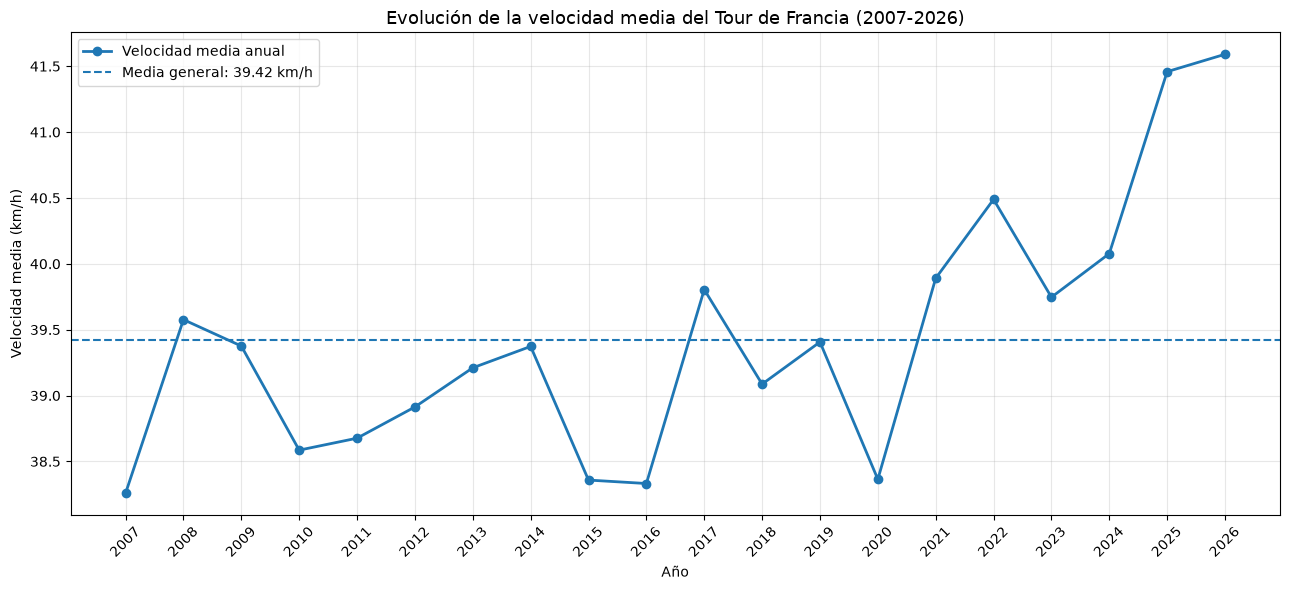

========== VELOCIDAD MEDIA POR EDICION ==========


,Year,Finalizadores,Velocidad_media,Velocidad_mediana,Desviacion
0,2007,140,38.26,38.14,0.46
1,2008,144,39.58,39.54,0.50
2,2009,151,39.38,39.31,0.52
3,2010,166,38.59,38.46,0.50
4,2011,165,38.68,38.58,0.49
5,2012,151,38.91,38.84,0.45
6,2013,169,39.21,39.12,0.55
7,2014,164,39.37,39.22,0.61
8,2015,160,38.36,38.25,0.55
9,2016,174,38.33,38.17,0.59


In [152]:

# ==========================================================
# EVOLUCION DE LA VELOCIDAD MEDIA POR EDICION
# ==========================================================

import matplotlib.pyplot as plt
import pandas as pd

# Calcular estadisticas por año
velocidad_anual = (
    df_eda.groupby("Year")
    .agg(
        Finalizadores=("Speed_kmh", "count"),
        Velocidad_media=("Speed_kmh", "mean"),
        Velocidad_mediana=("Speed_kmh", "median"),
        Desviacion=("Speed_kmh", "std")
    )
    .reset_index()
)

# Ordenar cronologicamente
velocidad_anual = velocidad_anual.sort_values("Year")

# Crear grafico
plt.figure(figsize=(13, 6))

plt.plot(
    velocidad_anual["Year"],
    velocidad_anual["Velocidad_media"],
    marker="o",
    linewidth=2,
    markersize=6,
    label="Velocidad media anual"
)

# Linea de referencia: media de todo el periodo
media_general = df_eda["Speed_kmh"].mean()

plt.axhline(
    media_general,
    linestyle="--",
    linewidth=1.5,
    label=f"Media general: {media_general:.2f} km/h"
)

plt.title(
    "Evolución de la velocidad media del Tour de Francia (2007-2026)",
    fontsize=13
)

plt.xlabel("Año")
plt.ylabel("Velocidad media (km/h)")

plt.xticks(velocidad_anual["Year"], rotation=45)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Mostrar tabla de resultados
print("========== VELOCIDAD MEDIA POR EDICION ==========")

display(
    velocidad_anual.round(2)
)


### EDA 04. Relación entre edad media y velocidad media por edición (2007-2026)

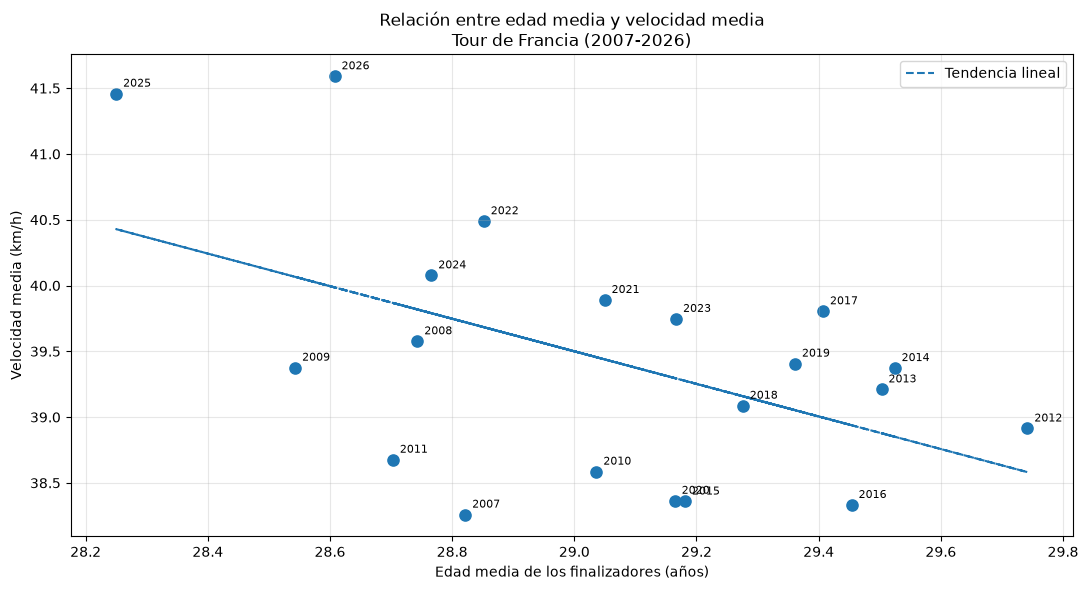

========== CORRELACIÓN ==========
Pearson: -0.503
Spearman: -0.373

========== DATOS POR EDICIÓN ==========


,Year,Edad_media,Velocidad_media,Finalizadores
0,2007,28.82,38.26,140
1,2008,28.74,39.58,144
2,2009,28.54,39.38,151
3,2010,29.04,38.59,166
4,2011,28.70,38.68,165
5,2012,29.74,38.91,151
6,2013,29.50,39.21,169
7,2014,29.52,39.37,164
8,2015,29.18,38.36,160
9,2016,29.45,38.33,174


In [153]:

# ==========================================================
# EDA 04: EDAD MEDIA VS VELOCIDAD MEDIA
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Calcular medias por edición
edad_velocidad = (
    df_eda.groupby("Year")
    .agg(
        Edad_media=("Age", "mean"),
        Velocidad_media=("Speed_kmh", "mean"),
        Finalizadores=("Rider", "count")
    )
    .reset_index()
)

# Calcular correlaciones
pearson = edad_velocidad[
    ["Edad_media", "Velocidad_media"]
].corr(method="pearson").iloc[0, 1]

spearman = edad_velocidad[
    ["Edad_media", "Velocidad_media"]
].corr(method="spearman").iloc[0, 1]

# Crear gráfico de dispersión
plt.figure(figsize=(11, 6))

plt.scatter(
    edad_velocidad["Edad_media"],
    edad_velocidad["Velocidad_media"],
    s=65
)

# Identificar cada edición
for _, fila in edad_velocidad.iterrows():
    plt.annotate(
        int(fila["Year"]),
        (fila["Edad_media"], fila["Velocidad_media"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Línea de tendencia
x = edad_velocidad["Edad_media"]
y = edad_velocidad["Velocidad_media"]

pendiente, intercepto = np.polyfit(x, y, 1)

plt.plot(
    x,
    pendiente * x + intercepto,
    linestyle="--",
    label="Tendencia lineal"
)

plt.title(
    "Relación entre edad media y velocidad media\n"
    "Tour de Francia (2007-2026)"
)

plt.xlabel("Edad media de los finalizadores (años)")
plt.ylabel("Velocidad media (km/h)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Mostrar resultados
print("========== CORRELACIÓN ==========")
print(f"Pearson: {pearson:.3f}")
print(f"Spearman: {spearman:.3f}")

print("\n========== DATOS POR EDICIÓN ==========")
display(edad_velocidad.round(2))


In [155]:

%pip install statsmodels

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.4 MB 8.3 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.4 MB 20.7 MB/s eta 0:00:01
   ----------------------------------- ---- 10.0/11.4 MB 23.0 MB/s eta 0:00:01
   ----------------------------------- ---- 10.2/11.4 MB 18.2 MB/s eta 0:00:01
   ----------------------------------- ---- 10.2/11.4 MB 18.2 MB/s eta 0:00:01
   ----------------------------------- ---- 10.2/11.4 MB 18.2 MB/s eta 0:00:01
   ----------------------------------- ---- 10.2/11.4 MB 18.2 MB/s eta 0:00:01
   ---------------------------------------- 11.4/11.4 MB 7.2 MB/s  0:00:01
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)

   ----- ---------------------------------- 1/7 [sc

### EDA 05: Análisis de regresión lineal controlando la evolución temporal (2007-2026).

In [157]:

# ==========================================================
# EDA 05: REGRESION LINEAL
# EDAD MEDIA Y VELOCIDAD MEDIA
# CONTROLANDO EL EFECTO DEL AÑO
# ==========================================================

import pandas as pd
import statsmodels.api as sm

# Preparar datos
datos_modelo = edad_velocidad.copy()

datos_modelo = datos_modelo.dropna(
    subset=["Edad_media", "Velocidad_media", "Year"]
)

# Centrar variable temporal
datos_modelo["Year_c"] = (
    datos_modelo["Year"] - datos_modelo["Year"].mean()
)

# ----------------------------------------------------------
# 1. MODELO BASE: SOLO EFECTO DEL AÑO
# ----------------------------------------------------------

X_base = sm.add_constant(
    datos_modelo[["Year_c"]]
)

modelo_base = sm.OLS(
    datos_modelo["Velocidad_media"],
    X_base
).fit()

# ----------------------------------------------------------
# 2. MODELO AJUSTADO: EDAD + AÑO
# ----------------------------------------------------------

X_ajustado = sm.add_constant(
    datos_modelo[["Edad_media", "Year_c"]]
)

modelo_ajustado = sm.OLS(
    datos_modelo["Velocidad_media"],
    X_ajustado
).fit(cov_type="HC3")

# ----------------------------------------------------------
# 3. RESULTADOS
# ----------------------------------------------------------

print("========== MODELO BASE ==========")
print(modelo_base.summary())

print("\n========== MODELO AJUSTADO ==========")
print(modelo_ajustado.summary())

# ----------------------------------------------------------
# 4. EFECTO DE LA EDAD
# ----------------------------------------------------------

coef_edad = modelo_ajustado.params["Edad_media"]
p_valor = modelo_ajustado.pvalues["Edad_media"]
intervalo = modelo_ajustado.conf_int().loc["Edad_media"]

print("\n========== EFECTO DE LA EDAD ==========")

print(f"Coeficiente: {coef_edad:.4f}")
print(f"Valor p: {p_valor:.4f}")
print(
    f"Intervalo de confianza 95%: "
    f"[{intervalo.iloc[0]:.4f}, {intervalo.iloc[1]:.4f}]"
)

print(f"R² modelo base: {modelo_base.rsquared:.4f}")
print(f"R² modelo ajustado: {modelo_ajustado.rsquared:.4f}")

# ----------------------------------------------------------
# 5. COMPARACION DE MODELOS
# ----------------------------------------------------------

print("\n========== COMPARACION ==========")

print(
    "Variación de R²:",
    round(
        modelo_ajustado.rsquared - modelo_base.rsquared,
        4
    )
)

print("\nANÁLISIS COMPLETADO")


========== MODELO BASE ==========
                            OLS Regression Results                            
Dep. Variable:        Velocidad_media   R-squared:                       0.471
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     16.02
Date:               ju., 12 nov. 2026   Prob (F-statistic):           0.000834
Time:                        00:52:31   Log-Likelihood:                -20.606
No. Observations:                  20   AIC:                             45.21
Df Residuals:                      18   BIC:                             47.20
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         39.4

### PRIMERAS CONCLUSIONES

Podemos establecer tres conclusiones:
1. La relación negativa entre edad media y velocidad media presenta una dirección consistente.
2. La magnitud del coeficiente se mantiene relativamente estable ante la exclusión individual de las ediciones.
3. La significación estadística es sensible a la exclusión de 2025 y 2026, por lo que debemos evitar afirmar que el resultado es completamente independiente de todas las ediciones.

### EDA 08: VELOCIDAD MEDIA SEGUN GRUPOS DE EDAD

========== EDA 08: ESTADISTICAS POR EDAD ==========


,Ciclistas,Edad_media,Edad_minima,Edad_maxima,Velocidad_media,Velocidad_mediana,Desviacion,Velocidad_minima,Velocidad_maxima
Grupo_edad,,,,,,,,,
Jovenes (19-24),405,23.272,19.0,24.0,39.529,39.370,1.235,37.50,43.79
Adultos jovenes (25-29),1355,27.105,25.0,29.0,39.420,39.240,1.146,37.30,43.89
Adultos (30-34),1006,31.726,30.0,34.0,39.421,39.290,1.078,37.26,43.69
Veteranos (35+),316,36.430,35.0,42.0,39.262,39.165,1.002,37.49,43.20


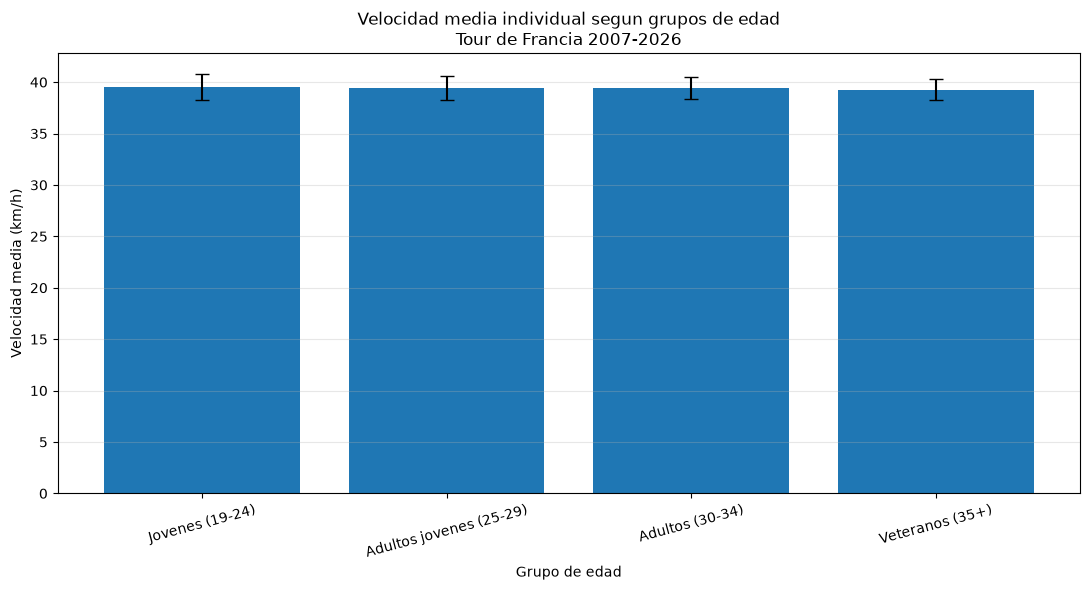

<Figure size 1100x600 with 0 Axes>

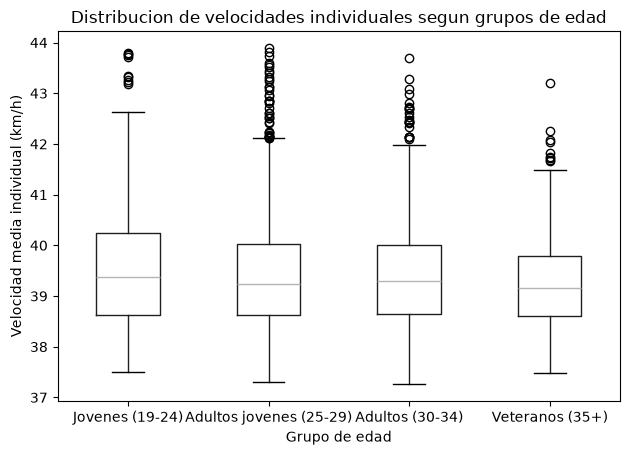

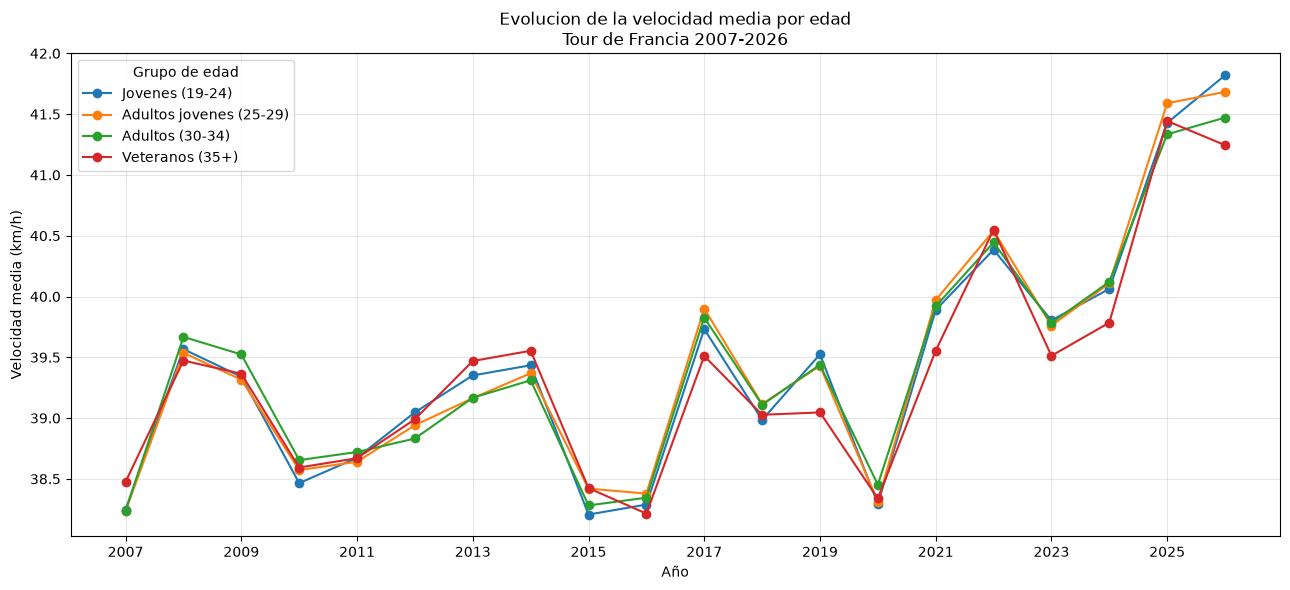


========== CONTROL DE CALIDAD ==========
Registros originales: 3082
Registros analizados: 3082
Edades faltantes: 0
Velocidades faltantes: 0
Duplicados por corredor y edicion: 0
Grupos de edad: 4

EDA 08 COMPLETADO


In [162]:

# ==========================================================
# EDA 08: VELOCIDAD INDIVIDUAL SEGUN GRUPOS DE EDAD
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. PREPARACION DE LOS DATOS
# ----------------------------------------------------------

# Utilizar la base integrada
datos_grupos = df_integrado.copy()

# Convertir variables a formato numerico
datos_grupos["Age"] = pd.to_numeric(
    datos_grupos["Age"], errors="coerce"
)

datos_grupos["Speed_kmh"] = pd.to_numeric(
    datos_grupos["Speed_kmh"], errors="coerce"
)

datos_grupos["Year"] = pd.to_numeric(
    datos_grupos["Year"], errors="coerce"
)

# Eliminar registros incompletos
datos_grupos = datos_grupos.dropna(
    subset=["Age", "Speed_kmh", "Year"]
).copy()

# ----------------------------------------------------------
# 2. CREAR GRUPOS DE EDAD
# ----------------------------------------------------------

datos_grupos["Grupo_edad"] = pd.cut(
    datos_grupos["Age"],
    bins=[0, 25, 30, 35, 100],
    labels=[
        "Jovenes (19-24)",
        "Adultos jovenes (25-29)",
        "Adultos (30-34)",
        "Veteranos (35+)"
    ],
    right=False
)

# Eliminar posibles edades fuera de los grupos
datos_grupos = datos_grupos.dropna(
    subset=["Grupo_edad"]
)

# ----------------------------------------------------------
# 3. ESTADISTICAS DESCRIPTIVAS
# ----------------------------------------------------------

resumen_grupos = (
    datos_grupos
    .groupby("Grupo_edad", observed=False)
    .agg(
        Ciclistas=("Rider", "count"),
        Edad_media=("Age", "mean"),
        Edad_minima=("Age", "min"),
        Edad_maxima=("Age", "max"),
        Velocidad_media=("Speed_kmh", "mean"),
        Velocidad_mediana=("Speed_kmh", "median"),
        Desviacion=("Speed_kmh", "std"),
        Velocidad_minima=("Speed_kmh", "min"),
        Velocidad_maxima=("Speed_kmh", "max")
    )
    .round(3)
)

print("========== EDA 08: ESTADISTICAS POR EDAD ==========")
display(resumen_grupos)

# ----------------------------------------------------------
# 4. GRAFICO DE VELOCIDAD MEDIA POR GRUPO
# ----------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    resumen_grupos.index.astype(str),
    resumen_grupos["Velocidad_media"],
    yerr=resumen_grupos["Desviacion"],
    capsize=5
)

plt.title(
    "Velocidad media individual segun grupos de edad\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Grupo de edad")
plt.ylabel("Velocidad media (km/h)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 5. DISTRIBUCION DE VELOCIDADES
# ----------------------------------------------------------

plt.figure(figsize=(11, 6))

datos_grupos.boxplot(
    column="Speed_kmh",
    by="Grupo_edad",
    grid=False
)

plt.title(
    "Distribucion de velocidades individuales "
    "segun grupos de edad"
)

plt.suptitle("")
plt.xlabel("Grupo de edad")
plt.ylabel("Velocidad media individual (km/h)")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. EVOLUCION DE VELOCIDAD POR GRUPO Y EDICION
# ----------------------------------------------------------

evolucion_grupos = (
    datos_grupos
    .groupby(["Year", "Grupo_edad"], observed=False)
    ["Speed_kmh"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 6))

for grupo in datos_grupos["Grupo_edad"].cat.categories:

    datos = evolucion_grupos[
        evolucion_grupos["Grupo_edad"] == grupo
    ]

    plt.plot(
        datos["Year"],
        datos["Speed_kmh"],
        marker="o",
        label=str(grupo)
    )

plt.title(
    "Evolucion de la velocidad media por edad\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Año")
plt.ylabel("Velocidad media (km/h)")
plt.legend(title="Grupo de edad")
plt.grid(alpha=0.3)
plt.xticks(range(2007, 2027, 2))
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 7. CONTROL DE CALIDAD
# ----------------------------------------------------------

print("\n========== CONTROL DE CALIDAD ==========")

print("Registros originales:", len(df_integrado))
print("Registros analizados:", len(datos_grupos))

print(
    "Edades faltantes:",
    datos_grupos["Age"].isna().sum()
)

print(
    "Velocidades faltantes:",
    datos_grupos["Speed_kmh"].isna().sum()
)

print(
    "Duplicados por corredor y edicion:",
    datos_grupos.duplicated(
        subset=["Year", "Rank"]
    ).sum()
)

print(
    "Grupos de edad:",
    datos_grupos["Grupo_edad"].nunique()
)

print("\nEDA 08 COMPLETADO")


### Interpretación de los resultados

Hay tres hallazgos iniciales:

1. Los ciclistas jóvenes presentan la mayor velocidad media.

El grupo de 19 a 24 años alcanza 39,529 km/h, mientras que los veteranos registran 39,262 km/h.

La diferencia es de aproximadamente 0,267 km/h.

2. Los grupos intermedios presentan velocidades prácticamente iguales.

Los adultos jóvenes y adultos registran velocidades medias de 39,420 y 39,421 km/h, respectivamente. La diferencia es prácticamente inexistente.

3. Los veteranos presentan menor dispersión.

La desviación estándar disminuye progresivamente:
- Jóvenes: 1,235.
- Adultos jóvenes: 1,146.
- Adultos: 1,078.
- Veteranos: 1,002.
Esto indica que las velocidades de los veteranos están algo más concentradas alrededor de su media.

## EDA 09. Análisis inferencial de la relación entre edad y velocidad individual
1. Prueba ANOVA para comparar las velocidades medias de los cuatro grupos.
2. Prueba de Welch, si no se cumple la igualdad de varianzas.
3. Prueba de Kruskal-Wallis como contraste no paramétrico.
4. Comparaciones post hoc para identificar qué grupos presentan diferencias.
5. Cálculo del tamaño del efecto.
6. Intervalos de confianza del 95 %.

In [163]:

# ==========================================================
# EDA 09: RELACION ENTRE EDAD Y VELOCIDAD
# MODELO DE REGRESION LINEAL MIXTO
# ==========================================================

import pandas as pd
import statsmodels.formula.api as smf

# Preparar datos
datos_modelo = df_eda.copy()

datos_modelo = datos_modelo.dropna(
    subset=["Age", "Speed_kmh", "Rider", "Year"]
)

datos_modelo["Year"] = datos_modelo["Year"].astype(int)

# Modelo: edad + efecto del año + efecto individual del ciclista
modelo = smf.mixedlm(
    "Speed_kmh ~ Age + C(Year)",
    data=datos_modelo,
    groups=datos_modelo["Rider"]
)

resultado = modelo.fit(
    reml=True,
    method="lbfgs"
)

# Resultados completos
print("========== MODELO MIXTO ==========")
print(resultado.summary())

# Extraer resultados de la edad
coeficiente = resultado.params["Age"]
valor_p = resultado.pvalues["Age"]
intervalo = resultado.conf_int().loc["Age"]

print("\n========== EFECTO DE LA EDAD ==========")
print(f"Coeficiente: {coeficiente:.4f}")
print(f"Valor p: {valor_p:.5f}")
print(
    f"IC 95%: [{intervalo.iloc[0]:.4f}, "
    f"{intervalo.iloc[1]:.4f}]"
)

if valor_p < 0.05:
    print("Existe una asociacion estadisticamente significativa.")
else:
    print("No se encuentra una asociacion estadisticamente significativa.")

print("\n========== DIAGNOSTICO ==========")
print("Registros:", len(datos_modelo))
print("Ciclistas:", datos_modelo["Rider"].nunique())
print("Ediciones:", datos_modelo["Year"].nunique())
print("Convergencia:", resultado.converged)

print("\nEDA 09 COMPLETADO")


========== MODELO MIXTO ==========
           Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  Speed_kmh 
No. Observations:  3082     Method:              REML      
No. Groups:        1003     Scale:               0.1059    
Min. group size:   1        Log-Likelihood:      -1954.3635
Max. group size:   13       Converged:           Yes       
Mean group size:   3.1                                     
-----------------------------------------------------------
                Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept       38.262    0.075 510.756 0.000 38.115 38.408
C(Year)[T.2008]  1.316    0.043  30.539 0.000  1.231  1.400
C(Year)[T.2009]  1.133    0.044  25.670 0.000  1.047  1.220
C(Year)[T.2010]  0.322    0.044   7.260 0.000  0.235  0.408
C(Year)[T.2011]  0.439    0.045   9.849 0.000  0.352  0.527
C(Year)[T.2012]  0.666    0.046  14.442 0.000  0.575  0.756
C(Year)[T.2013] 

### Conclusión académica del EDA 09

El modelo de regresión lineal mixto, aplicado a 3.082 registros correspondientes a 1.003 ciclistas y 20 ediciones del Tour de Francia (2007-2026), no encontró una asociación estadísticamente significativa entre la edad y la velocidad media individual de los corredores (β = -0,0025; p = 0,3537; IC 95 %: [-0,0079; 0,0028]). 

Este resultado indica que, una vez controladas las diferencias entre ediciones y la variabilidad individual de los ciclistas mediante efectos aleatorios, no existe evidencia estadística suficiente para afirmar que la edad esté asociada con la velocidad media alcanzada. En consecuencia, las diferencias descriptivas observadas entre los grupos de edad no permiten concluir que exista una relación estadísticamente significativa entre ambas variables.

## EDA 11. Evolución del rendimiento de los ciclistas a lo largo de las ediciones.


========== EDA 11 ==========
EVOLUCION DEL RENDIMIENTO
Ciclistas con participaciones repetidas: 645
Registros analizados: 2724

RESUMEN POR NUMERO DE PARTICIPACION


,Ciclistas,Velocidad_media,Velocidad_mediana,Posicion_relativa_media,Posicion_relativa_mediana
Participacion,,,,,
1,645,39.055,38.970,53.449,54.861
2,645,39.497,39.320,49.905,51.220
3,463,39.426,39.220,48.660,47.879
4,310,39.458,39.270,45.711,43.565
5,223,39.503,39.430,44.045,41.429
6,166,39.574,39.390,45.400,41.043
7,110,39.630,39.520,48.982,52.473
8,70,39.829,39.745,44.304,39.992
9,48,40.146,40.045,44.227,44.427



========== PRIMERA VS ULTIMA PARTICIPACION ==========


,Velocidad_inicial,Velocidad_final,Posicion_inicial,Posicion_final,Participaciones,Cambio_velocidad,Cambio_posicion
count,645.000,645.000,645.000,645.000,645.000,645.000,645.000
mean,39.055,39.771,53.449,54.637,4.223,0.716,1.189
std,0.941,1.363,29.163,28.773,2.354,1.243,22.589
min,37.300,37.260,0.000,0.000,2.000,-2.590,-85.309
25%,38.300,38.760,28.571,28.916,2.000,-0.150,-12.270
50%,38.970,39.450,54.861,55.556,3.000,0.660,1.513
75%,39.600,40.660,79.141,80.503,6.000,1.470,14.510
max,42.950,43.890,102.667,102.000,13.000,4.550,76.873


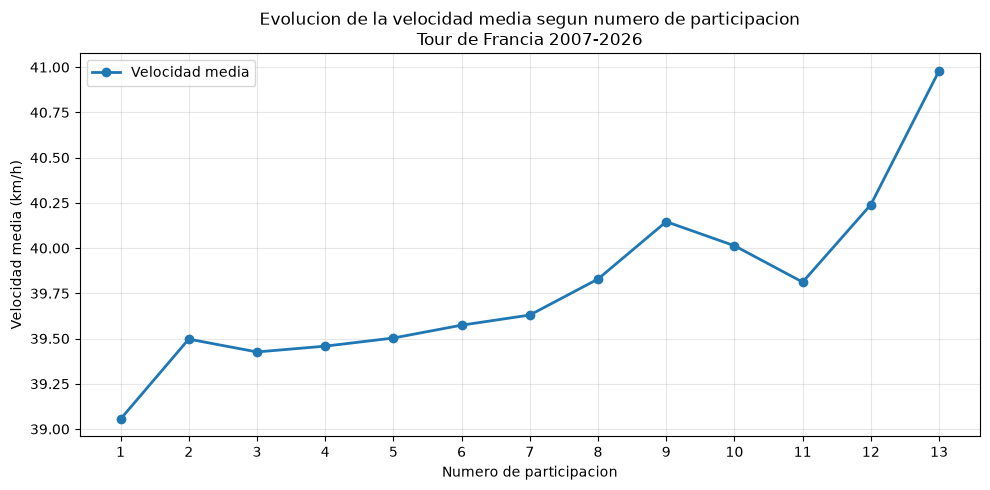

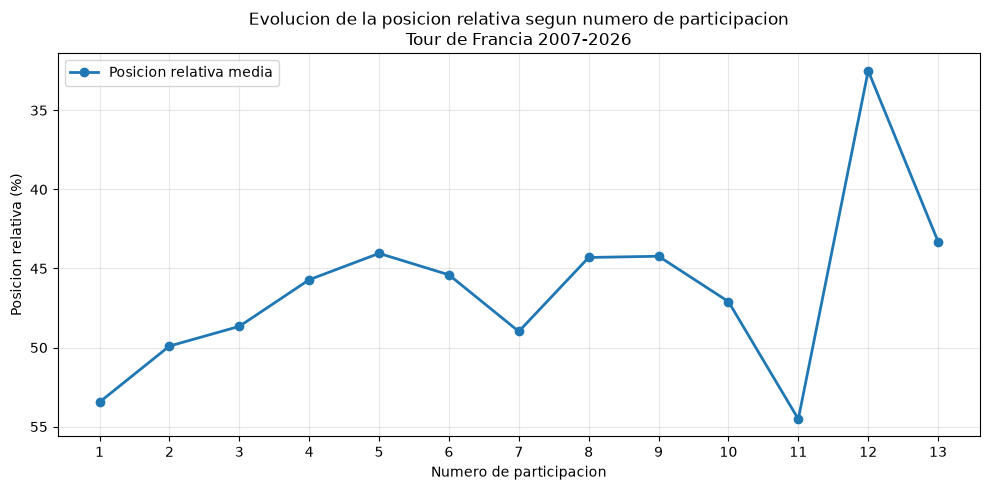


========== RESULTADOS GENERALES ==========
Cambio medio de velocidad: 0.716 km/h
Cambio medio de posicion relativa: 1.189 %
Ciclistas que mejoraron su velocidad: 453
Ciclistas que redujeron su posicion relativa: 295

EDA 11 COMPLETADO


In [166]:

# ==========================================================
# EDA 11: EVOLUCION DEL RENDIMIENTO DE LOS CICLISTAS
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------
# 1. PREPARAR LOS DATOS
# ----------------------------------------------------------

datos = df_eda.copy()

# Identificar ciclista
col_ciclista = (
    "Matched_Rider"
    if "Matched_Rider" in datos.columns
    else "Rider"
)

columnas = [
    col_ciclista,
    "Year",
    "Rank",
    "Speed_kmh"
]

datos = datos[columnas].copy()

datos = datos.dropna(
    subset=columnas
)

datos["Year"] = datos["Year"].astype(int)
datos["Rank"] = pd.to_numeric(datos["Rank"])
datos["Speed_kmh"] = pd.to_numeric(
    datos["Speed_kmh"]
)

# Eliminar posibles duplicados
datos = datos.drop_duplicates(
    subset=[col_ciclista, "Year"]
)

# ----------------------------------------------------------
# 2. IDENTIFICAR PARTICIPACIONES
# ----------------------------------------------------------

datos = datos.sort_values(
    [col_ciclista, "Year"]
)

datos["Participacion"] = (
    datos.groupby(col_ciclista)
    .cumcount() + 1
)

# Numero total de participaciones por ciclista
datos["Total_participaciones"] = (
    datos.groupby(col_ciclista)[col_ciclista]
    .transform("count")
)

# Considerar ciclistas con al menos dos Tours
recurrentes = datos[
    datos["Total_participaciones"] >= 2
].copy()

# ----------------------------------------------------------
# 3. NORMALIZAR POSICION SEGUN PARTICIPANTES
# ----------------------------------------------------------

finalizadores = (
    datos.groupby("Year")[col_ciclista]
    .count()
)

datos["Finalizadores_edicion"] = (
    datos["Year"].map(finalizadores)
)

# 0 = mejor posición; 100 = peor posición
datos["Posicion_relativa"] = (
    (datos["Rank"] - 1) /
    (datos["Finalizadores_edicion"] - 1)
) * 100

recurrentes = datos[
    datos["Total_participaciones"] >= 2
].copy()

# ----------------------------------------------------------
# 4. TABLA DE EVOLUCION POR PARTICIPACION
# ----------------------------------------------------------

resumen_participaciones = (
    recurrentes.groupby("Participacion")
    .agg(
        Ciclistas=(col_ciclista, "nunique"),
        Velocidad_media=("Speed_kmh", "mean"),
        Velocidad_mediana=("Speed_kmh", "median"),
        Posicion_relativa_media=(
            "Posicion_relativa", "mean"
        ),
        Posicion_relativa_mediana=(
            "Posicion_relativa", "median"
        )
    )
    .round(3)
)

print("\n========== EDA 11 ==========")
print("EVOLUCION DEL RENDIMIENTO")
print("================================")

print(
    "Ciclistas con participaciones repetidas:",
    recurrentes[col_ciclista].nunique()
)

print(
    "Registros analizados:",
    len(recurrentes)
)

print("\nRESUMEN POR NUMERO DE PARTICIPACION")

display(resumen_participaciones)

# ----------------------------------------------------------
# 5. COMPARAR PRIMERA Y ULTIMA PARTICIPACION
# ----------------------------------------------------------

primera = (
    recurrentes.groupby(col_ciclista)
    .first()
)

ultima = (
    recurrentes.groupby(col_ciclista)
    .last()
)

comparacion = pd.DataFrame({
    "Velocidad_inicial": primera["Speed_kmh"],
    "Velocidad_final": ultima["Speed_kmh"],
    "Posicion_inicial": primera["Posicion_relativa"],
    "Posicion_final": ultima["Posicion_relativa"],
    "Participaciones": primera["Total_participaciones"]
})

comparacion["Cambio_velocidad"] = (
    comparacion["Velocidad_final"] -
    comparacion["Velocidad_inicial"]
)

comparacion["Cambio_posicion"] = (
    comparacion["Posicion_final"] -
    comparacion["Posicion_inicial"]
)

comparacion = comparacion.round(3)

print("\n========== PRIMERA VS ULTIMA PARTICIPACION ==========")

display(
    comparacion.describe().round(3)
)

# ----------------------------------------------------------
# 6. GRAFICO 1: EVOLUCION DE VELOCIDAD
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    resumen_participaciones.index,
    resumen_participaciones["Velocidad_media"],
    marker="o",
    linewidth=2,
    label="Velocidad media"
)

plt.xlabel("Numero de participacion")
plt.ylabel("Velocidad media (km/h)")

plt.title(
    "Evolucion de la velocidad media segun "
    "numero de participacion\nTour de Francia 2007-2026"
)

plt.xticks(resumen_participaciones.index)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 7. GRAFICO 2: EVOLUCION DE POSICION RELATIVA
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    resumen_participaciones.index,
    resumen_participaciones[
        "Posicion_relativa_media"
    ],
    marker="o",
    linewidth=2,
    label="Posicion relativa media"
)

plt.xlabel("Numero de participacion")
plt.ylabel("Posicion relativa (%)")

plt.title(
    "Evolucion de la posicion relativa "
    "segun numero de participacion\n"
    "Tour de Francia 2007-2026"
)

plt.xticks(resumen_participaciones.index)
plt.gca().invert_yaxis()
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 8. RESULTADOS GENERALES
# ----------------------------------------------------------

print("\n========== RESULTADOS GENERALES ==========")

print(
    "Cambio medio de velocidad:",
    round(comparacion["Cambio_velocidad"].mean(), 3),
    "km/h"
)

print(
    "Cambio medio de posicion relativa:",
    round(comparacion["Cambio_posicion"].mean(), 3),
    "%"
)

print(
    "Ciclistas que mejoraron su velocidad:",
    (comparacion["Cambio_velocidad"] > 0).sum()
)

print(
    "Ciclistas que redujeron su posicion relativa:",
    (comparacion["Cambio_posicion"] < 0).sum()
)

# ----------------------------------------------------------
# 9. GUARDAR RESULTADOS
# ----------------------------------------------------------

resumen_participaciones.to_csv(
    "data/eda11_evolucion_participaciones.csv"
)

comparacion.to_csv(
    "data/eda11_primera_ultima_participacion.csv"
)

print("\nEDA 11 COMPLETADO")


### Interpretación de los gráficos
Gráfico 1. Velocidad media según número de participación

Se observa una tendencia creciente: los ciclistas con más participaciones presentan velocidades medias superiores.

Sin embargo, hay que tener cuidado: los corredores que llegan a acumular muchas participaciones constituyen un grupo más reducido y seleccionado. No podemos afirmar que la experiencia sea la causa directa del incremento.

Gráfico 2. Posición relativa según participación

La evolución es irregular. No existe una mejora constante en la clasificación conforme aumenta el número de participaciones.

Esto sugiere que acumular experiencia no garantiza obtener mejores posiciones.

## EDA 12. Dominio y concentración de los equipos


========== EDA 12: DOMINIO DE EQUIPOS ==========


,Team,Posiciones_Top10,Ediciones,Ciclistas,Victorias,Posicion_media
0,MOVISTAR TEAM,14,8,4,0,5.64
1,UAE TEAM EMIRATES,10,7,5,3,3.60
2,AG2R LA MONDIALE,7,6,2,0,5.29
3,TEAM SKY,6,4,3,4,1.83
4,ASTANA PRO TEAM,6,6,5,1,5.33
5,BMC RACING TEAM,5,4,3,1,4.60
6,EUSKALTEL - EUSKADI,5,4,3,0,5.40
7,INEOS GRENADIERS,5,4,4,0,5.60
8,BAHRAIN VICTORIOUS,4,4,3,0,7.50
9,BORA - HANSGROHE,4,4,4,0,5.25



========== CONCENTRACION POR EDICION ==========


,Year,Registros_Top10,Equipos_diferentes,Equipos_principales,Posiciones_Top3_Equipos,Concentracion_Top3_pct
0,2007,9,6,"DISCOVERY CHANNEL TEAM, EUSKALTEL - EUSKADI, C...",6,66.67
1,2008,10,8,"TEAM CSC SAXO BANK, AG2R-LA MONDIALE, SILENCE ...",5,50.00
2,2009,10,5,"ASTANA, TEAM SAXO BANK, GARMIN - SLIPSTREAM",6,60.00
3,2010,9,9,"TEAM SAXO BANK, EUSKALTEL - EUSKADI, OMEGA PHA...",3,33.33
4,2011,10,8,"TEAM LEOPARD-TREK, TEAM EUROPCAR, BMC RACING TEAM",5,50.00
5,2012,10,8,"SKY PROCYCLING, BMC RACING TEAM, LIQUIGAS-CANN...",5,50.00
6,2013,10,8,"MOVISTAR TEAM, TEAM SAXO-TINKOFF, SKY PROCYCLING",5,50.00
7,2014,10,8,"AG2R LA MONDIALE, BELKIN PRO CYCLING, ASTANA P...",5,50.00
8,2015,10,9,"MOVISTAR TEAM, TEAM SKY, ASTANA PRO TEAM",4,40.00
9,2016,10,9,"MOVISTAR TEAM, TEAM SKY, AG2R LA MONDIALE",4,40.00



========== CONTROL DE CALIDAD ==========


,Year,Registros_Top10,Equipos_identificados,Equipos_sin_identificar,Posiciones_faltantes,Estado
0,2007,9,9,0,[3],REVISAR
1,2008,10,10,0,[],COMPLETO
2,2009,10,10,0,[],COMPLETO
3,2010,9,9,0,[4],REVISAR
4,2011,10,10,0,[],COMPLETO
5,2012,10,10,0,[],COMPLETO
6,2013,10,10,0,[],COMPLETO
7,2014,10,10,0,[],COMPLETO
8,2015,10,10,0,[],COMPLETO
9,2016,10,10,0,[],COMPLETO


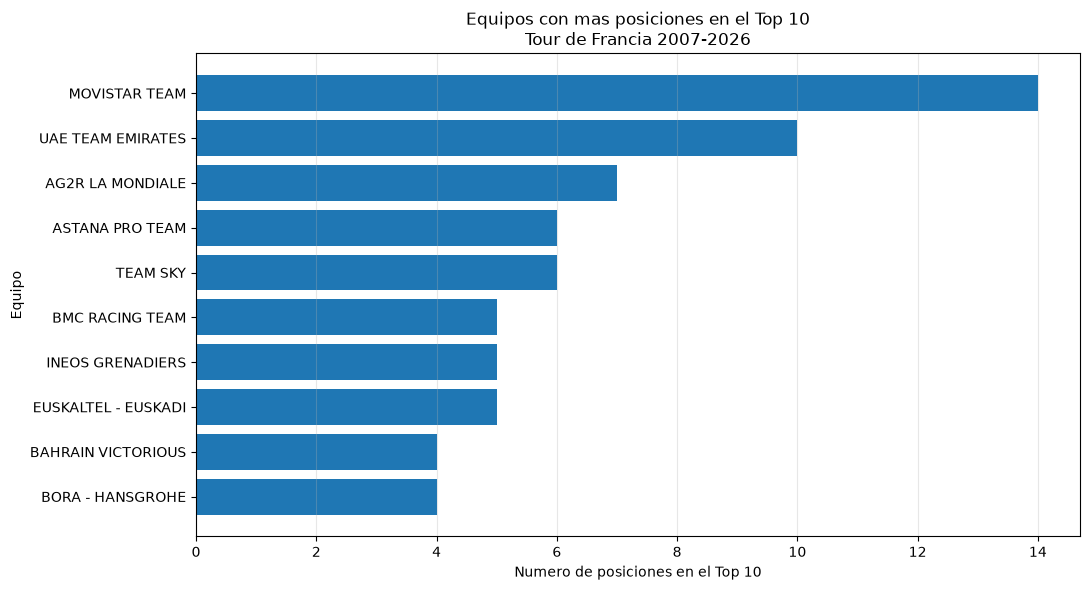

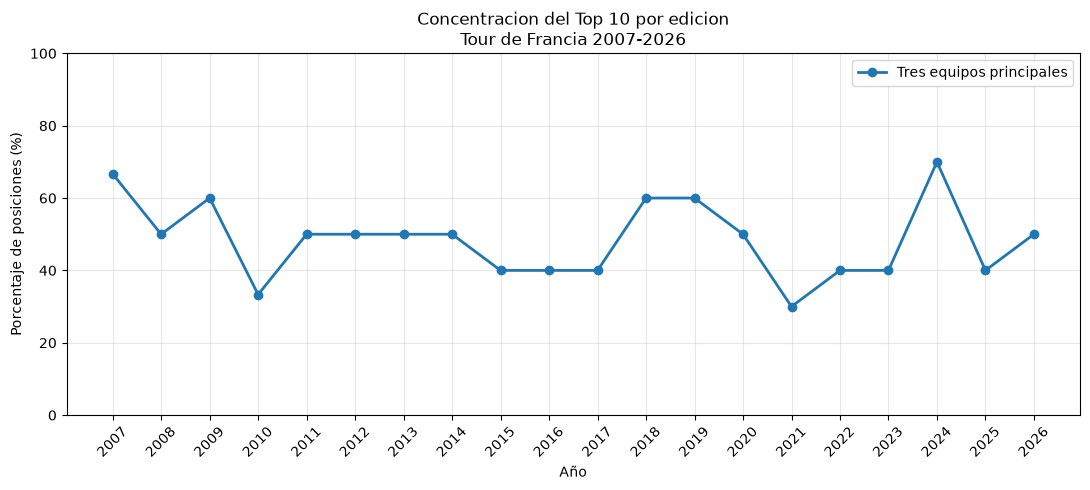


========== RESULTADOS GENERALES ==========
Periodo: 2007-2026
Ediciones: 20
Posiciones Top 10 encontradas: 198
Posiciones teoricas: 200
Equipos diferentes: 94
Registros sin equipo identificado: 0
Equipo con mas posiciones Top 10: MOVISTAR TEAM
Posiciones de ese equipo: 14
Victorias registradas: 20
Concentracion media de los tres principales: 48.5 %
Ediciones con menos de 10 registros: 2

========== EDA 12 COMPLETADO ==========
Archivos guardados correctamente.


In [169]:


# ==========================================================
# EDA 12: DOMINIO Y CONCENTRACION DE LOS EQUIPOS
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ----------------------------------------------------------
# 1. PREPARACION DE DATOS
# ----------------------------------------------------------

Path("data").mkdir(parents=True, exist_ok=True)

datos = df_eda.copy()

datos["Year"] = pd.to_numeric(datos["Year"], errors="coerce")
datos["Rank"] = pd.to_numeric(datos["Rank"], errors="coerce")

datos = datos[
    datos["Year"].between(2007, 2026)
].copy()

# Normalizar nombres de equipos
datos["Team"] = (
    datos["Team"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("SIN DATO")
)

# Seleccionar los diez primeros puestos
top10 = datos[
    datos["Rank"].between(1, 10)
].copy()

# ----------------------------------------------------------
# 2. RESUMEN GENERAL POR EQUIPOS
# ----------------------------------------------------------

resumen_equipos = (
    top10.groupby("Team")
    .agg(
        Posiciones_Top10=("Rank", "count"),
        Ediciones=("Year", "nunique"),
        Ciclistas=("Rider", "nunique"),
        Victorias=("Rank", lambda x: (x == 1).sum()),
        Posicion_media=("Rank", "mean")
    )
    .sort_values(
        ["Posiciones_Top10", "Victorias"],
        ascending=False
    )
    .reset_index()
)

print("\n========== EDA 12: DOMINIO DE EQUIPOS ==========")

display(resumen_equipos.head(15).round(2))

# ----------------------------------------------------------
# 3. CONCENTRACION POR EDICION
# ----------------------------------------------------------

concentracion = []

for anio, grupo in top10.groupby("Year"):

    frecuencias = grupo["Team"].value_counts()

    principales = frecuencias.head(3)

    total = len(grupo)

    concentracion.append({
        "Year": anio,
        "Registros_Top10": total,
        "Equipos_diferentes": grupo["Team"].nunique(),
        "Equipos_principales": ", ".join(
            principales.index.astype(str)
        ),
        "Posiciones_Top3_Equipos": principales.sum(),
        "Concentracion_Top3_pct": (
            principales.sum() / total * 100
            if total > 0 else 0
        )
    })

concentracion_anual = pd.DataFrame(concentracion)

print("\n========== CONCENTRACION POR EDICION ==========")

display(concentracion_anual.round(2))

# ----------------------------------------------------------
# 4. CONTROL DE CALIDAD
# ----------------------------------------------------------

control_calidad = []

for anio in range(2007, 2027):

    grupo = top10[top10["Year"] == anio]

    posiciones = grupo["Rank"].tolist()

    faltantes = sorted(
        set(range(1, 11)) - set(posiciones)
    )

    control_calidad.append({
        "Year": anio,
        "Registros_Top10": len(grupo),
        "Equipos_identificados": (
            (grupo["Team"] != "SIN DATO").sum()
        ),
        "Equipos_sin_identificar": (
            (grupo["Team"] == "SIN DATO").sum()
        ),
        "Posiciones_faltantes": faltantes,
        "Estado": (
            "COMPLETO"
            if len(grupo) == 10
            else "REVISAR"
        )
    })

control_eda12 = pd.DataFrame(control_calidad)

print("\n========== CONTROL DE CALIDAD ==========")

display(control_eda12)

# ----------------------------------------------------------
# 5. GRAFICO 1: EQUIPOS CON MAS POSICIONES TOP 10
# ----------------------------------------------------------

top_equipos = (
    resumen_equipos
    .head(10)
    .sort_values("Posiciones_Top10")
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_equipos["Team"],
    top_equipos["Posiciones_Top10"]
)

plt.title(
    "Equipos con mas posiciones en el Top 10\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Numero de posiciones en el Top 10")
plt.ylabel("Equipo")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. GRAFICO 2: EVOLUCION DE LA CONCENTRACION
# ----------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    concentracion_anual["Year"],
    concentracion_anual["Concentracion_Top3_pct"],
    marker="o",
    linewidth=2,
    label="Tres equipos principales"
)

plt.title(
    "Concentracion del Top 10 por edicion\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Año")
plt.ylabel("Porcentaje de posiciones (%)")

plt.xticks(range(2007, 2027, 1), rotation=45)
plt.ylim(0, 100)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 7. INDICADORES GENERALES
# ----------------------------------------------------------

total_registros = len(top10)

print("\n========== RESULTADOS GENERALES ==========")

print("Periodo: 2007-2026")
print("Ediciones:", top10["Year"].nunique())
print("Posiciones Top 10 encontradas:", total_registros)
print("Posiciones teoricas:", 200)

print(
    "Equipos diferentes:",
    top10["Team"].nunique()
)

print(
    "Registros sin equipo identificado:",
    (top10["Team"] == "SIN DATO").sum()
)

print(
    "Equipo con mas posiciones Top 10:",
    resumen_equipos.iloc[0]["Team"]
)

print(
    "Posiciones de ese equipo:",
    resumen_equipos.iloc[0]["Posiciones_Top10"]
)

print(
    "Victorias registradas:",
    int(resumen_equipos["Victorias"].sum())
)

print(
    "Concentracion media de los tres principales:",
    round(
        concentracion_anual["Concentracion_Top3_pct"].mean(),
        2
    ),
    "%"
)

print(
    "Ediciones con menos de 10 registros:",
    (control_eda12["Registros_Top10"] < 10).sum()
)

# ----------------------------------------------------------
# 8. GUARDAR RESULTADOS
# ----------------------------------------------------------

resumen_equipos.to_csv(
    "data/eda12_resumen_equipos.csv",
    index=False
)

concentracion_anual.to_csv(
    "data/eda12_concentracion_anual.csv",
    index=False
)

control_eda12.to_csv(
    "data/eda12_control_calidad.csv",
    index=False
)

print("\n========== EDA 12 COMPLETADO ==========")
print("Archivos guardados correctamente.")



## Interpretación de los gráficos
### Gráfico 1. Equipos con más posiciones en el Top 10

Movistar Team lidera con 14 posiciones, seguido de UAE Team Emirates con 10 y AG2R La Mondiale con 7.

Esto muestra que algunos equipos han tenido mayor presencia histórica en los primeros puestos.

### Gráfico 2. Concentración del Top 10

La concentración media de los tres equipos principales es del 48,5 %.

Se observa que el dominio cambia entre ediciones. En 2024 alcanza aproximadamente el 70 %, mientras que en 2021 baja al 30 %.

Esto sugiere que la concentración del rendimiento por equipos no ha sido constante.

## EDA 13. Evolución de las diferencias de tiempo entre ciclistas (2007-2026)
### Pregunta de investigación: ¿Las diferencias de tiempo entre los primeros clasificados del Tour de Francia se han reducido o aumentado a lo largo de los años?

Vamos a estudiar:
- Diferencia en segundos entre el ganador y el segundo clasificado.
- Diferencia entre el ganador y el décimo clasificado.
- Brecha temporal mediana entre los diez primeros.
- Comparación entre los periodos 2007-2016 y 2017-2026.


========== BRECHAS POR EDICION ==========


,Year,Registros,Brecha_segundo_segundos,Brecha_decimo_segundos,Brecha_mediana_Top10,Brecha_maxima_Top10
0,2007,9,23,865,697.0,865
1,2008,10,58,595,326.5,595
2,2009,10,251,1039,428.5,1039
3,2010,9,181,822,576.0,822
4,2011,10,94,643,330.0,643
5,2012,10,201,1037,802.5,1037
6,2013,10,260,1059,574.5,1059
7,2014,10,457,1275,685.0,1275
8,2015,10,72,1050,617.5,1050
9,2016,10,245,431,346.5,431



========== COMPARACION DE PERIODOS ==========


,Periodo,Registros,Brecha_media,Brecha_mediana,Brecha_maxima
0,2007-2016,98,509.33,456.0,1275
1,2017-2026,100,668.33,561.5,2001


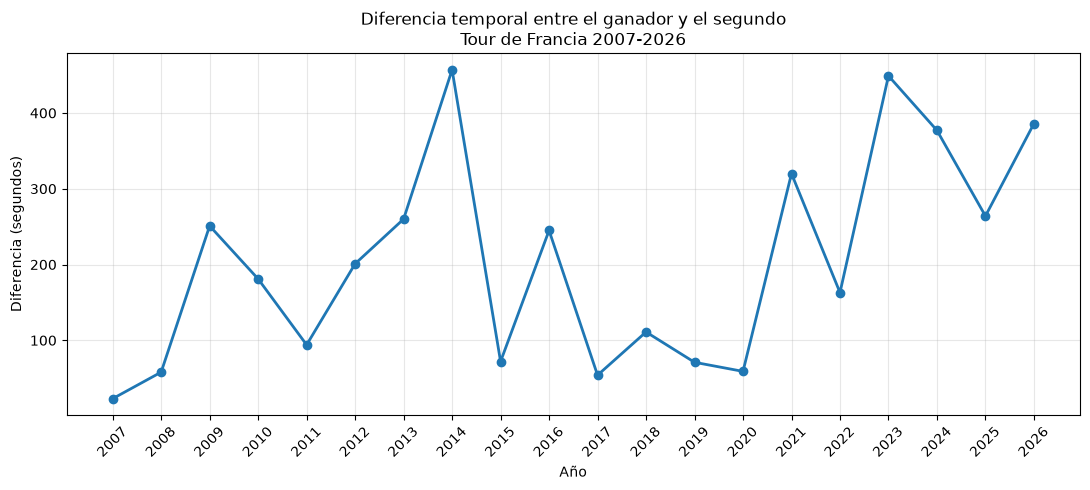

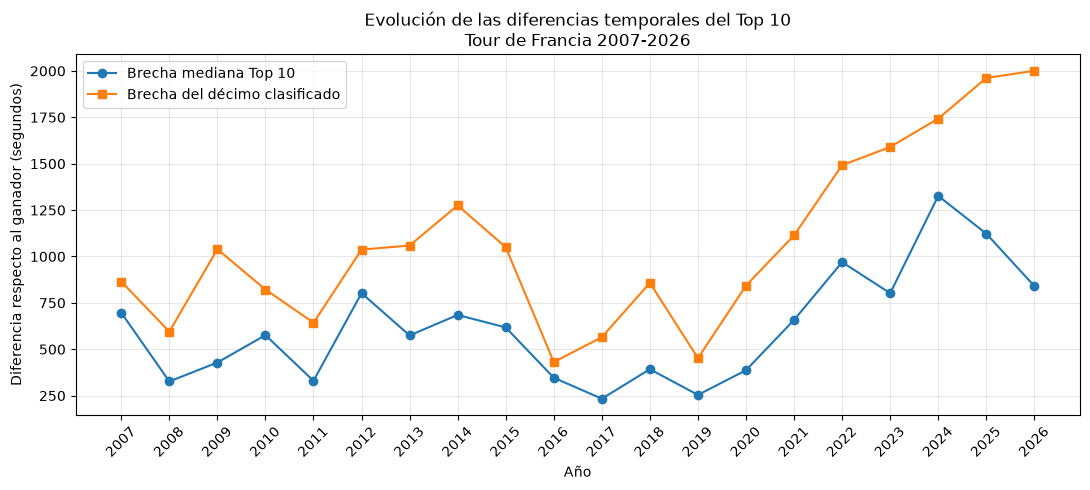


========== RESULTADOS GENERALES ==========
Ediciones analizadas: 20
Brecha mediana general: 498.5 segundos
Brecha media general: 589.63 segundos
Registros sin brecha disponible: 0

EDA 13 COMPLETADO


In [170]:

# ==========================================================
# EDA 13: EVOLUCION DE LAS DIFERENCIAS DE TIEMPO
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("data").mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# 1. PREPARACION
# ----------------------------------------------------------

datos = df_eda.copy()

datos["Year"] = pd.to_numeric(datos["Year"])
datos["Rank"] = pd.to_numeric(datos["Rank"])
datos["GapSeconds"] = pd.to_numeric(
    datos["GapSeconds"], errors="coerce"
)

# Seleccionar Top 10
top10 = datos[
    datos["Rank"].between(1, 10)
].copy()

# ----------------------------------------------------------
# 2. RESUMEN POR EDICION
# ----------------------------------------------------------

resultados = []

for anio, grupo in top10.groupby("Year"):

    segundo = grupo.loc[
        grupo["Rank"] == 2, "GapSeconds"
    ]

    decimo = grupo.loc[
        grupo["Rank"] == 10, "GapSeconds"
    ]

    resultados.append({
        "Year": anio,
        "Registros": len(grupo),
        "Brecha_segundo_segundos": (
            segundo.iloc[0] if len(segundo) else None
        ),
        "Brecha_decimo_segundos": (
            decimo.iloc[0] if len(decimo) else None
        ),
        "Brecha_mediana_Top10": grupo["GapSeconds"].median(),
        "Brecha_maxima_Top10": grupo["GapSeconds"].max()
    })

brechas_anuales = pd.DataFrame(resultados)

print("\n========== BRECHAS POR EDICION ==========")
display(brechas_anuales.round(2))

# ----------------------------------------------------------
# 3. COMPARACION POR PERIODOS
# ----------------------------------------------------------

datos["Periodo"] = datos["Year"].apply(
    lambda x: "2007-2016" if x <= 2016 else "2017-2026"
)

comparacion = (
    top10.assign(
        Periodo=top10["Year"].apply(
            lambda x: "2007-2016" if x <= 2016
            else "2017-2026"
        )
    )
    .groupby("Periodo")
    .agg(
        Registros=("GapSeconds", "count"),
        Brecha_media=("GapSeconds", "mean"),
        Brecha_mediana=("GapSeconds", "median"),
        Brecha_maxima=("GapSeconds", "max")
    )
    .round(2)
    .reset_index()
)

print("\n========== COMPARACION DE PERIODOS ==========")
display(comparacion)

# ----------------------------------------------------------
# 4. GRAFICO 1: DIFERENCIA ENTRE PRIMERO Y SEGUNDO
# ----------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    brechas_anuales["Year"],
    brechas_anuales["Brecha_segundo_segundos"],
    marker="o",
    linewidth=2
)

plt.title(
    "Diferencia temporal entre el ganador y el segundo\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Año")
plt.ylabel("Diferencia (segundos)")
plt.xticks(range(2007, 2027), rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 5. GRAFICO 2: BRECHA DEL TOP 10
# ----------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    brechas_anuales["Year"],
    brechas_anuales["Brecha_mediana_Top10"],
    marker="o",
    label="Brecha mediana Top 10"
)

plt.plot(
    brechas_anuales["Year"],
    brechas_anuales["Brecha_decimo_segundos"],
    marker="s",
    label="Brecha del décimo clasificado"
)

plt.title(
    "Evolución de las diferencias temporales del Top 10\n"
    "Tour de Francia 2007-2026"
)

plt.xlabel("Año")
plt.ylabel("Diferencia respecto al ganador (segundos)")
plt.xticks(range(2007, 2027), rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. INDICADORES GENERALES
# ----------------------------------------------------------

print("\n========== RESULTADOS GENERALES ==========")

print("Ediciones analizadas:", len(brechas_anuales))

print(
    "Brecha mediana general:",
    round(top10["GapSeconds"].median(), 2),
    "segundos"
)

print(
    "Brecha media general:",
    round(top10["GapSeconds"].mean(), 2),
    "segundos"
)

print(
    "Registros sin brecha disponible:",
    top10["GapSeconds"].isna().sum()
)

# ----------------------------------------------------------
# 7. GUARDAR RESULTADOS
# ----------------------------------------------------------

brechas_anuales.to_csv(
    "data/eda13_brechas_anuales.csv",
    index=False
)

comparacion.to_csv(
    "data/eda13_comparacion_periodos.csv",
    index=False
)

print("\nEDA 13 COMPLETADO")


### Interpretación de los resultados
Gráfico 1. Diferencia entre el ganador y el segundo
- En 2007 la diferencia fue muy reducida.
- En 2014 se observa una de las mayores diferencias del periodo.
- En 2021, 2023 y 2026 vuelven a aparecer brechas importantes.
- No existe una evolución lineal: hay bastante variabilidad entre ediciones.

Gráfico 2. Diferencias temporales del Top 10

Este es el gráfico más interesante del análisis:
- La brecha del décimo clasificado aumenta notablemente desde 2020.
- La brecha mediana del Top 10 también muestra un incremento en las últimas ediciones.
- Esto apunta a una mayor dispersión temporal entre los integrantes del Top 10 en los años recientes.

## EDA 14. Persistencia del éxito competitivo (2007-2026)
Pregunta de investigación:

¿Los ciclistas que consiguen entrar en el Top 10 de una edición del Tour de Francia tienen mayor probabilidad de volver a conseguirlo en sus siguientes participaciones?
Hipótesis
- H₀ (nula): No existe asociación entre haber conseguido un Top 10 en la participación anterior y volver a conseguirlo.
- H₁ (alternativa): Los ciclistas que consiguieron un Top 10 en su participación anterior tienen mayor probabilidad de repetirlo.


========== MATRIZ DE TRANSICIONES ==========


Resultado_actual,Fuera del Top 10,Dentro del Top 10
Resultado_anterior,,
Fuera del Top 10,1829,82
Dentro del Top 10,92,76



========== PORCENTAJES DE TRANSICION ==========


Resultado_actual,Fuera del Top 10,Dentro del Top 10
Resultado_anterior,,
Fuera del Top 10,95.71,4.29
Dentro del Top 10,54.76,45.24



========== PROBABILIDAD DE TOP 10 ==========


,Participaciones,Repiten_Top10,Probabilidad_Top10
Top10_anterior,,,
Anterior fuera del Top 10,1911,82,4.29
Anterior dentro del Top 10,168,76,45.24



Diferencia de probabilidades: 40.95 puntos porcentuales

========== CONTRASTE CHI-CUADRADO ==========
Chi-cuadrado: 362.9040
Grados de libertad: 1
Valor p: 0.000000
Resultado: asociacion estadisticamente significativa


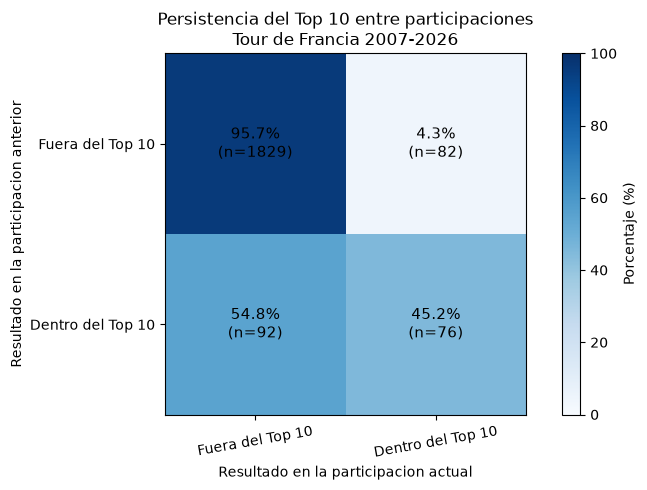

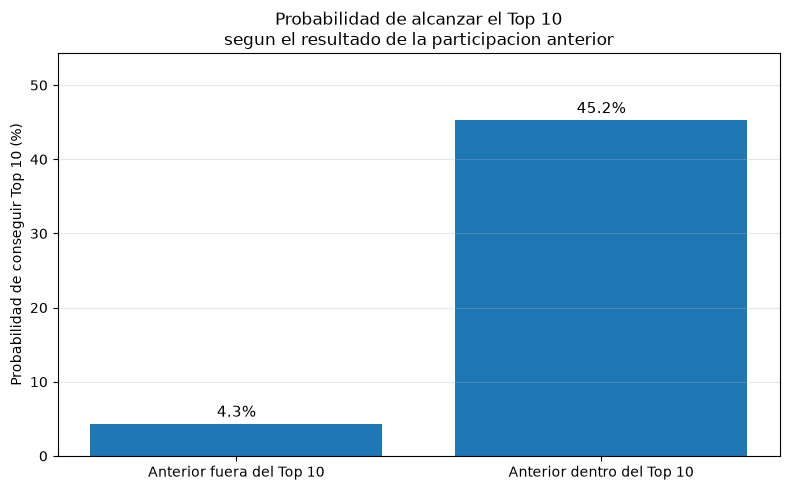


========== CONTROL DE CALIDAD ==========
Registros originales: 3082
Transiciones analizadas: 2079
Ciclistas con participaciones multiples: 645
Duplicados ciclista-edicion: 0
Participaciones consecutivas analizadas: 2079
========== EXPORTACION H4 ==========
Archivo: data/eda14_transiciones.csv
Transiciones guardadas: 2079
Ciclistas: 645

Archivo preparado correctamente.

EDA 14 COMPLETADO


In [173]:

# ==========================================================
# EDA 14: PERSISTENCIA DEL EXITO COMPETITIVO
# TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# ----------------------------------------------------------
# 1. PREPARACION DE DATOS
# ----------------------------------------------------------

datos = df_eda.copy()

# Identificador del ciclista
col_ciclista = (
    "Matched_Rider"
    if "Matched_Rider" in datos.columns
    else "Rider"
)

datos["Rank"] = pd.to_numeric(
    datos["Rank"], errors="coerce"
)

datos["Year"] = pd.to_numeric(
    datos["Year"], errors="coerce"
)

datos = datos.dropna(
    subset=[col_ciclista, "Year", "Rank"]
).copy()

# Clasificar resultados
datos["Top10"] = (datos["Rank"] <= 10).astype(int)

# Ordenar participaciones de cada ciclista
datos = datos.sort_values(
    [col_ciclista, "Year"]
)

# Identificar participación anterior
datos["Top10_anterior"] = (
    datos.groupby(col_ciclista)["Top10"].shift(1)
)

datos["Year_anterior"] = (
    datos.groupby(col_ciclista)["Year"].shift(1)
)

# Excluir primeras participaciones
transiciones = datos.dropna(
    subset=["Top10_anterior"]
).copy()

transiciones["Top10_anterior"] = (
    transiciones["Top10_anterior"].astype(int)
)

# Etiquetas
etiquetas = {
    0: "Fuera del Top 10",
    1: "Dentro del Top 10"
}

transiciones["Resultado_anterior"] = (
    transiciones["Top10_anterior"].map(etiquetas)
)

transiciones["Resultado_actual"] = (
    transiciones["Top10"].map(etiquetas)
)

# ----------------------------------------------------------
# 2. TABLA DE TRANSICIONES
# ----------------------------------------------------------

matriz = pd.crosstab(
    transiciones["Resultado_anterior"],
    transiciones["Resultado_actual"]
)

orden = ["Fuera del Top 10", "Dentro del Top 10"]

matriz = matriz.reindex(
    index=orden, columns=orden, fill_value=0
)

print("\n========== MATRIZ DE TRANSICIONES ==========")
display(matriz)

# Porcentajes por resultado anterior
matriz_porcentajes = (
    matriz.div(matriz.sum(axis=1), axis=0) * 100
)

print("\n========== PORCENTAJES DE TRANSICION ==========")
display(matriz_porcentajes.round(2))

# ----------------------------------------------------------
# 3. PROBABILIDAD DE REPETIR EL TOP 10
# ----------------------------------------------------------

resumen = transiciones.groupby(
    "Top10_anterior"
).agg(
    Participaciones=("Top10", "count"),
    Repiten_Top10=("Top10", "sum"),
    Probabilidad_Top10=("Top10", "mean")
)

resumen["Probabilidad_Top10"] *= 100

resumen.index = resumen.index.map({
    0: "Anterior fuera del Top 10",
    1: "Anterior dentro del Top 10"
})

print("\n========== PROBABILIDAD DE TOP 10 ==========")
display(resumen.round(2))

# Diferencia de probabilidades
p_fuera = (
    transiciones.loc[
        transiciones["Top10_anterior"] == 0, "Top10"
    ].mean()
)

p_dentro = (
    transiciones.loc[
        transiciones["Top10_anterior"] == 1, "Top10"
    ].mean()
)

diferencia = (p_dentro - p_fuera) * 100

print(
    f"\nDiferencia de probabilidades: "
    f"{diferencia:.2f} puntos porcentuales"
)

# ----------------------------------------------------------
# 4. CONTRASTE ESTADISTICO
# ----------------------------------------------------------

chi2, p_valor, grados_libertad, esperados = (
    chi2_contingency(matriz)
)

print("\n========== CONTRASTE CHI-CUADRADO ==========")
print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p_valor:.6f}")

if p_valor < 0.05:
    print("Resultado: asociacion estadisticamente significativa")
else:
    print("Resultado: no se encuentra asociacion significativa")

# ----------------------------------------------------------
# 5. GRAFICO 1: MATRIZ DE TRANSICIONES
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

imagen = ax.imshow(
    matriz_porcentajes.values,
    cmap="Blues",
    vmin=0,
    vmax=100
)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(orden, rotation=10)
ax.set_yticklabels(orden)

ax.set_xlabel("Resultado en la participacion actual")
ax.set_ylabel("Resultado en la participacion anterior")

ax.set_title(
    "Persistencia del Top 10 entre participaciones\n"
    "Tour de Francia 2007-2026"
)

for i in range(2):
    for j in range(2):
        valor = matriz_porcentajes.iloc[i, j]

        ax.text(
            j, i,
            f"{valor:.1f}%\n(n={matriz.iloc[i, j]})",
            ha="center",
            va="center",
            color="black",
            fontsize=11
        )

fig.colorbar(
    imagen, ax=ax, label="Porcentaje (%)"
)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 6. GRAFICO 2: PROBABILIDAD DE REPETIR EL TOP 10
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

probabilidades = [
    p_fuera * 100,
    p_dentro * 100
]

barras = ax.bar(
    ["Anterior fuera del Top 10",
     "Anterior dentro del Top 10"],
    probabilidades
)

for barra, valor in zip(barras, probabilidades):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{valor:.1f}%",
        ha="center",
        fontsize=11
    )

ax.set_ylabel("Probabilidad de conseguir Top 10 (%)")
ax.set_title(
    "Probabilidad de alcanzar el Top 10\n"
    "segun el resultado de la participacion anterior"
)

ax.set_ylim(0, max(probabilidades + [10]) * 1.2)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 7. CONTROL DE CALIDAD
# ----------------------------------------------------------

print("\n========== CONTROL DE CALIDAD ==========")

print("Registros originales:", len(datos))
print("Transiciones analizadas:", len(transiciones))

print(
    "Ciclistas con participaciones multiples:",
    transiciones[col_ciclista].nunique()
)

print(
    "Duplicados ciclista-edicion:",
    datos.duplicated(
        [col_ciclista, "Year"]
    ).sum()
)

print(
    "Participaciones consecutivas analizadas:",
    len(transiciones)
)

# ==========================================================
# H4: EXPORTAR TRANSICIONES PARA ANALISIS INFERENCIAL
# ==========================================================

h4_export = transiciones[
    [
        col_ciclista,
        "Year",
        "Year_anterior",
        "Rank",
        "Top10",
        "Top10_anterior"
    ]
].copy()

h4_export = h4_export.rename(
    columns={col_ciclista: "Rider_ID"}
)

h4_export["Anios_entre_participaciones"] = (
    h4_export["Year"] - h4_export["Year_anterior"]
)

h4_export.to_csv(
    "data/eda14_transiciones.csv",
    index=False,
    encoding="utf-8-sig"
)

print("========== EXPORTACION H4 ==========")
print("Archivo: data/eda14_transiciones.csv")
print("Transiciones guardadas:", len(h4_export))
print("Ciclistas:", h4_export["Rider_ID"].nunique())

print("\nArchivo preparado correctamente.")


print("\nEDA 14 COMPLETADO")


### Conclusión para el EDA 14
Los resultados evidencian una asociación entre el rendimiento competitivo previo y la probabilidad de obtener nuevamente una posición destacada en el Tour de Francia. Los ciclistas que habían conseguido ubicarse entre los diez primeros presentaron una probabilidad de repetir dicho resultado del 45,2 %, frente al 4,3 % observado entre aquellos que anteriormente habían quedado fuera de esta clasificación. Estos resultados sugieren que el rendimiento de élite presenta cierta persistencia entre participaciones, aunque no garantiza su continuidad en ediciones posteriores.

# Análisis complementarios

## Análisis complementario 01: velocidad media de los ganadores (H1)

========== VALIDACION DE GANADORES ==========
Ediciones analizadas: 20
Registros: 20
Ganadores duplicados por edición: 0


,Year,Rider,Speed_kmh
0,2007,ALBERTO CONTADOR,39.23
1,2008,CARLOS SASTRE,40.50
2,2009,ALBERTO CONTADOR,40.32
3,2010,ANDY SCHLECK,39.59
4,2011,CADEL EVANS,39.68
5,2012,BRADLEY WIGGINS,39.90
6,2013,CHRIS FROOME,40.36
7,2014,VINCENZO NIBALI,40.71
8,2015,CHRIS FROOME,39.64
9,2016,CHRIS FROOME,39.60



========== ESTADISTICA DESCRIPTIVA ==========


count    20.000
mean     40.756
std       1.265
min      39.230
25%      39.822
50%      40.430
75%      41.240
max      43.890
Name: Speed_kmh, dtype: float64


========== REGRESION LINEAL ==========
                            OLS Regression Results                            
Dep. Variable:              Speed_kmh   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     16.87
Date:               ju., 12 nov. 2026   Prob (F-statistic):           0.000661
Time:                        02:40:08   Log-Likelihood:                -23.068
No. Observations:                  20   AIC:                             50.14
Df Residuals:                      18   BIC:                             52.13
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       

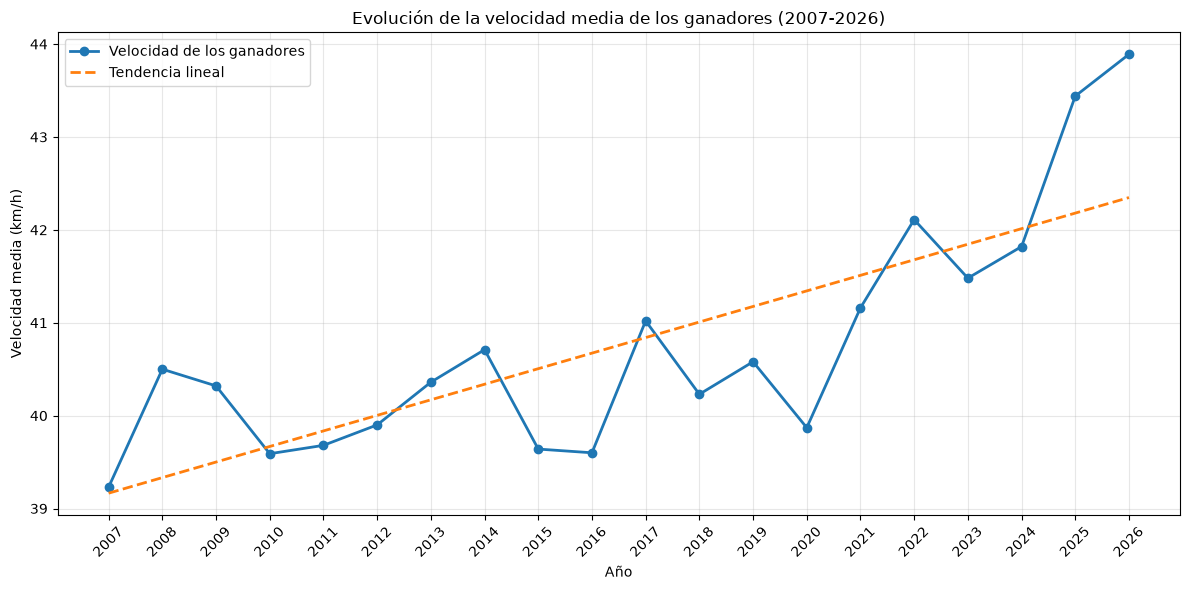


Archivo guardado correctamente.
ANALISIS COMPLEMENTARIO 01 COMPLETADO


In [172]:

# ==========================================================
# ANALISIS COMPLEMENTARIO 01: VELOCIDAD DE LOS GANADORES
# HIPOTESIS H1 | TOUR DE FRANCIA 2007-2026
# ==========================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path

Path("data").mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# 1. PREPARACION DE DATOS
# ----------------------------------------------------------

datos = df_eda.copy()

datos["Year"] = pd.to_numeric(datos["Year"], errors="coerce")
datos["Rank"] = pd.to_numeric(datos["Rank"], errors="coerce")
datos["Speed_kmh"] = pd.to_numeric(
    datos["Speed_kmh"], errors="coerce"
)

datos = datos.dropna(
    subset=["Year", "Rank", "Speed_kmh"]
)

# Seleccionar ganadores
ganadores = datos[
    (datos["Rank"] == 1) &
    (datos["Year"].between(2007, 2026))
].copy()

ganadores = ganadores.sort_values("Year")

# ----------------------------------------------------------
# 2. VALIDACION
# ----------------------------------------------------------

print("========== VALIDACION DE GANADORES ==========")

print("Ediciones analizadas:", ganadores["Year"].nunique())
print("Registros:", len(ganadores))
print("Ganadores duplicados por edición:",
      ganadores["Year"].duplicated().sum())

if ganadores["Year"].duplicated().any():
    raise ValueError("Hay más de un ganador por edición.")

if len(ganadores) < 3:
    raise ValueError("No hay suficientes ediciones para el modelo.")

display(
    ganadores[["Year", "Rider", "Speed_kmh"]]
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# 3. ESTADISTICA DESCRIPTIVA
# ----------------------------------------------------------

resumen = ganadores["Speed_kmh"].describe()

print("\n========== ESTADISTICA DESCRIPTIVA ==========")
display(resumen.round(3))

# ----------------------------------------------------------
# 4. MODELO DE TENDENCIA TEMPORAL
# ----------------------------------------------------------

ganadores["Year_c"] = ganadores["Year"] - ganadores["Year"].mean()

X = sm.add_constant(ganadores["Year_c"])
y = ganadores["Speed_kmh"]

modelo = sm.OLS(y, X).fit(cov_type="HC3")

print("\n========== REGRESION LINEAL ==========")
print(modelo.summary())

# ----------------------------------------------------------
# 5. EVALUACION DE HIPOTESIS
# ----------------------------------------------------------

coeficiente = modelo.params["Year_c"]
p_bilateral = modelo.pvalues["Year_c"]

# Contraste unilateral: H1 plantea una tendencia creciente
if coeficiente > 0:
    p_unilateral = p_bilateral / 2
else:
    p_unilateral = 1 - p_bilateral / 2

ic = modelo.conf_int().loc["Year_c"]

print("\n========== RESULTADO H1 ==========")

print(f"Tendencia anual: {coeficiente:.4f} km/h")
print(f"Valor p bilateral: {p_bilateral:.4f}")
print(f"Valor p unilateral: {p_unilateral:.4f}")
print(f"IC 95%: [{ic.iloc[0]:.4f}, {ic.iloc[1]:.4f}]")
print(f"R²: {modelo.rsquared:.4f}")

if coeficiente > 0 and p_unilateral < 0.05:
    decision = "EVIDENCIA A FAVOR DE H1"
elif coeficiente <= 0 and p_bilateral < 0.05:
    decision = "EVIDENCIA CONTRARIA A H1"
else:
    decision = "EVIDENCIA INSUFICIENTE PARA H1"

print("\nDECISION:", decision)

# ----------------------------------------------------------
# 6. GRAFICO DE EVOLUCION
# ----------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    ganadores["Year"],
    ganadores["Speed_kmh"],
    marker="o",
    linewidth=2,
    label="Velocidad de los ganadores"
)

prediccion = modelo.predict(X)

plt.plot(
    ganadores["Year"],
    prediccion,
    linestyle="--",
    linewidth=2,
    label="Tendencia lineal"
)

plt.title(
    "Evolución de la velocidad media de los ganadores "
    "(2007-2026)"
)

plt.xlabel("Año")
plt.ylabel("Velocidad media (km/h)")
plt.xticks(ganadores["Year"], rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 7. GUARDAR RESULTADOS
# ----------------------------------------------------------

ganadores.to_csv(
    "data/velocidad_ganadores_2007_2026.csv",
    index=False
)

print("\nArchivo guardado correctamente.")
print("ANALISIS COMPLEMENTARIO 01 COMPLETADO")


### Interpretacion
El análisis de la velocidad media de los ganadores del Tour de Francia durante el periodo 2007-2026 evidencia una tendencia creciente. Mediante un modelo de regresión lineal con errores estándar robustos HC3, se obtuvo un coeficiente temporal positivo de 0,1675 km/h por año, con un valor p inferior a 0,001 y un coeficiente de determinación de 0,613. Estos resultados proporcionan evidencia estadísticamente significativa a favor de la hipótesis de que la velocidad media de los ganadores ha aumentado a lo largo del periodo estudiado. No obstante, esta tendencia debe interpretarse considerando que las características de los recorridos y las condiciones de competición pueden variar entre ediciones.